### 1. Load libraries

In [35]:
import numpy as np
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
from processing import ExperimentalValidation
from processing.database import references

### 2. Analysis of raw data

In [36]:
phi_data = ExperimentalValidation(path_to_data=r'C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\raw_lle_data.xlsx', 
                                            component_list=['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER'], 
                                            column_list_to_remove=['Ref', 'Sub Ref', 'Temperature (K)', 'Type Alcohol'],
                                            error_threshold=0.20).calculate_phi()


##### 2.1 General analysis of the database

In [37]:
references_tuple = [(key, value[0], value[1]) for key, value in references.items()]
references_df = pl.DataFrame(references_tuple, schema=["Ref", "Paper", "Oil"])

C:\Users\USER\AppData\Local\Temp\ipykernel_42184\3456677016.py:2: DataOrientationWarning: Row orientation inferred during DataFrame construction. Explicitly specify the orientation by passing `orient="row"` to silence this warning.
  references_df = pl.DataFrame(references_tuple, schema=["Ref", "Paper", "Oil"])


In [38]:
references_df.shape[0]

84

In [39]:
references_df.select(pl.col('Oil')).unique().shape[0]

53

In [40]:
tie_lines_per_reference = phi_data.group_by('Ref').len().sort(by='Ref').select('len').mean()
tie_lines_per_reference

len
f64
25.736842


In [41]:
tie_lines_per_subreference = phi_data.group_by(['Ref', 'Sub Ref']).len().sort(by='Ref').select('len').mean()
tie_lines_per_subreference

len
f64
10.330986


In [42]:
temperature_range = phi_data.select('Temperature (K)').max() - phi_data.select('Temperature (K)').min()
temperature_range

Temperature (K)
f64
70.0


In [43]:
temperature_tie_lines = phi_data.group_by('Temperature (K)').len().sort(by='Temperature (K)')

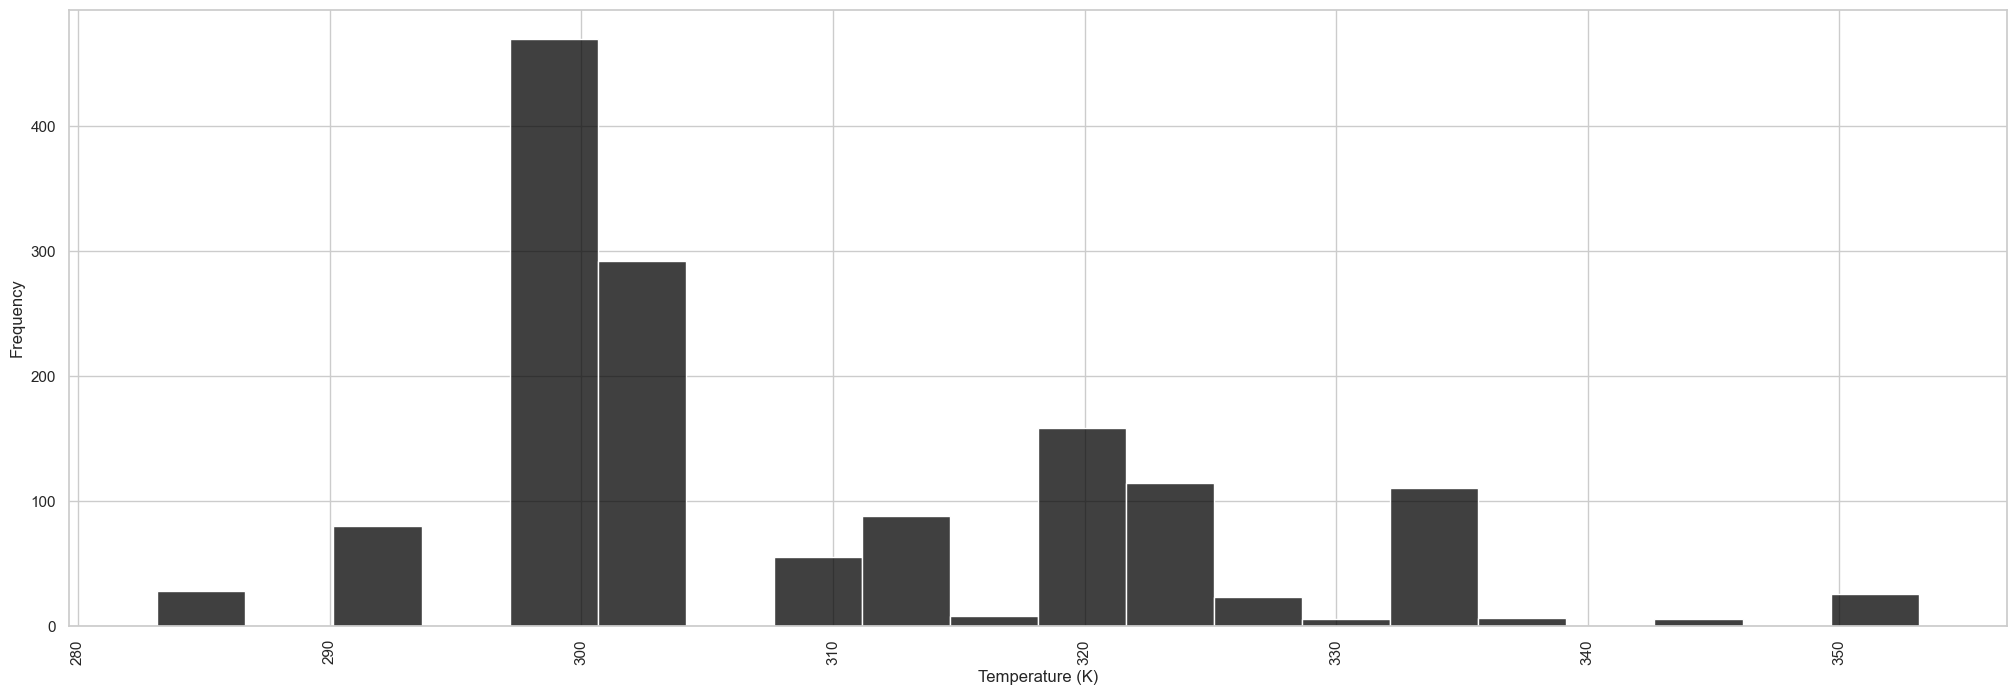

In [44]:
sns.histplot(data = phi_data, x = 'Temperature (K)', color = 'black').set(ylabel = 'Frequency')
plt.xticks(rotation = 90)
plt.show()

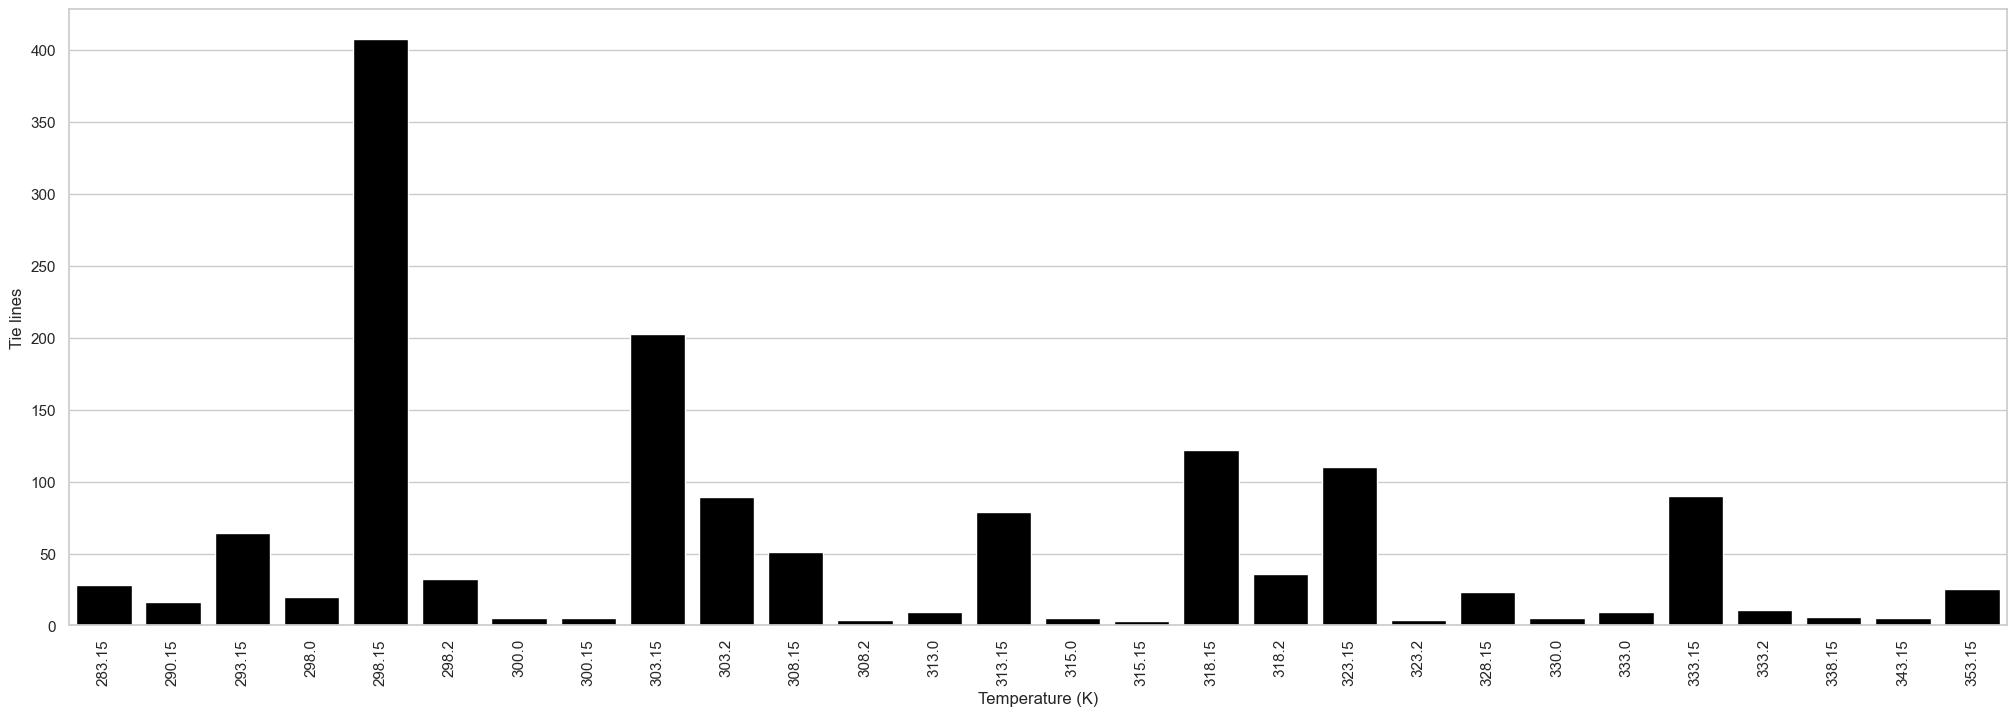

In [45]:
sns.barplot(data = temperature_tie_lines, x = 'Temperature (K)', y = 'len', color='black').set(ylabel='Tie lines')
plt.xticks(rotation = 90)
plt.show()

In [46]:
tie_lines_per_alcohol = phi_data.group_by('Type Alcohol').len().sort(by='Type Alcohol')
tie_lines_per_alcohol

Type Alcohol,len
i64,u32
0,46
1,431
2,966
3,6
4,18


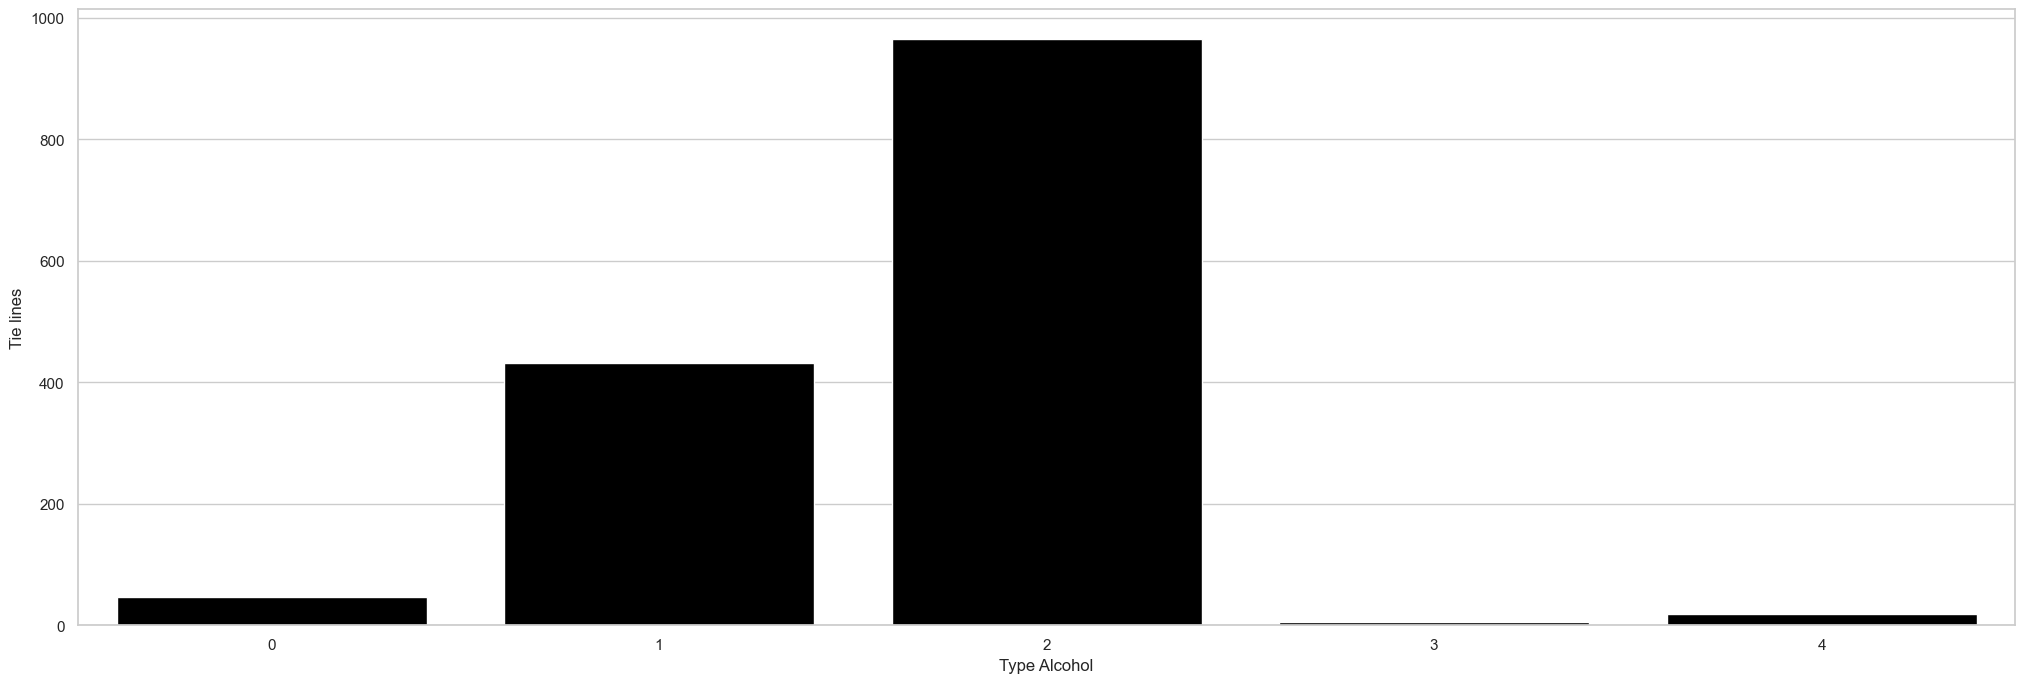

In [47]:
sns.barplot(data = tie_lines_per_alcohol, x = 'Type Alcohol', y = 'len', color='black').set(ylabel='Tie lines')
plt.show()

In [48]:
columns_to_select = ['phi_FAME/FAEE', 'phi_GLYCEROL', 'phi_ALCOHOL', 'phi_OIL', 'phi_DAG', 'phi_MAG', 'phi_ACID','phi_WATER']

In [49]:
def mean_excluding_zeros(row):
    non_zero_values = [val for val in row if val != 0]
    if not non_zero_values:
        return None  # or return float('nan') if you prefer NaN
    return sum(non_zero_values) / len(non_zero_values)
    
def absolute_errors(row, mean):
    return [abs(val - mean) if val != 0 else None for val in row]

def mean_non_null(values):
    non_null_values = [val for val in values if val is not None]
    if not non_null_values:
        return None  # or return float('nan') if you prefer NaN
    return sum(non_null_values) / len(non_null_values)

In [50]:
experimental_phi = phi_data.with_columns(
    pl.concat_list(columns_to_select).map_elements(mean_excluding_zeros, return_dtype= float).alias('Experimental mean phi')
)

df = experimental_phi.with_columns(
    pl.concat_list(columns_to_select).map_elements(
        lambda row: absolute_errors(row, mean_excluding_zeros(row)),
    return_dtype=list[float]).alias('abs_errors')
)

df = df.with_columns(
    df['abs_errors'].map_elements(mean_non_null, return_dtype=float).alias('average_absolute_error')
)


##### 2.2 Statistical analysis of the data

In [51]:

df.describe()

statistic,index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER,Experimental mean phi,abs_errors,average_absolute_error
str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1467.0,1467.0,"""1467""",1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0,1467.0
"""null_count""",0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",733.0,32.74983,null,308.490048,1.67212,0.178024,0.131576,0.360306,0.240804,0.007254,0.00111,0.023056,0.057538,0.399367,0.005744,0.135025,0.424681,0.001278,0.00068,0.024127,0.009191,0.012275,0.229089,0.580317,0.045971,0.000837,0.001506,0.022334,0.107611,NaN,NaN,NaN,0.278948,-inf,0.020075,NaN,NaN,NaN,null,NaN
"""std""",423.630735,14.862241,null,13.754783,0.604265,0.209426,0.183292,0.160971,0.228252,0.056253,0.006553,0.045024,0.118605,0.440863,0.013351,0.135914,0.408361,0.006648,0.004399,0.04839,0.032124,0.037566,0.314191,0.293656,0.110696,0.004325,0.008787,0.042786,0.217756,NaN,NaN,NaN,0.267055,NaN,0.096718,NaN,NaN,NaN,null,NaN
"""min""",0.0,1.0,"""a""",283.15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-26.542169,-0.160734,-inf,-0.333333,-3.2,-0.008,-inf,null,0.0
"""25%""",367.0,23.0,null,298.15,1.0,0.0,0.0,0.25,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.0578,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.3296,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.379947,0.0,0.0,0.0,0.0,0.0,0.416374,null,0.005922
"""50%""",733.0,35.0,null,303.15,2.0,0.0,0.0,0.4367,0.327,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.1006,0.5813,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.656,0.0031,0.0,0.0,0.0,0.0,0.0,0.0,0.495118,0.444153,0.0,0.0,0.0,0.0,0.495811,null,0.01592
"""75%""",1100.0,45.0,null,318.15,2.0,0.3637,0.3,0.475,0.4695,0.0,0.0,0.0248,0.0607,0.89617,0.00525,0.1711,0.84227,1.0000e-20,1.0000e-20,0.0264,0.0063,0.0121,0.4991,0.8424,0.0461,0.0,0.0,0.0251,0.1104,0.426625,0.377542,0.529954,0.525158,0.0,0.0,0.476923,0.525823,0.543767,null,0.051567
"""max""",1466.0,57.0,"""da""",353.15,4.0,0.8459,0.7764,0.8698,0.6355,0.7005,0.0721,0.2506,0.5564,1.0,0.1471,0.9409,0.976,0.068,0.0572,0.2992,0.4084,0.4581,1.0,0.9949,0.894,0.0485,0.0929,0.2404,0.9999,0.877677,1000.0,inf,1.801711,7.0050e19,0.590909,21.0,0.949069,inf,null,1.8862e19


In [52]:

df.filter((pl.col('Experimental mean phi') > 1) | (pl.col('Experimental mean phi') < 0))

index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER,Experimental mean phi,abs_errors,average_absolute_error
u32,i64,str,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,list[f64],f64
7,2,"""a""",293.15,2,0.4902,0.4768,0.033,0.0,0.0,0.0,0.0,0.0,0.9305,0.0219,0.0476,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0248,0.9309,0.0443,0.0,0.0,0.0,0.0,0.0,0.513857,0.49956,-3.424242,0.0,0.0,0.0,0.0,0.0,-0.803609,"[1.317465, 1.303169, … null]",1.747089
121,8,"""a""",333.15,1,0.4156,0.4249,0.1595,0.0,0.0,0.0,0.0,0.0,0.9901,0.0013,0.0086,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.011,0.9279,0.0611,0.0,0.0,0.0,0.0,0.0,0.413237,0.542845,-1.874286,0.0,0.0,0.0,0.0,0.0,-0.306068,"[0.719305, 0.848913, … null]",1.045478
235,14,"""a""",328.15,1,0.25,0.384,0.366,0.0,0.0,0.0,0.0,0.0,0.5934,0.046,0.3606,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0557,0.5807,0.3636,0.0,0.0,0.0,0.0,0.0,0.361354,0.36787,-0.8,0.0,0.0,0.0,0.0,0.0,-0.023592,"[0.384946, 0.391462, … null]",0.517605
263,17,"""a""",298.15,2,0.669,0.261,0.07,0.0,0.0,0.0,0.0,0.0,0.921,0.011,0.067,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.938,0.062,0.0,0.0,0.0,0.0,0.0,0.726384,0.730313,1.6,0.0,0.0,0.0,0.0,0.0,1.018899,"[0.292515, 0.288586, … null]",0.387401
431,27,"""aa""",318.15,1,0.4995,0.5005,0.0001,0.0,0.0,0.0,0.0,0.0,0.9952,0.0048,0.0001,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0077,0.9923,0.0001,0.0,0.0,0.0,0.0,0.0,0.498025,0.498025,NaN,0.0,0.0,0.0,0.0,0.0,NaN,"[NaN, NaN, … null]",NaN
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
1110,44,"""bb""",298.15,2,0.0,0.0,0.49,0.0,0.4718,0.0,0.0102,0.028,1.0000e-20,1.0000e-20,0.0897,0.8978,1.0000e-20,1.0000e-20,0.0097,0.0028,0.0,0.0,0.9143,0.0466,0.0,0.0,0.0113,0.0278,0.0,0.0,0.514553,-0.054746,4.7180e19,0.0,0.6875,-0.008,9.4360e18,"[null, null, … 9.4360e18]",1.5098e19
1111,44,"""bb""",298.15,2,0.0,0.0,0.4498,0.0,0.5192,0.0,0.0002,0.0308,1.0000e-20,1.0000e-20,0.0836,0.9137,1.0000e-20,1.0000e-20,0.0002,0.0025,0.0,0.0,0.9253,0.0165,0.0,0.0,0.0002,0.058,0.0,0.0,0.564928,-0.018391,5.1920e19,0.0,NaN,0.49009,NaN,"[null, null, … NaN]",NaN
1303,50,"""a""",303.2,2,0.0,0.0,0.499,0.393,0.005,0.0,0.102,0.0,1.0000e-20,1.0000e-20,0.26,0.657,0.006,1.0000e-20,0.078,1.0000e-20,0.0,0.0,0.673,0.193,0.006,0.0,0.129,0.0,0.0,0.0,0.421308,0.431034,-inf,0.0,0.529412,0.0,-inf,"[null, null, … null]",NaN


In [53]:
filtered_phi_df = df.filter((pl.col('Experimental mean phi') <=1) & (pl.col('Experimental mean phi') > 0))
filtered_phi_df.describe()

statistic,index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER,Experimental mean phi,abs_errors,average_absolute_error
str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1413.0,1413.0,"""1413""",1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0
"""null_count""",0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",729.032555,32.605803,null,308.60414,1.661005,0.178883,0.132316,0.360182,0.244741,0.001081,0.001152,0.023134,0.058165,0.402853,0.005801,0.135134,0.420655,0.001323,0.000706,0.024207,0.009415,0.012461,0.229169,0.579437,0.045871,0.000865,0.001563,0.022217,0.108352,0.210027,0.168215,0.444856,0.283201,0.022613,0.020842,0.200244,0.231378,0.476626,null,0.044519
"""std""",425.789228,14.980285,null,13.815078,0.590662,0.208694,0.182492,0.157658,0.22821,0.005528,0.006674,0.045575,0.118561,0.440484,0.013434,0.136128,0.408525,0.006768,0.00448,0.048987,0.032648,0.038159,0.310115,0.289097,0.111877,0.004401,0.008948,0.043114,0.216524,0.237506,0.228083,0.187893,0.262852,0.120434,0.098468,0.320021,0.267577,0.127825,null,0.083489
"""min""",0.0,1.0,"""a""",283.15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.507519,0.0,-0.8125,-0.333333,-1.0,0.0,0.063604,null,0.0
"""25%""",357.0,22.0,null,298.15,1.0,0.0,0.0,0.25,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.0578,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.332,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.379121,0.0,0.0,0.0,0.0,0.0,0.415288,null,0.005415
"""50%""",725.0,35.0,null,303.15,2.0,0.0,0.0,0.4321,0.348,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.1005,0.5786,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.6543,0.003,0.0,0.0,0.0,0.0,0.0,0.0,0.493178,0.461234,0.0,0.0,0.0,0.0,0.492668,null,0.014766
"""75%""",1092.0,45.0,null,318.15,2.0,0.3626,0.3,0.4749,0.4721,0.0,0.0,0.0245,0.061,0.8955,0.0054,0.171,0.84,1.0000e-20,1.0000e-20,0.0253,0.0064,0.0121,0.4991,0.8355,0.0449,0.0,0.0,0.0245,0.114,0.425669,0.37537,0.528979,0.525406,0.0,0.0,0.468354,0.525406,0.538778,null,0.043806
"""max""",1466.0,57.0,"""da""",353.15,4.0,0.8459,0.7764,0.7689,0.6355,0.0586,0.0721,0.2506,0.5564,1.0,0.1471,0.9409,0.976,0.068,0.0572,0.2992,0.4084,0.4581,1.0,0.9949,0.894,0.0485,0.0929,0.2404,0.9999,0.877677,0.874608,2.229878,0.778746,0.888889,0.590909,2.0,0.949069,0.927951,null,0.912044


##### 2.3 Distribution of experimental PHI for each component

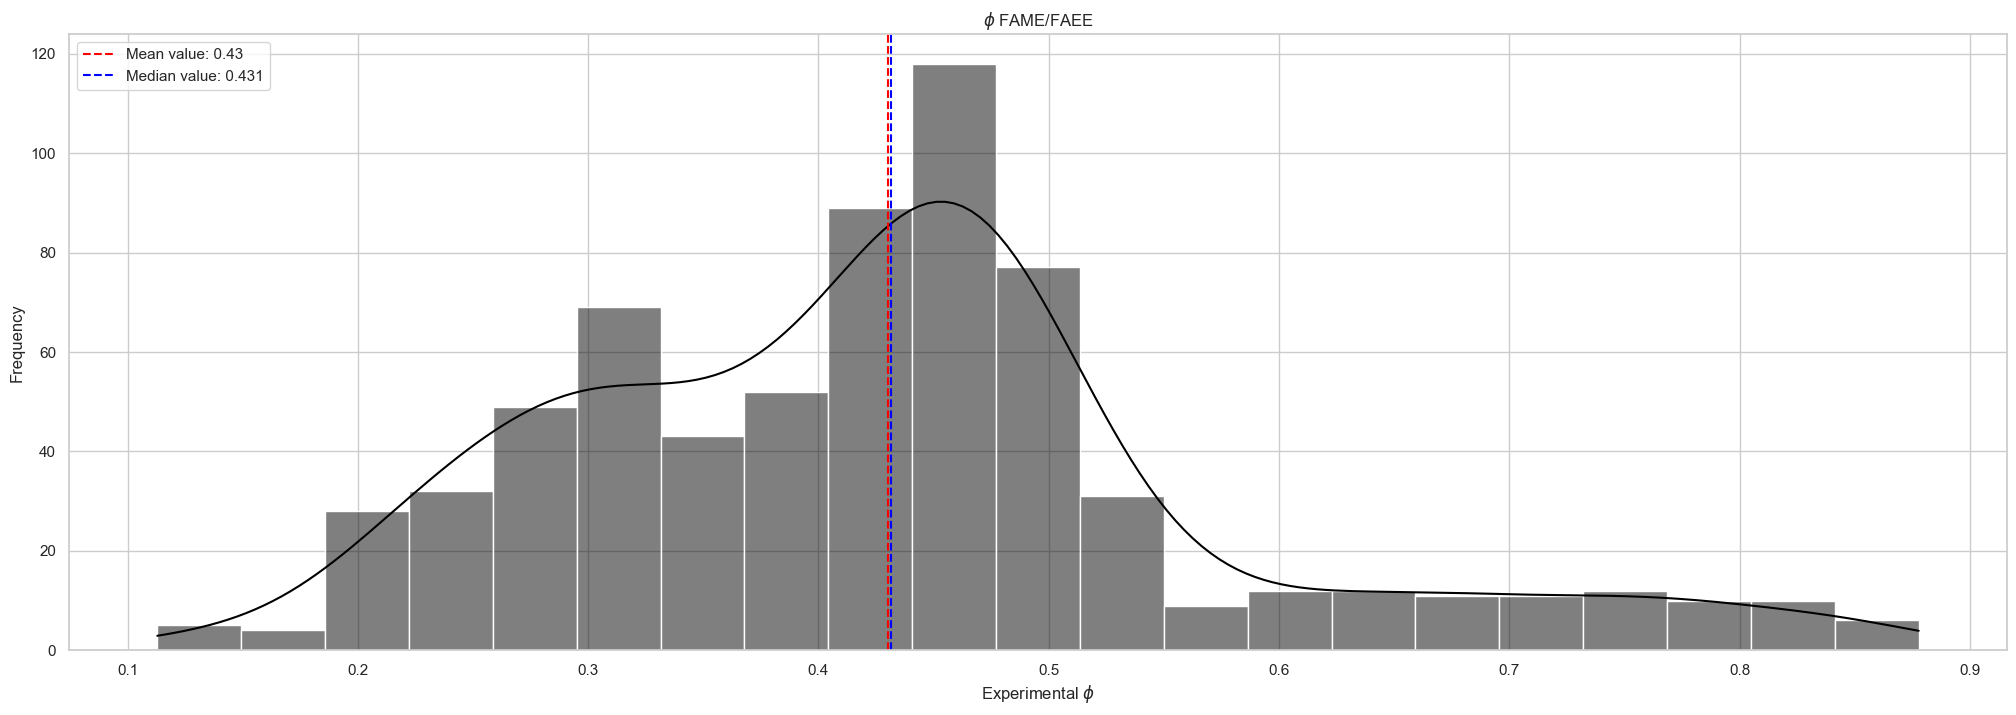

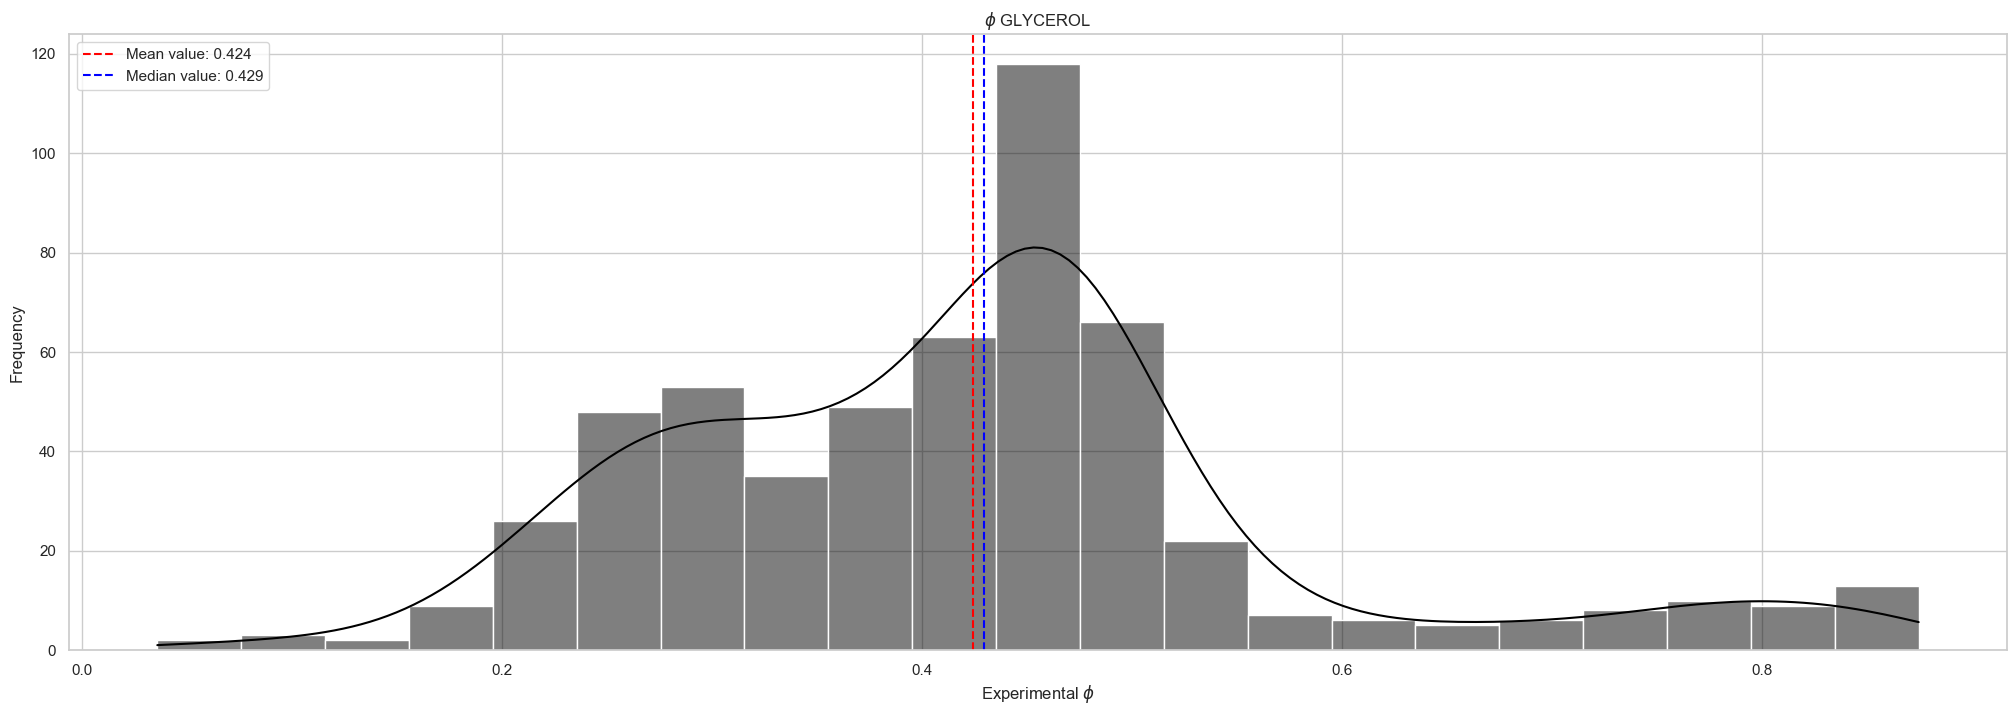

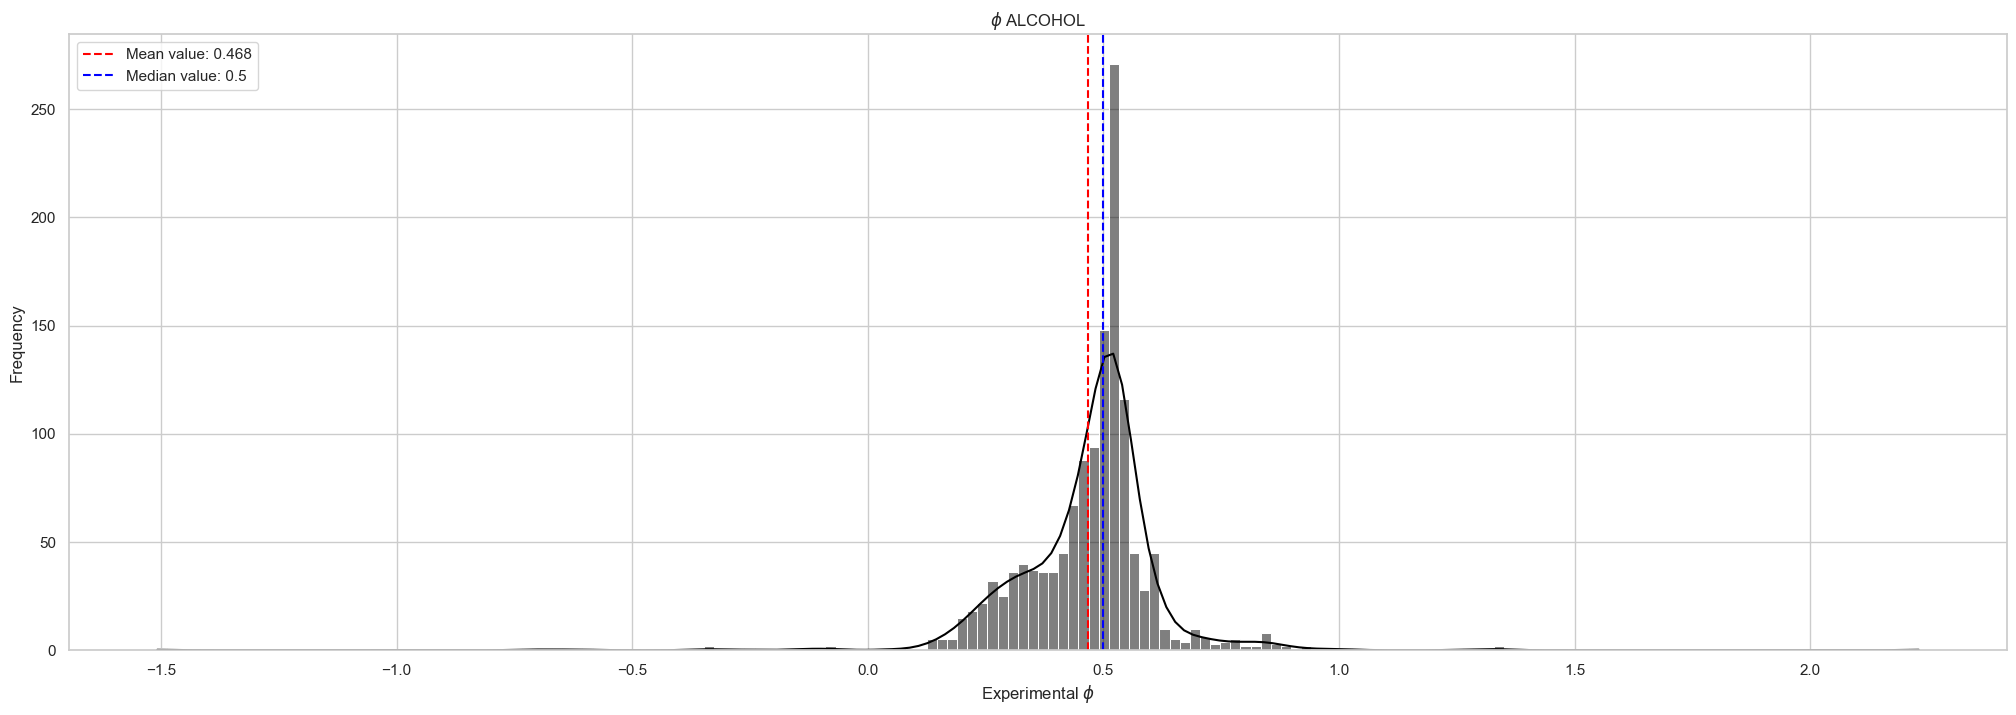

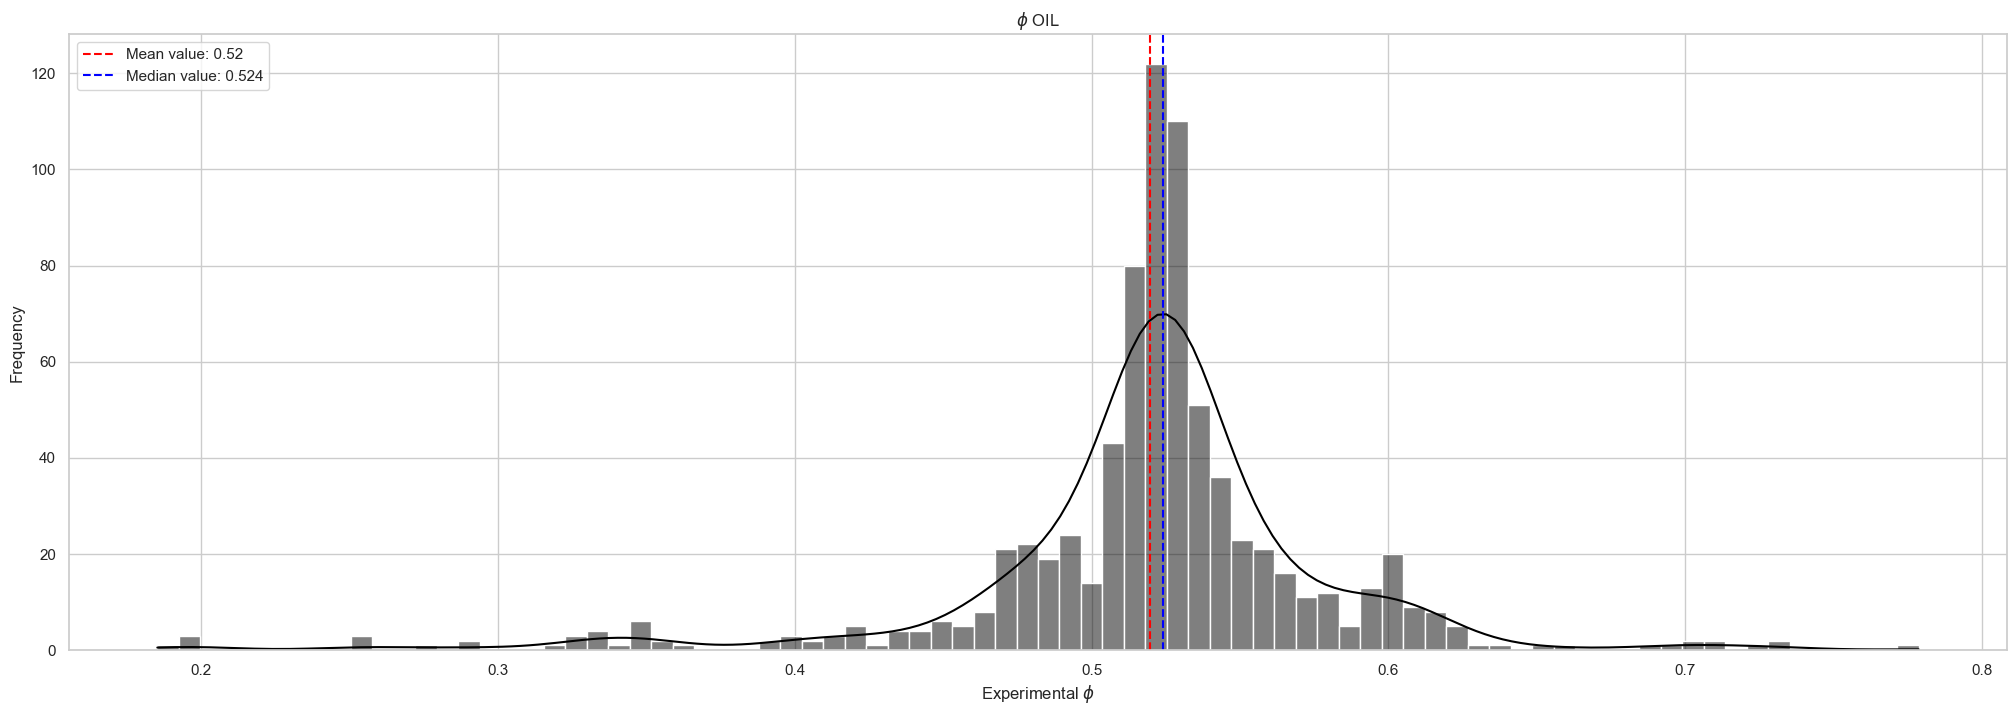

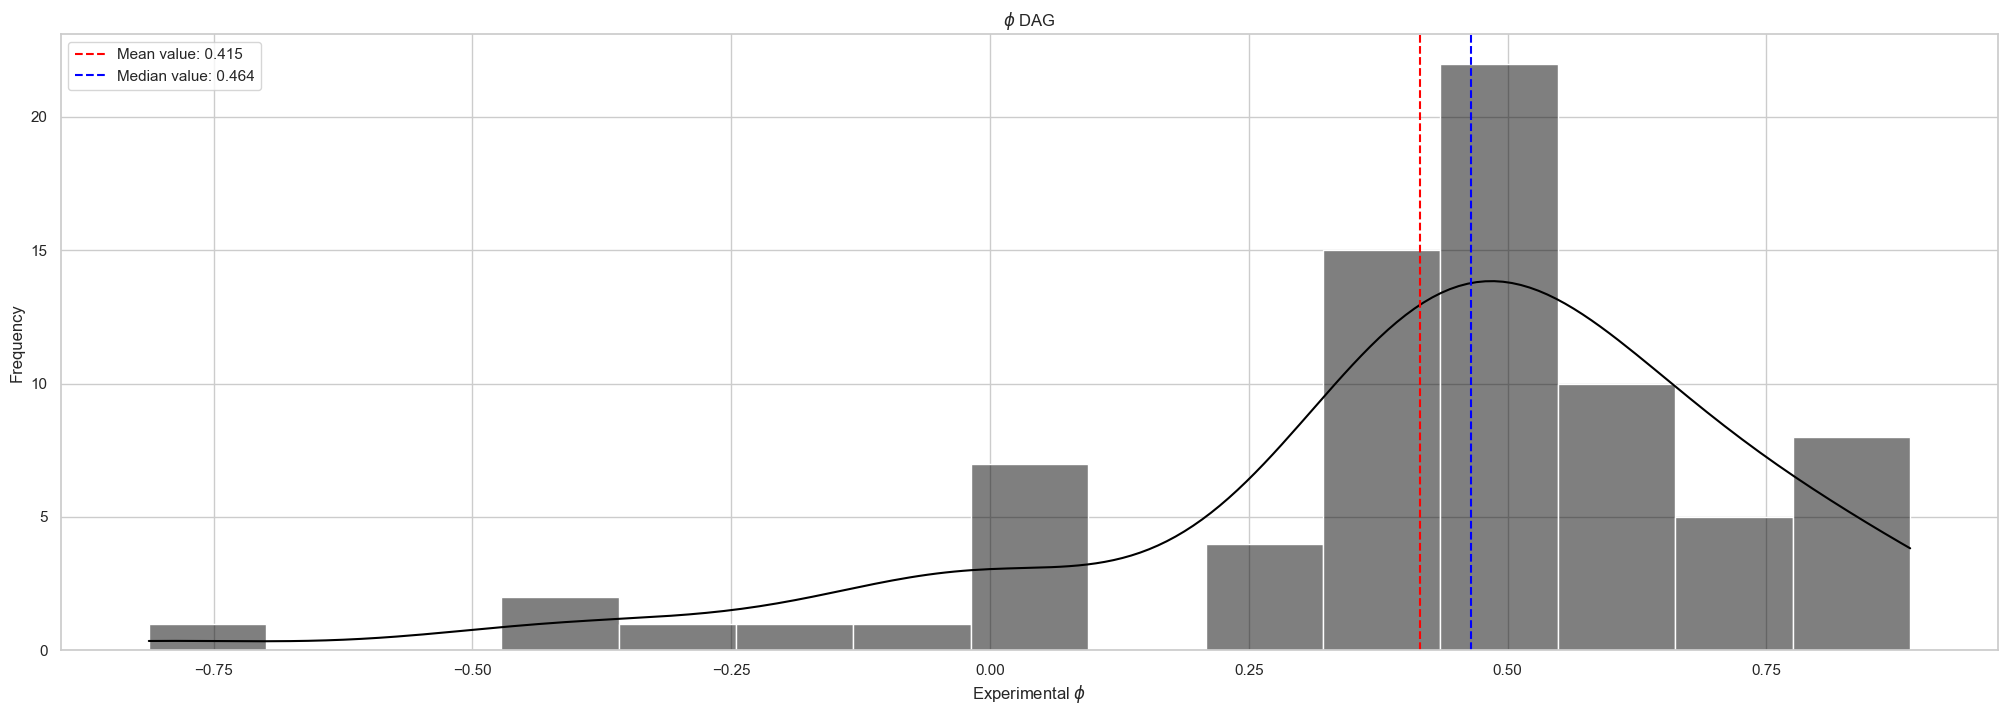

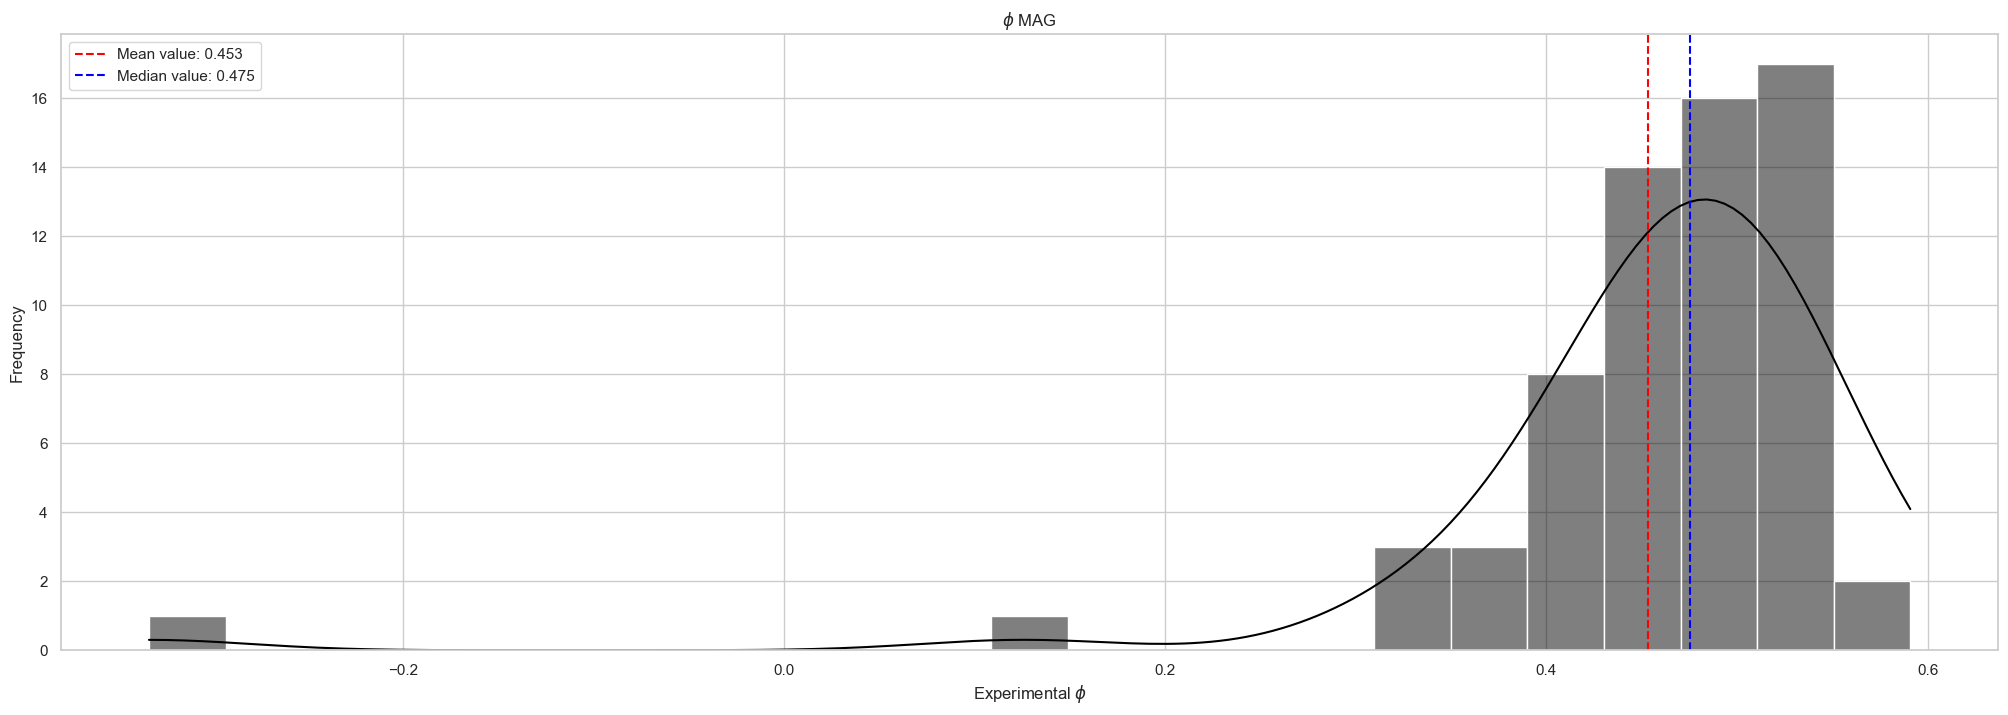

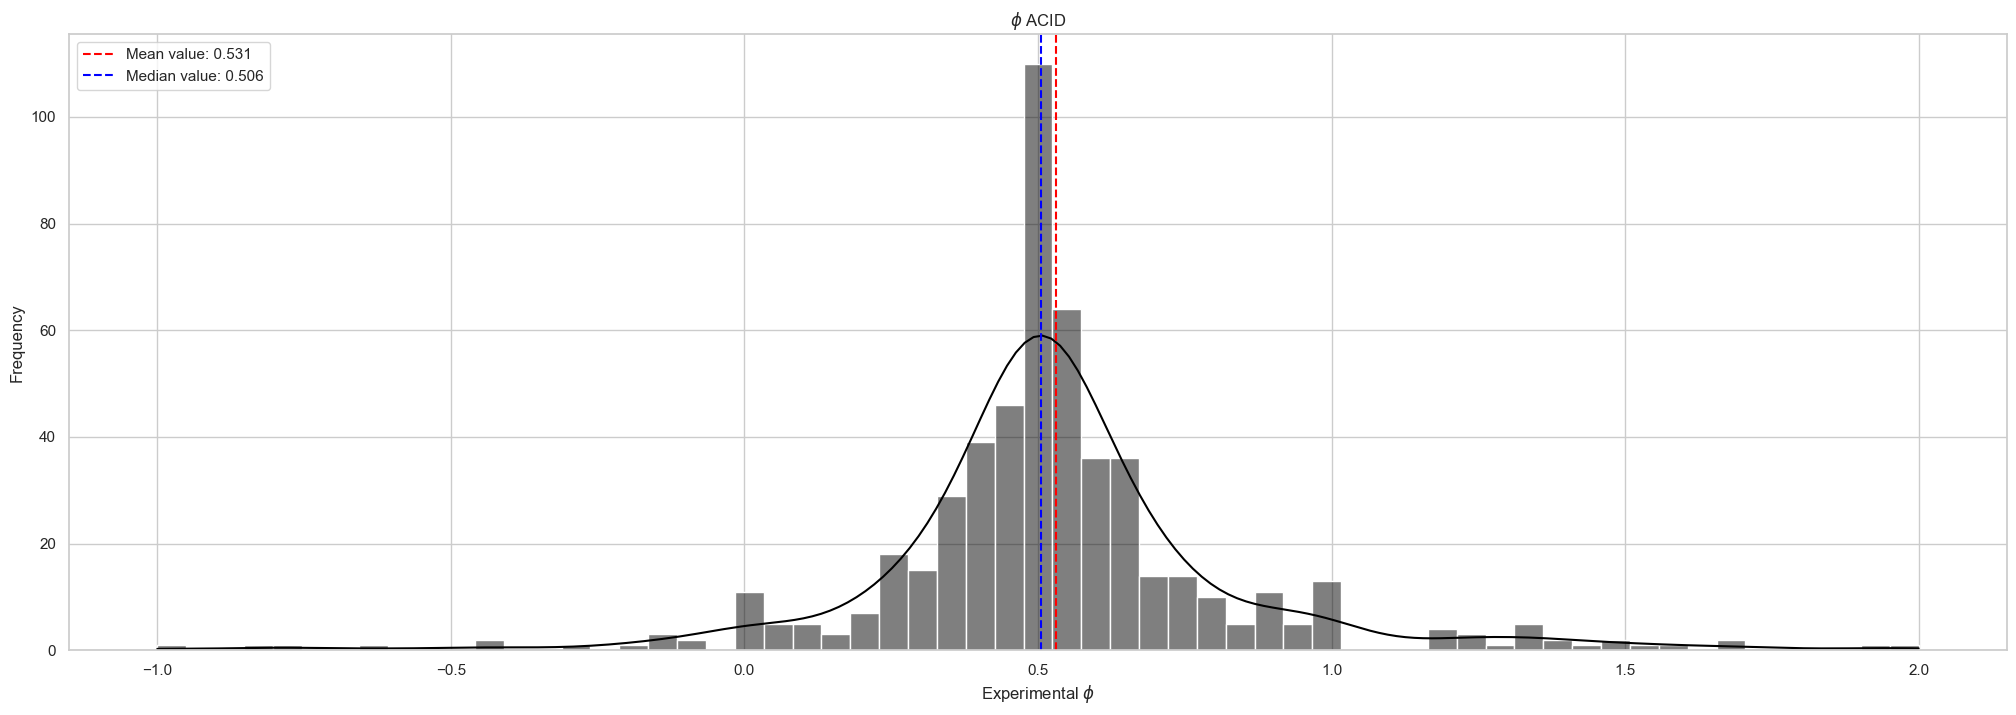

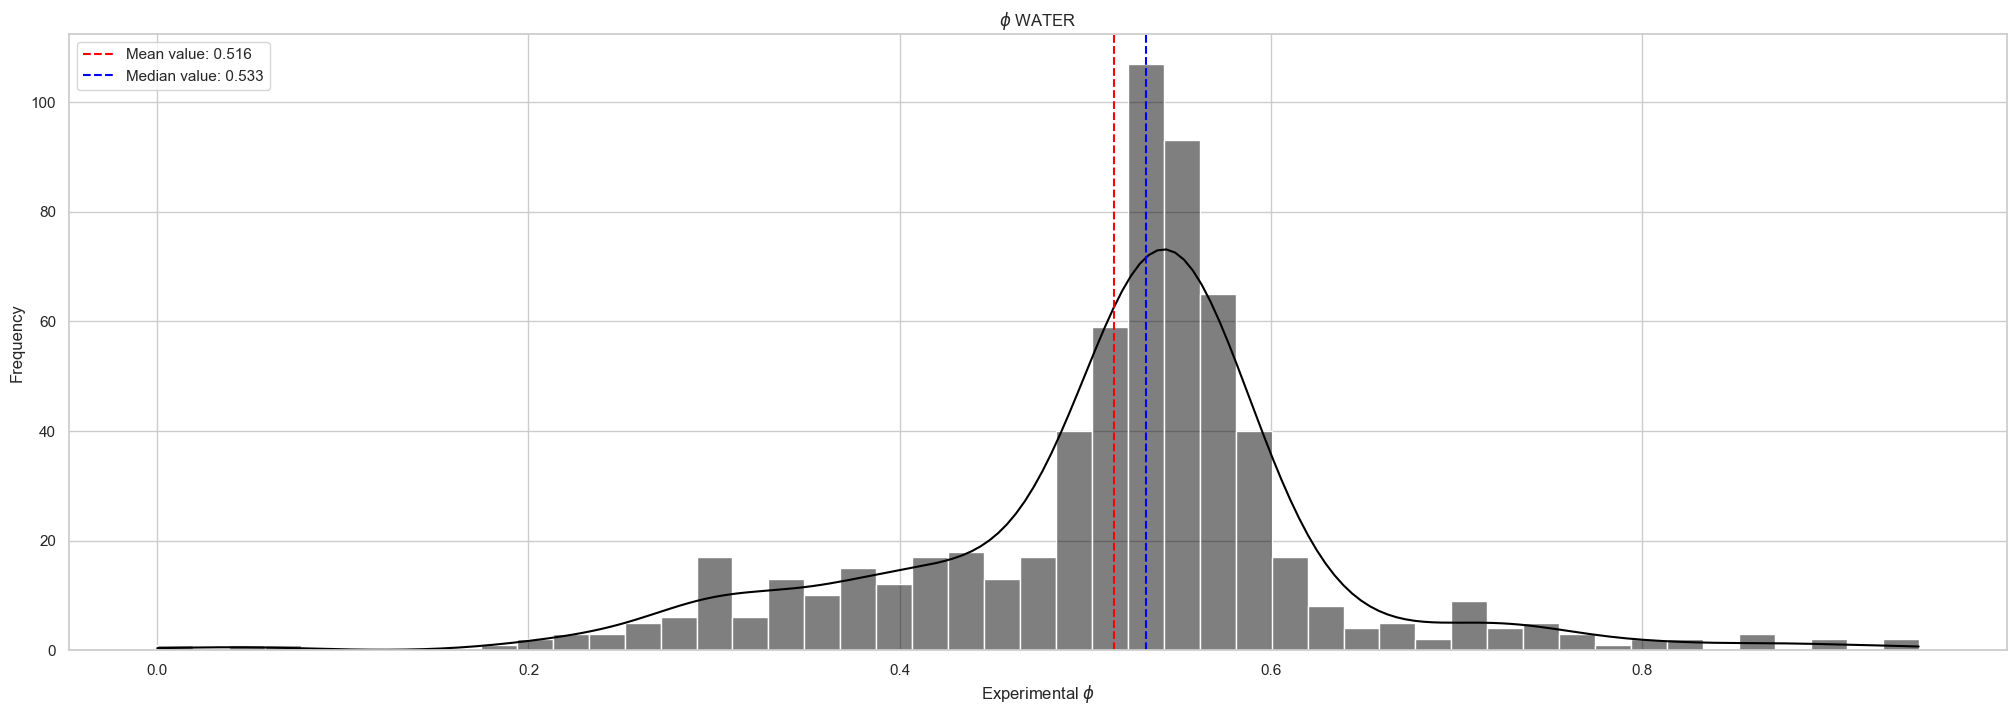

In [54]:
feed_columns = ['FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 'ACID_F', 'WATER_F']
for i in feed_columns:
    plt.figure()
    filter_data = filtered_phi_df.filter(pl.col(i) > 0.0)
    len_data = filter_data.shape[0]
    column_name = 'phi_' + i.rstrip('_F')
    mean_value = filter_data.select(pl.col(column_name)).mean().to_numpy()[0][0]
    median_value = filter_data.select(pl.col(column_name)).median().to_numpy()[0][0]
    sns.histplot(x = filter_data.select(pl.col(column_name)).to_numpy().reshape(len_data), color = 'black', kde=True).set(title=f"$\phi$ {i.rstrip('_F')}", ylabel = 'Frequency', xlabel = 'Experimental $\phi$')
    plt.axvline(mean_value, color = 'red', linestyle = '--',  label = f'Mean value: {round(mean_value, 3)}')
    plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
    plt.legend(loc= 'upper left')
    plt.show()

##### 2.4 Distribution of mean experimental phi per tie line

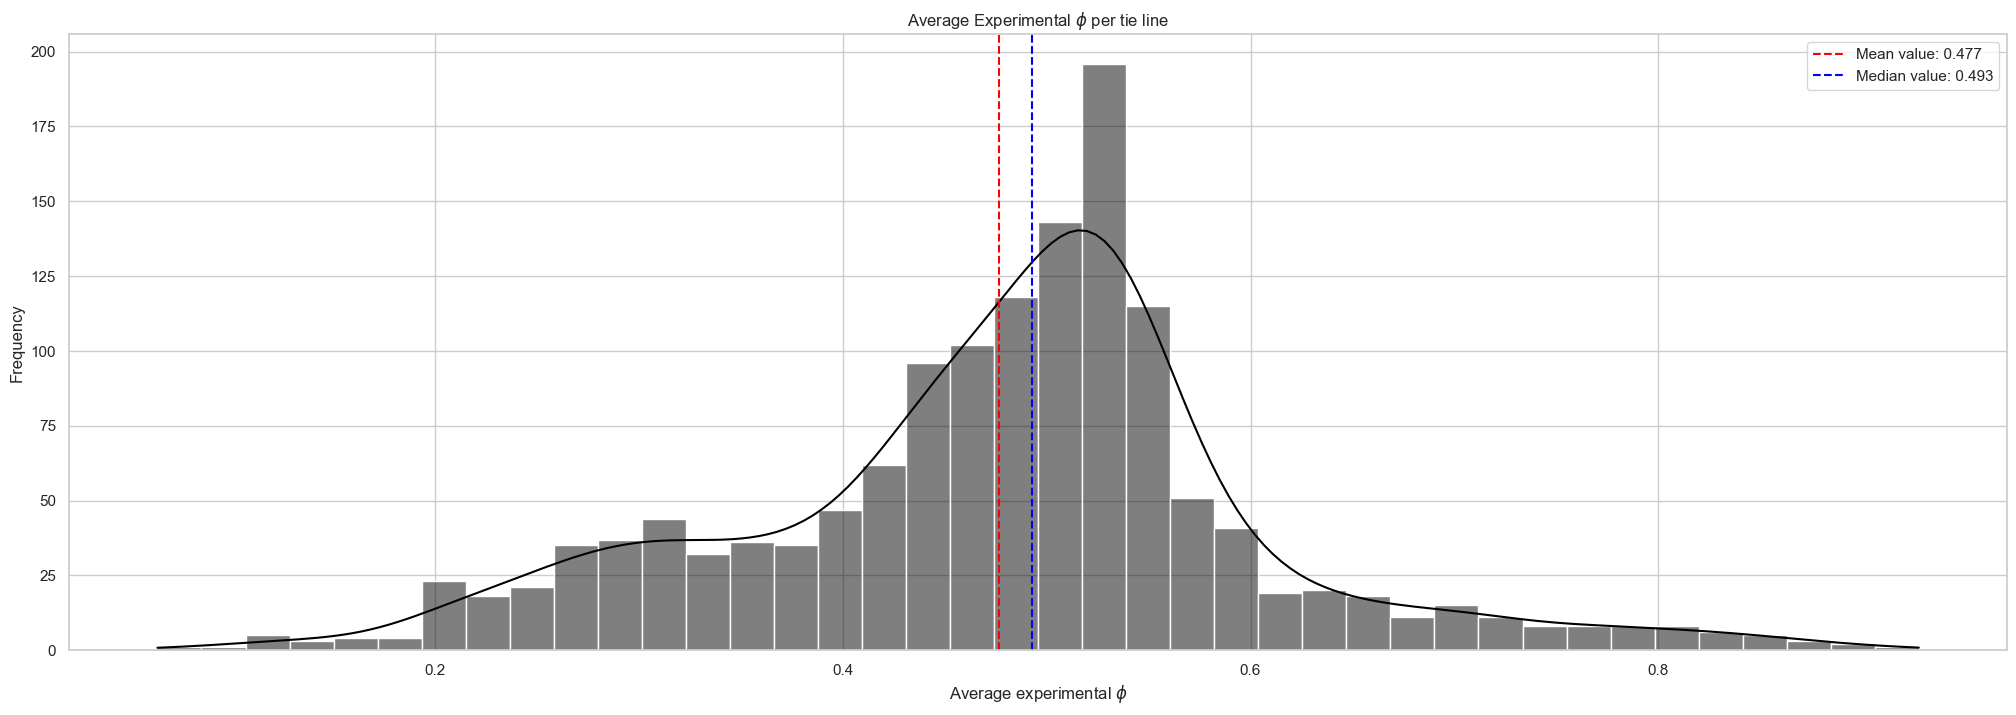

In [55]:
mean_value = filtered_phi_df.select(pl.col('Experimental mean phi')).mean().to_numpy()[0][0]
median_value = filtered_phi_df.select(pl.col('Experimental mean phi')).median().to_numpy()[0][0]
sns.histplot(x = filtered_phi_df.select(pl.col('Experimental mean phi')).to_numpy().reshape(1413), kde = True, color='black').set(title = f'Average Experimental $\phi$ per tie line',  ylabel = 'Frequency', xlabel = 'Average experimental $\phi$')
plt.axvline(mean_value, color = 'red', linestyle = '--', label = f'Mean value: {round(mean_value, 3)}')
plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
plt.legend()
plt.show()

##### 2.5 Distribution of average absolute error between the tie line experimental mean phi and each component phi 

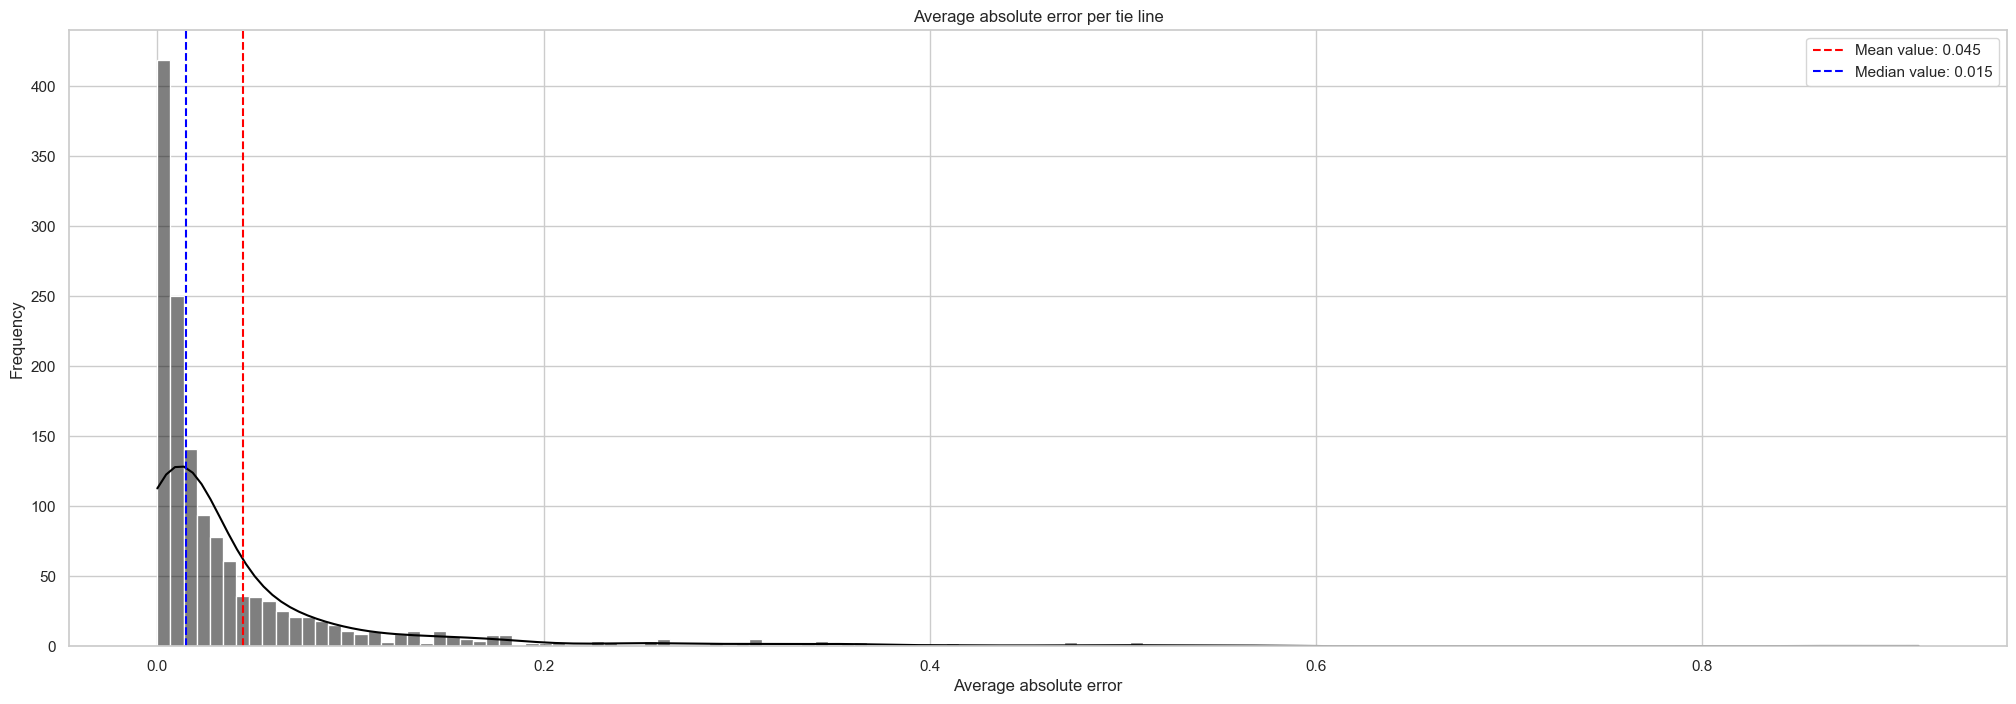

In [56]:
mean_value = filtered_phi_df.select(pl.col('average_absolute_error')).mean().to_numpy()[0][0]
median_value = filtered_phi_df.select(pl.col('average_absolute_error')).median().to_numpy()[0][0]
sns.histplot(x = filtered_phi_df.select(pl.col('average_absolute_error')).to_numpy().reshape(1413), kde = True, color='black').set(title = f'Average absolute error per tie line',  ylabel = 'Frequency', xlabel = 'Average absolute error')
plt.axvline(mean_value, color = 'red', linestyle = '--', label = f'Mean value: {round(mean_value, 3)}')
plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
plt.legend()
plt.show()

### 3.Analysis of refined data

In [57]:
thresholds = [0.05, 0.1, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.5, 0.55, 0.65, 0.70, 0.75]
lengths = []
for i in thresholds:
    validated_data, phi_names = ExperimentalValidation(path_to_data=r'C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\raw_lle_data.xlsx', 
                                            component_list=['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER'], 
                                            column_list_to_remove=['Ref', 'Sub Ref', 'Temperature (K)', 'Type Alcohol'],
                                            error_threshold=i).validate_data()
    lengths.append(validated_data.shape[0])
    
    

##### 3.1 Effect of error threshold on filtered data

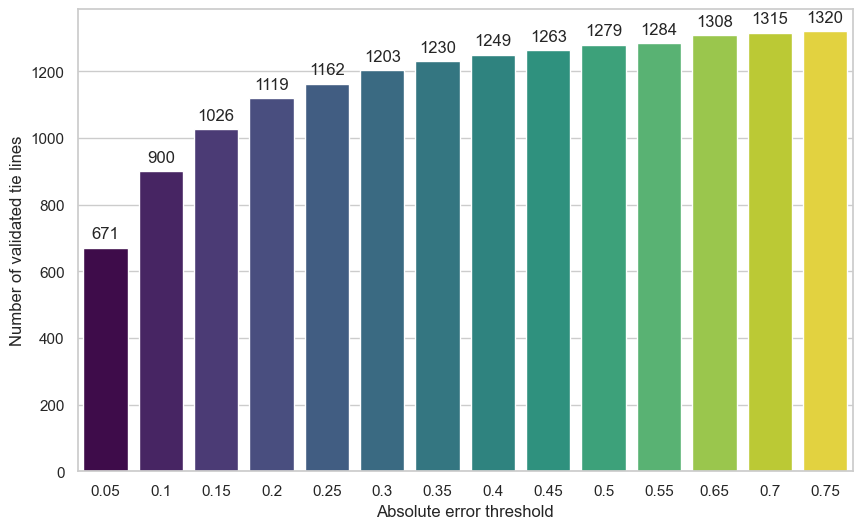

In [58]:
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=thresholds, y=lengths, palette='viridis', hue=thresholds, legend=False)

# Annotate the bars with the values
for p in ax.patches:
    ax.annotate(f'{p.get_height():.0f}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 10), 
                textcoords='offset points')

# Set labels and title
ax.set_xlabel('Absolute error threshold')
ax.set_ylabel('Number of validated tie lines')

# Show the plot
plt.show()

##### 3.2 Statistical analysis of reconciled data and distribution of reconciled phi

In [59]:

refined_data = (pl.read_excel('data/refined_lle_data.xlsx', engine='calamine')).with_row_index()

In [60]:
refined_data.describe()

statistic,index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,Reconcile phi
str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1134.0,1134.0,"""1134""",1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0
"""null_count""",0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",566.5,31.878307,null,309.105203,1.609347,0.199485,0.148404,0.346987,0.220218,0.000683,0.000864,0.019264,0.064108,0.452862,0.007155,0.132847,0.376041,0.000796,0.000584,0.020479,0.01025,0.014076,0.254724,0.55037,0.044347,0.000538,0.001194,0.017999,0.116134,0.466491
"""std""",327.501908,15.471958,null,14.219168,0.625962,0.20901,0.186103,0.160127,0.229754,0.005048,0.006757,0.042645,0.128603,0.443203,0.023227,0.145449,0.411869,0.005922,0.004775,0.046833,0.036499,0.042073,0.314169,0.290997,0.121021,0.004028,0.009163,0.039578,0.232617,0.117204
"""min""",0.0,1.0,"""a""",283.15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.111857
"""25%""",283.0,20.0,null,298.15,1.0,0.0,0.0,0.219,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.057055,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.304225,0.0,0.0,0.0,0.0,0.0,0.410645
"""50%""",567.0,34.0,null,303.15,2.0,0.2031,0.0,0.4024,0.0,0.0,0.0,0.0,0.0,0.653,0.0,0.096617,0.0,0.0,0.0,0.0,0.0,0.00001,0.0,0.60714,0.0,0.0,0.0,0.0,0.0,0.488027
"""75%""",850.0,46.0,null,318.15,2.0,0.3899,0.3275,0.4749,0.4693,0.0,0.0,0.0163,0.061,0.905043,0.007115,0.1632,0.826171,0.0,0.0,0.016204,0.004577,0.013485,0.539782,0.807624,0.027839,0.0,0.0,0.013529,0.115405,0.526961
"""max""",1133.0,57.0,"""i""",353.15,4.0,0.8459,0.7764,0.7004,0.6355,0.0586,0.0721,0.206,0.5564,1.036587,0.599996,0.941687,0.974168,0.068701,0.057142,0.260358,0.4084,0.455586,0.99999,0.9949,0.897099,0.048558,0.092427,0.206843,0.9999,0.99999


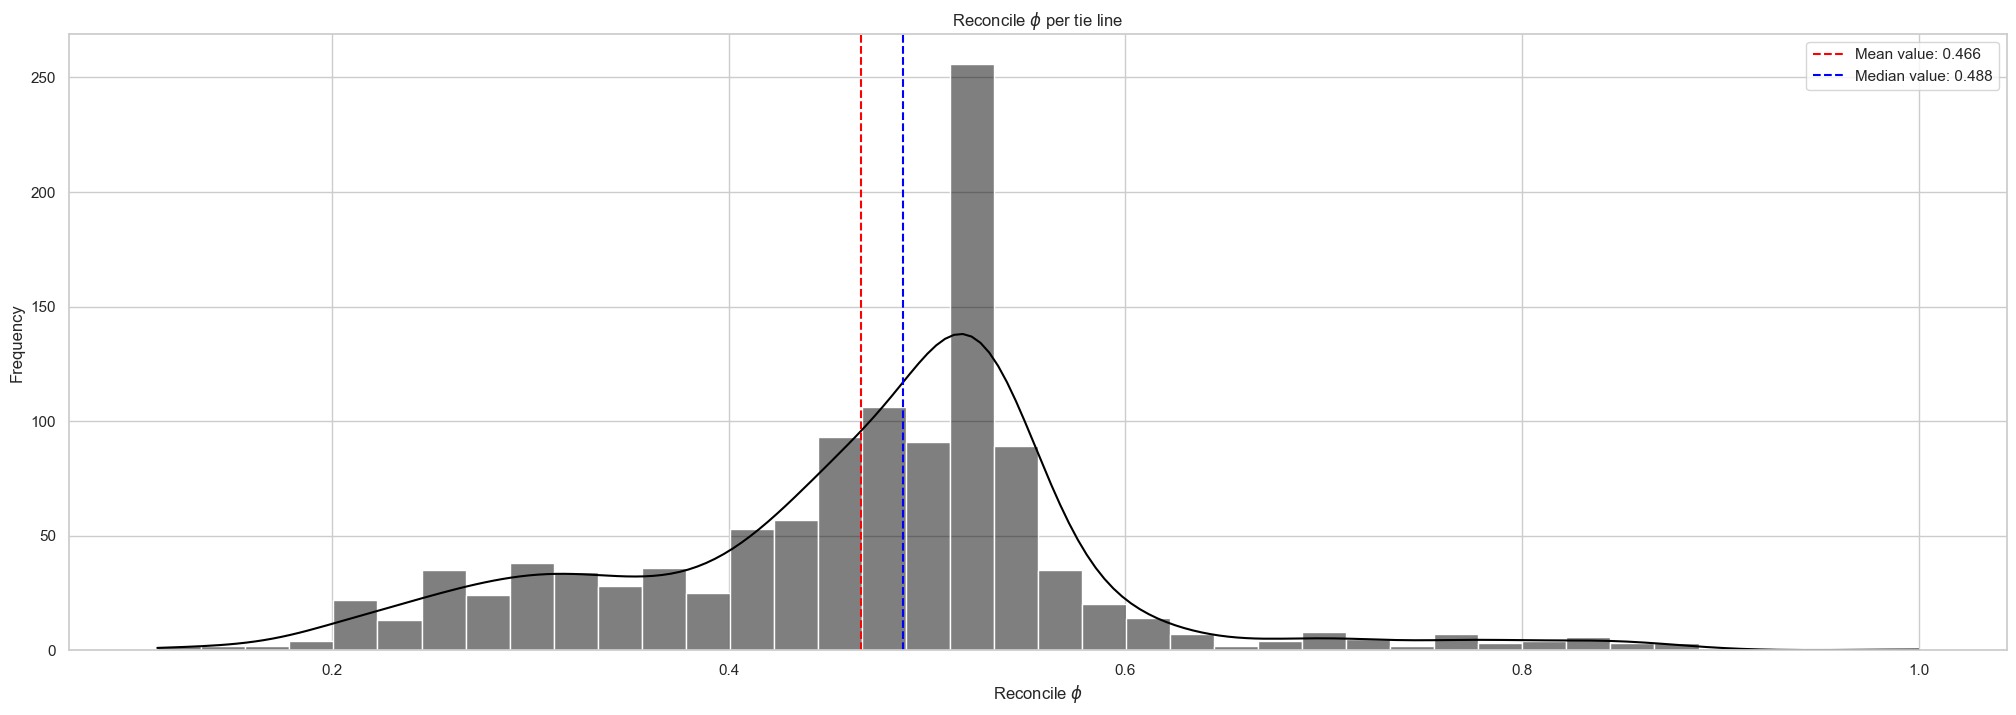

In [61]:
mean_value = refined_data.select(pl.col('Reconcile phi')).mean().to_numpy()[0][0]
median_value = refined_data.select(pl.col('Reconcile phi')).median().to_numpy()[0][0]
sns.histplot(x = refined_data.select(pl.col('Reconcile phi')).to_numpy().reshape(1134), kde = True, color='black').set(title = f'Reconcile $\phi$ per tie line',  ylabel = 'Frequency', xlabel = 'Reconcile $\phi$')
plt.axvline(mean_value, color = 'red', linestyle = '--', label = f'Mean value: {round(mean_value, 3)}')
plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
plt.legend()
plt.show()

In [62]:
refined_experimental_data = refined_data.select(pl.col(['FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 'ACID_F', 'WATER_F',
                                                       'FAME/FAEE_L', 'GLYCEROL_L', 'ALCOHOL_L', 'OIL_L', 'DAG_L', 'MAG_L', 'ACID_L', 'WATER_L', 
                                                       'FAME/FAEE_H', 'GLYCEROL_H', 'ALCOHOL_H', 'OIL_H', 'DAG_H', 'MAG_H', 'ACID_H', 'WATER_H']))

In [63]:

component_list = ['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER']
num_components = 8
refined_experimental_data = refined_experimental_data.with_columns( 
        
            [pl.when(pl.nth(i)==0.0)
            .then(1e-20)
            .otherwise(pl.nth(i))
            .alias(refined_experimental_data.columns[i])
            for i in range(num_components, num_components*2)]   # The parameters in the range function consider the columns with compositions of the light phase  
            
        )
        

In [64]:
refined_experimental_phi = refined_experimental_data.select(
            
            [((pl.nth(i) - pl.nth(i+num_components*2))/(pl.nth(i+num_components) - pl.nth(i+num_components*2)))
            .alias(f'phi_{component_list[i]}') 
            for i in range(0, num_components)]
        ).with_row_index()
        

In [65]:
refined_experimental_phi = refined_experimental_phi.with_columns(
    pl.concat_list(columns_to_select).map_elements(mean_excluding_zeros, return_dtype= float).alias('Experimental mean phi')
)

In [66]:
refined_experimental_data = refined_experimental_data.with_row_index()

In [67]:
refined_total_data = refined_experimental_data.join(refined_experimental_phi, on = 'index')

In [68]:
refined_total_data.filter((pl.col('Experimental mean phi') > 1) | (pl.col('Experimental mean phi') < 0))

index,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER,Experimental mean phi
u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1064,0.0,0.0,0.4704,0.5208,0.0088,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.177716,0.813416,0.0088,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.8999,0.0914,0.0088,0.0,0.0,0.0,0.0,0.0,0.594724,0.594724,NaN,0.0,0.0,0.0,NaN


In [69]:
refined_total_data = refined_total_data.filter(pl.col('index')!= 1064)

In [70]:
refined_total_data = refined_total_data.with_columns(
    pl.concat_list(columns_to_select).map_elements(
        lambda row: absolute_errors(row, mean_excluding_zeros(row)),
    return_dtype=list[float]).alias('abs_errors')
)

refined_total_data = refined_total_data.with_columns(
    refined_total_data['abs_errors'].map_elements(mean_non_null, return_dtype=float).alias('average_absolute_error')
)

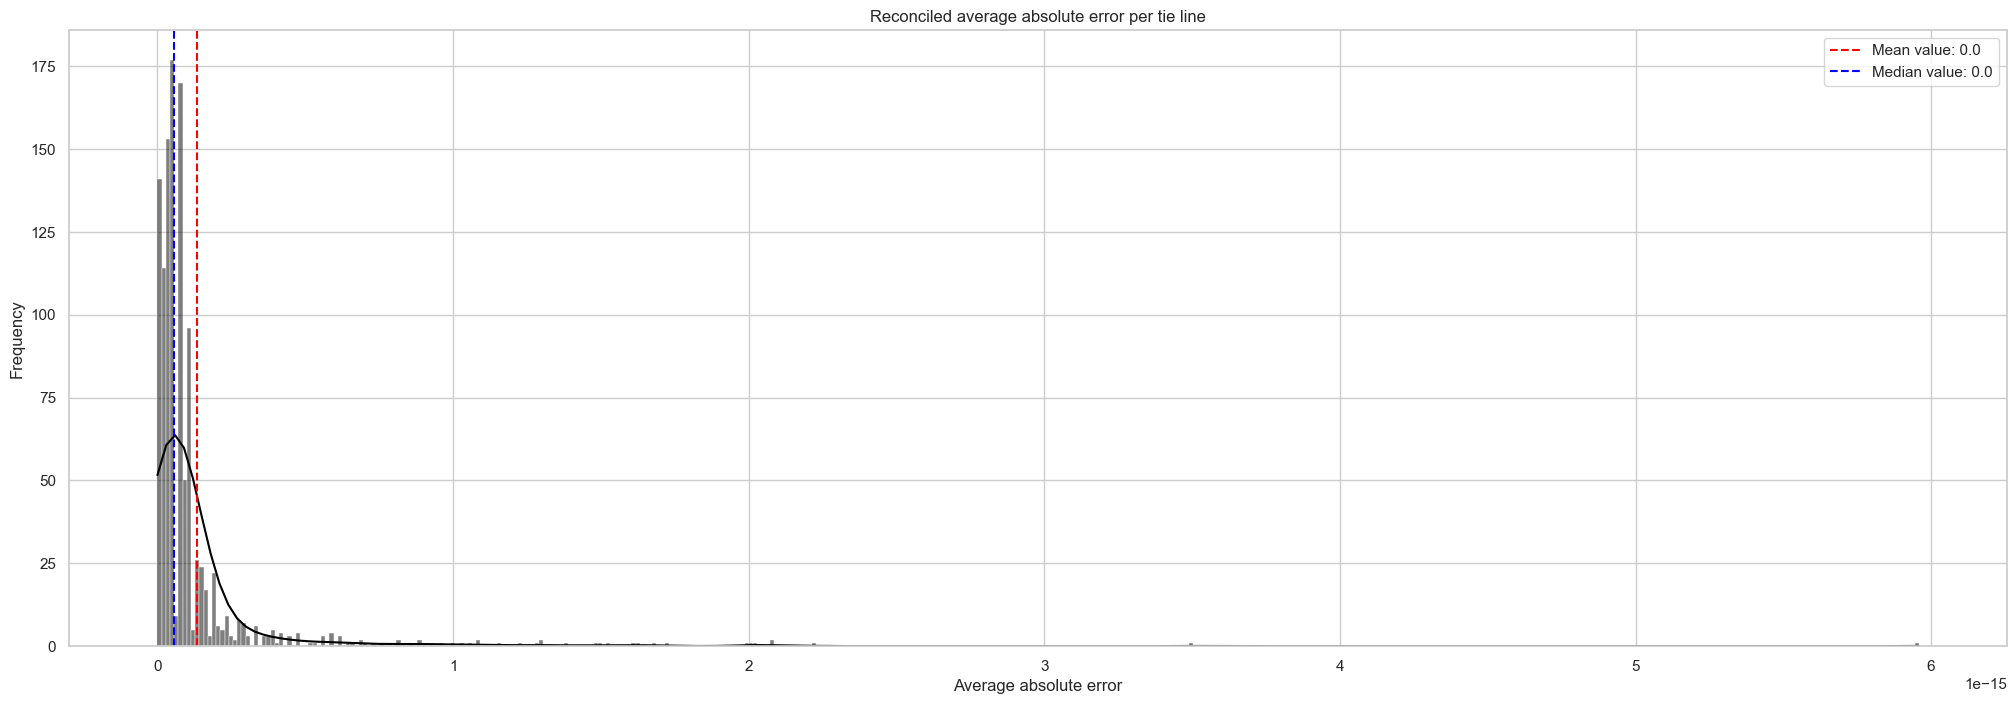

In [71]:
mean_value = refined_total_data.select(pl.col('average_absolute_error')).mean().to_numpy()[0][0]
median_value = refined_total_data.select(pl.col('average_absolute_error')).median().to_numpy()[0][0]
sns.histplot(x = refined_total_data.select(pl.col('average_absolute_error')).to_numpy().reshape(1133), kde = True, color='black').set(title = f'Reconciled average absolute error per tie line',  ylabel = 'Frequency', xlabel = 'Average absolute error')
plt.axvline(mean_value, color = 'red', linestyle = '--', label = f'Mean value: {round(mean_value, 3)}')
plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
plt.legend()
plt.show()

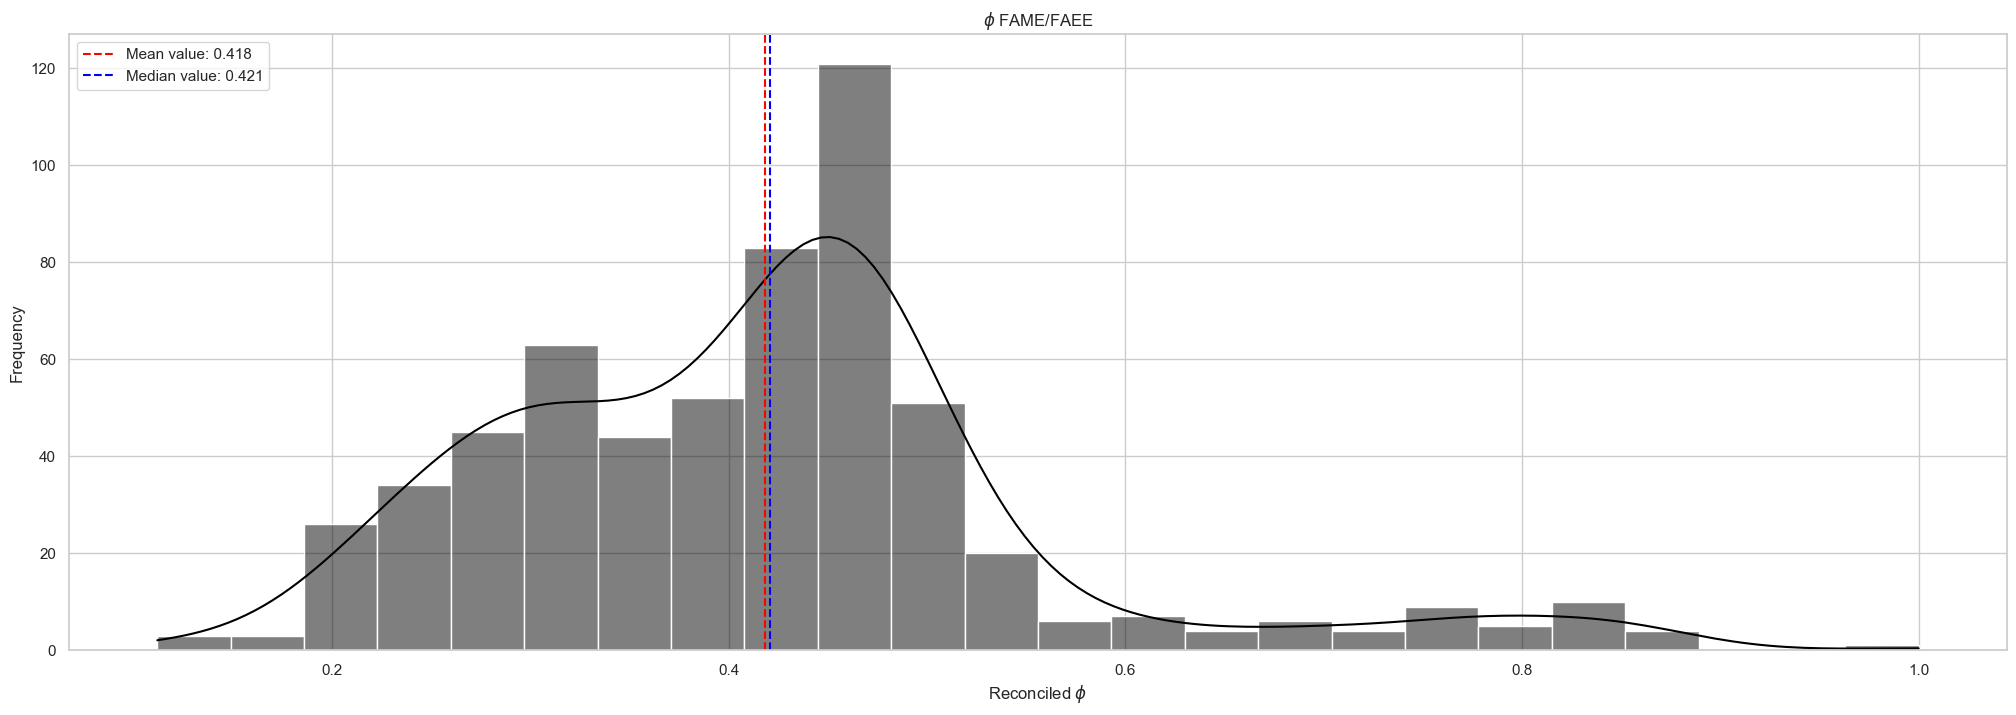

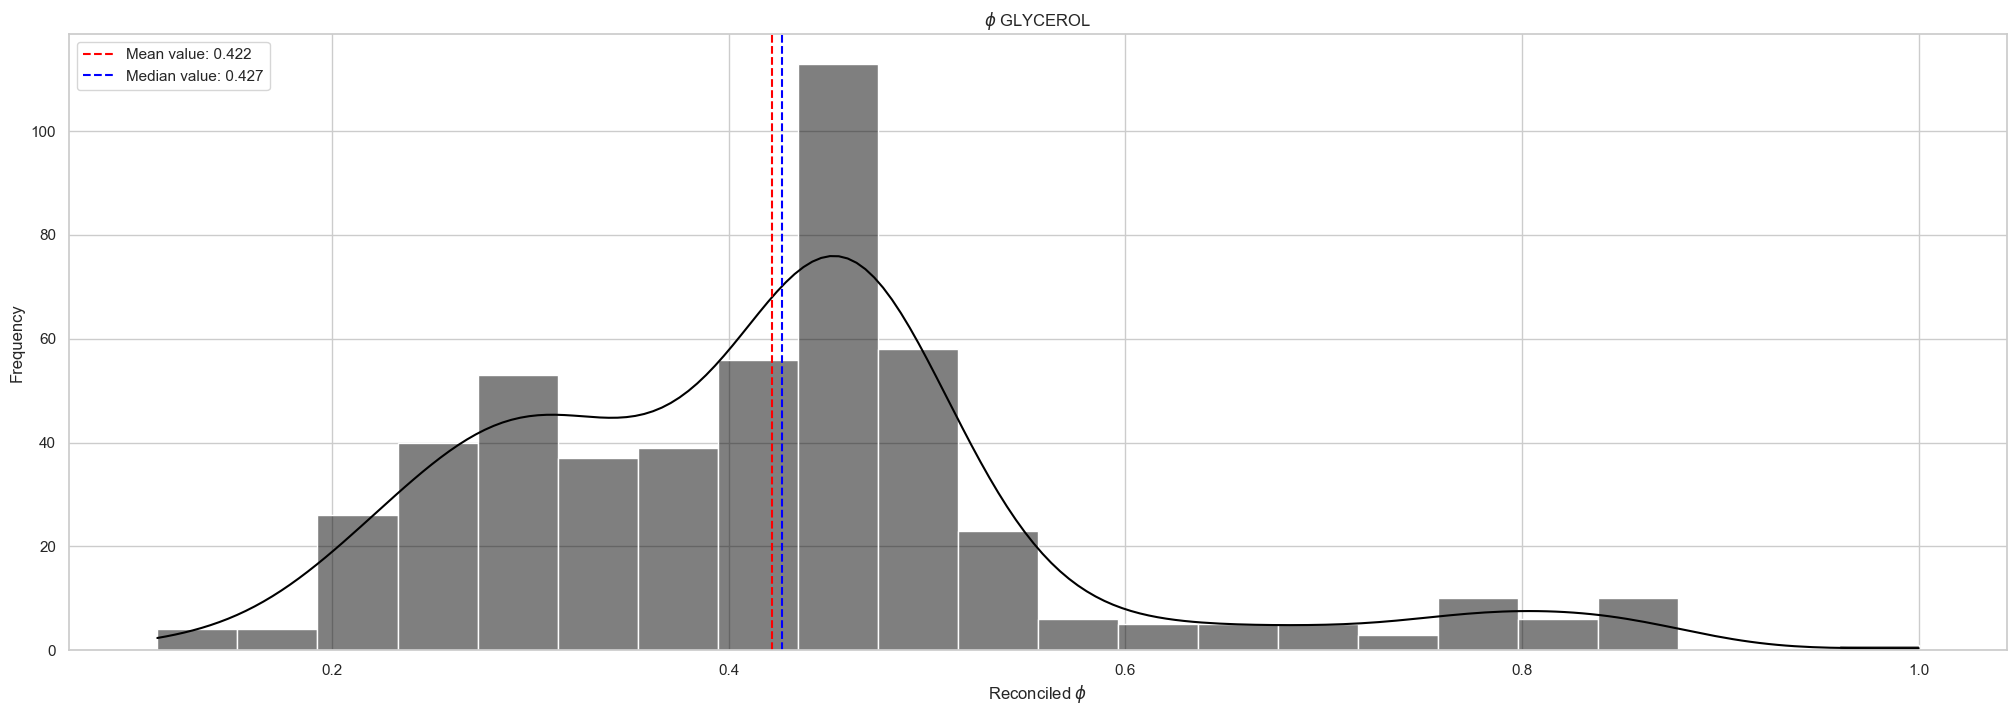

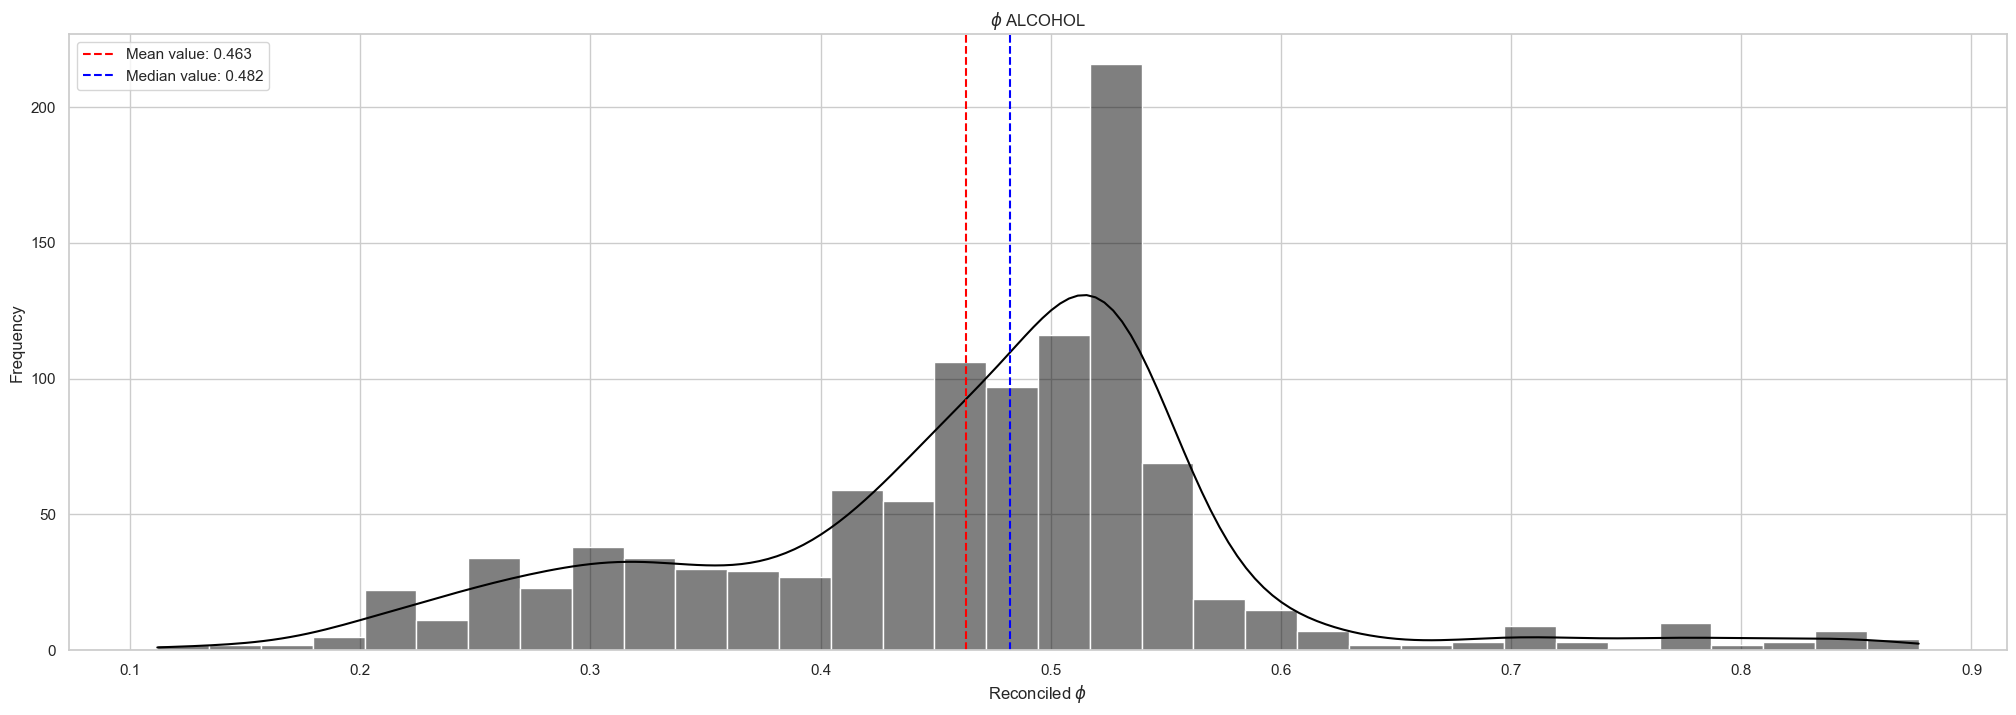

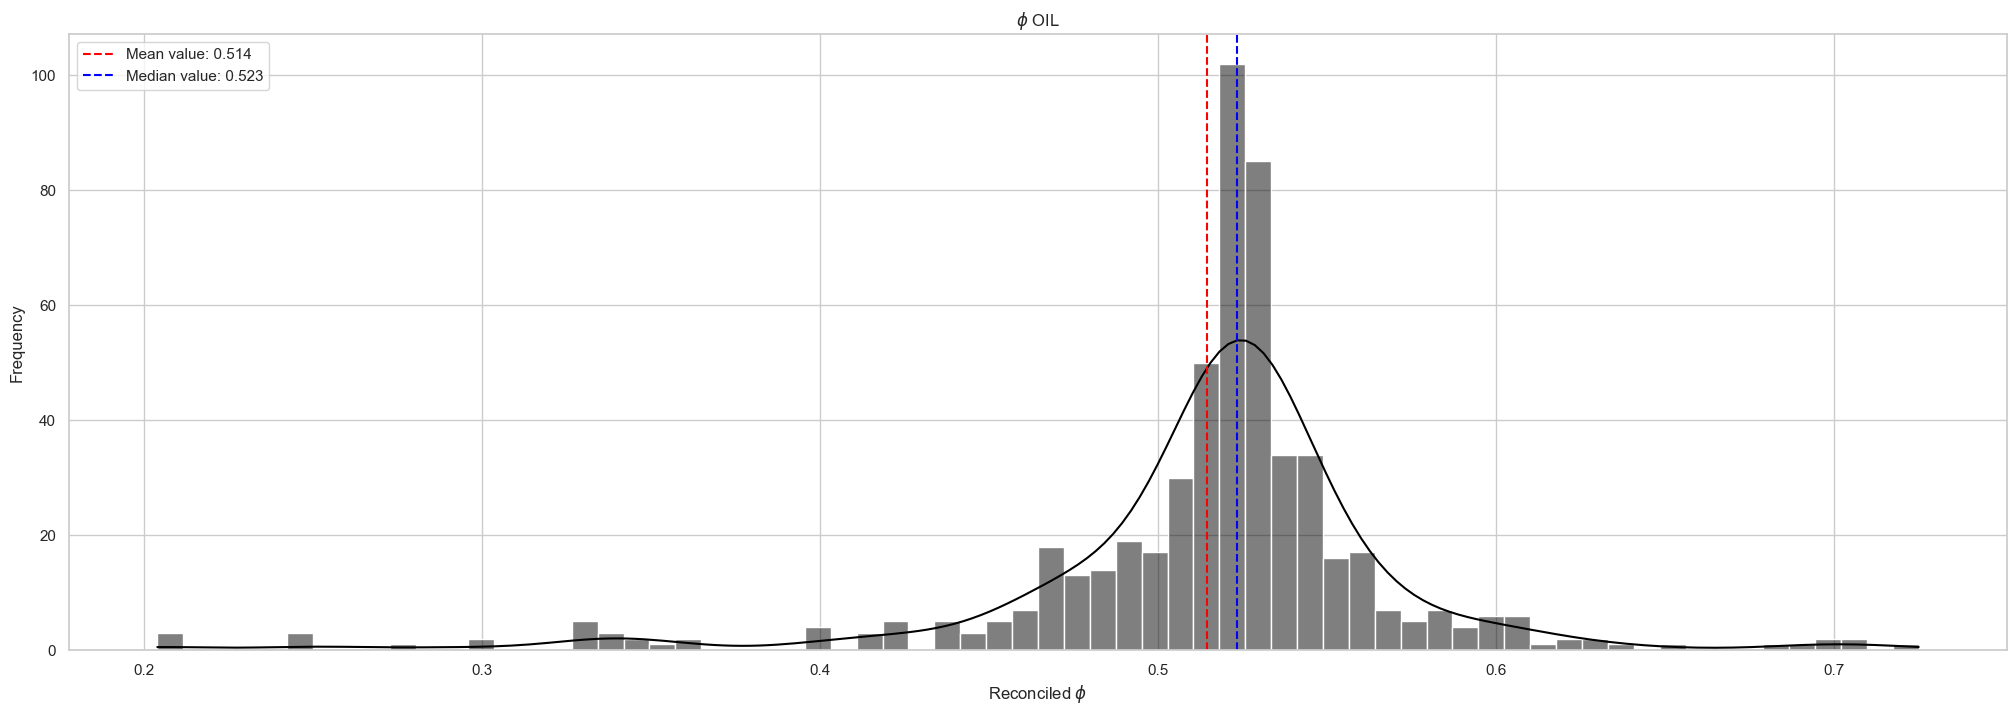

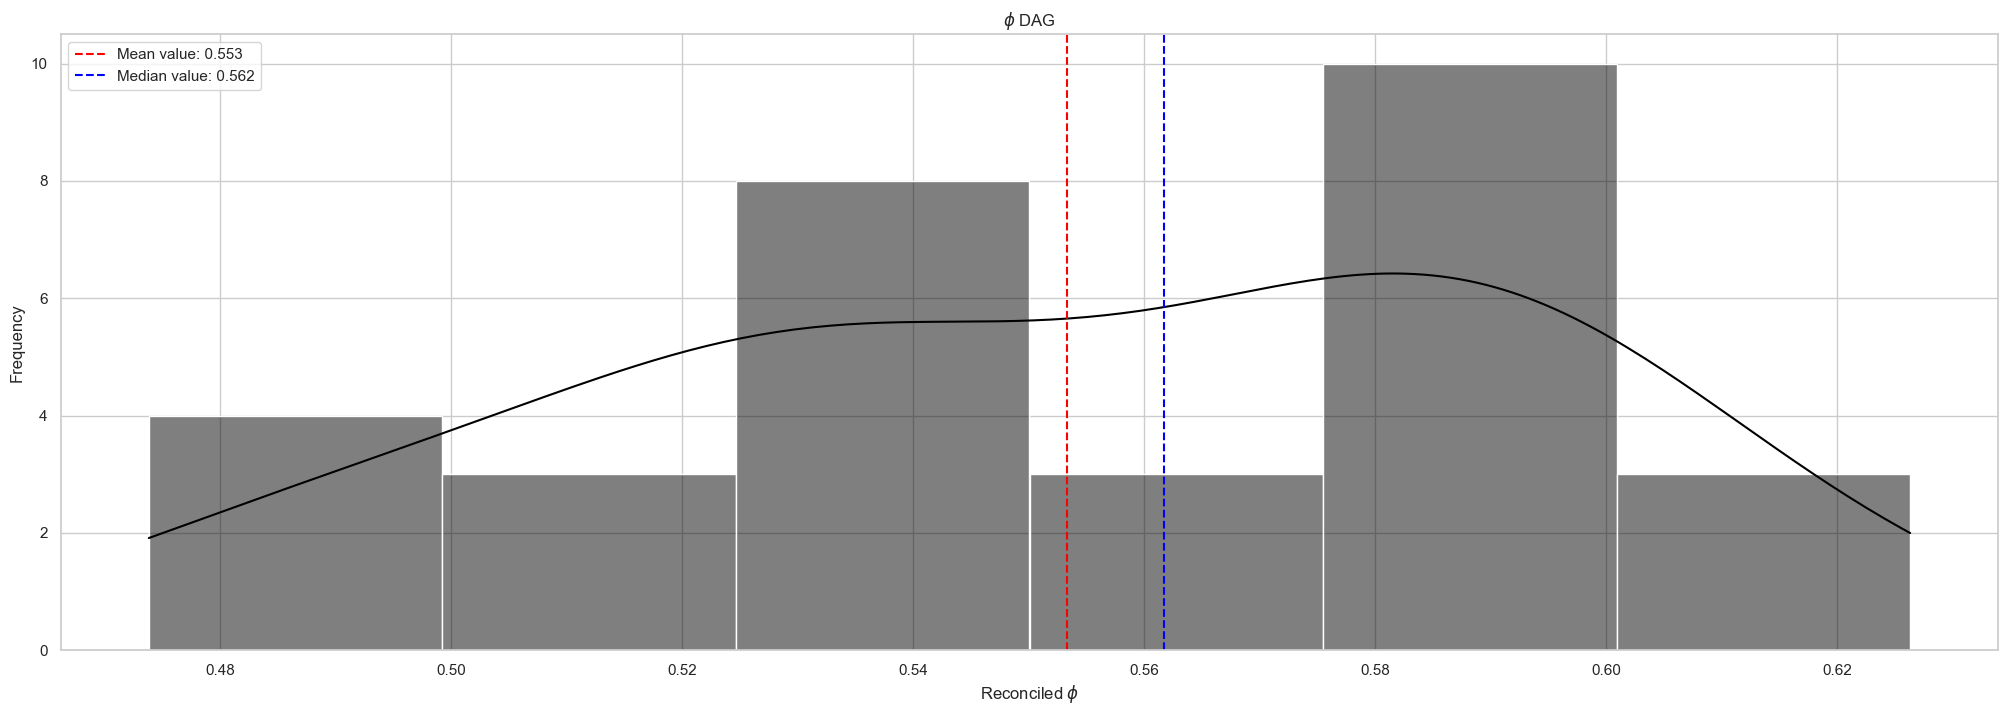

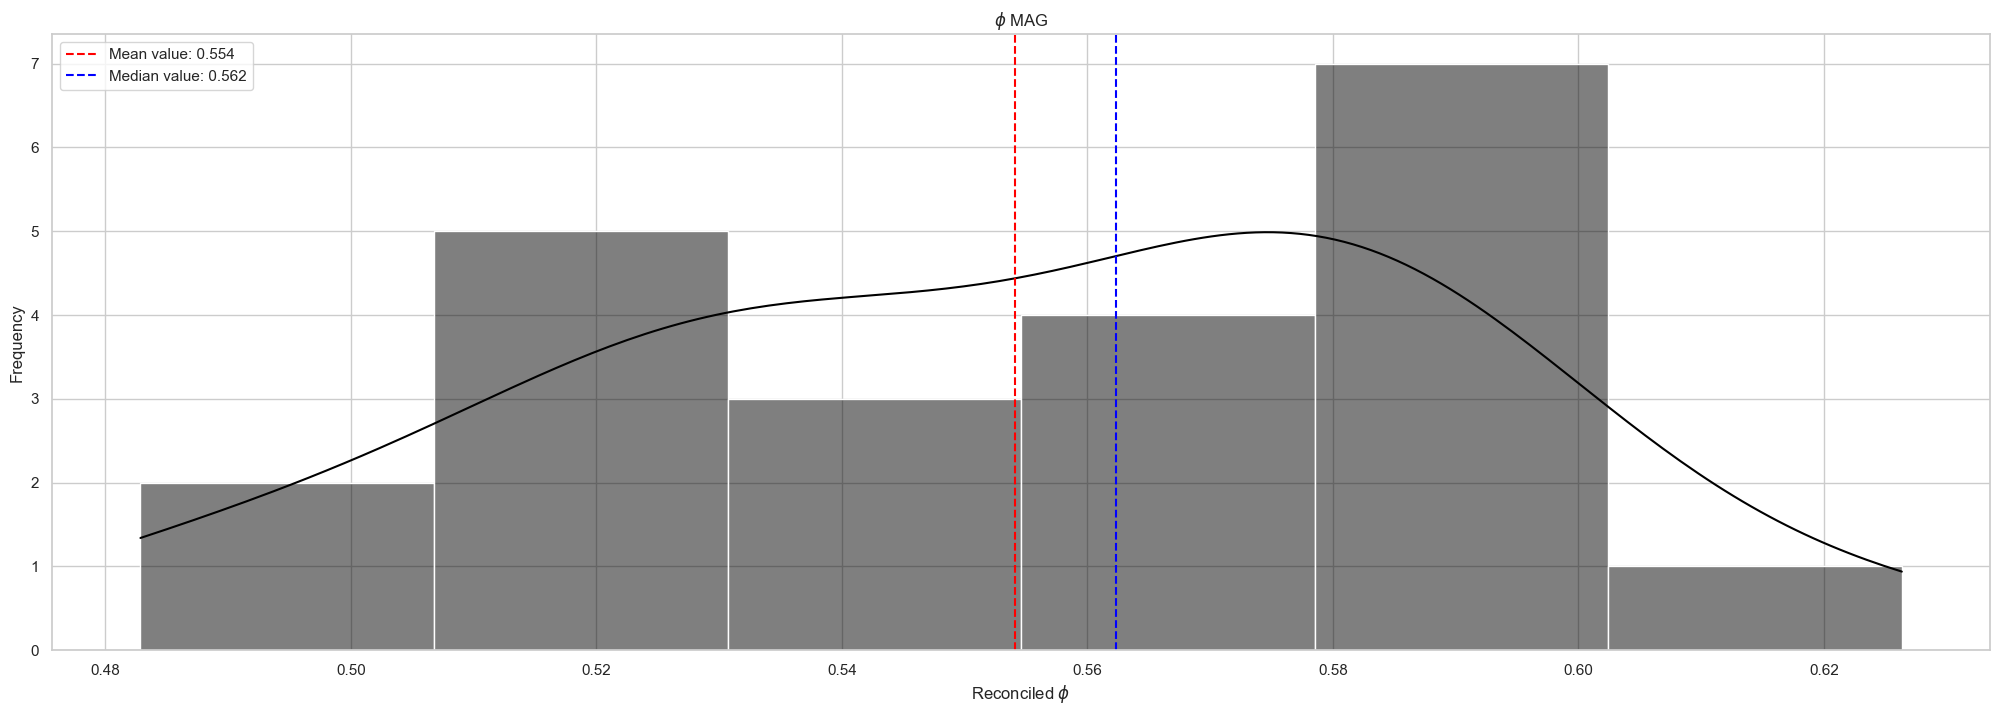

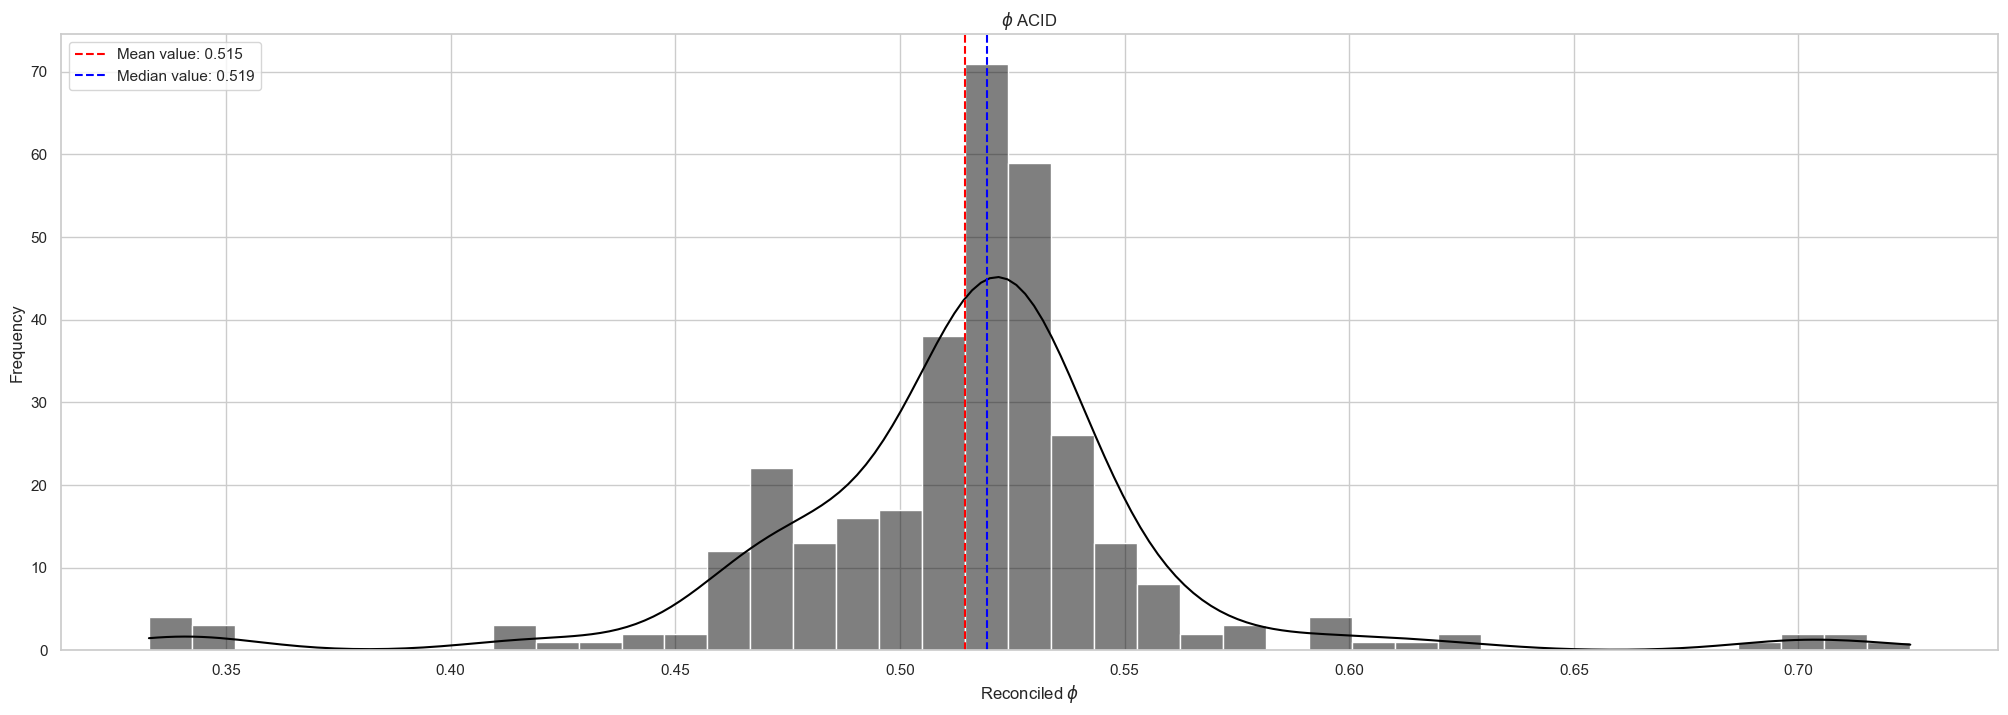

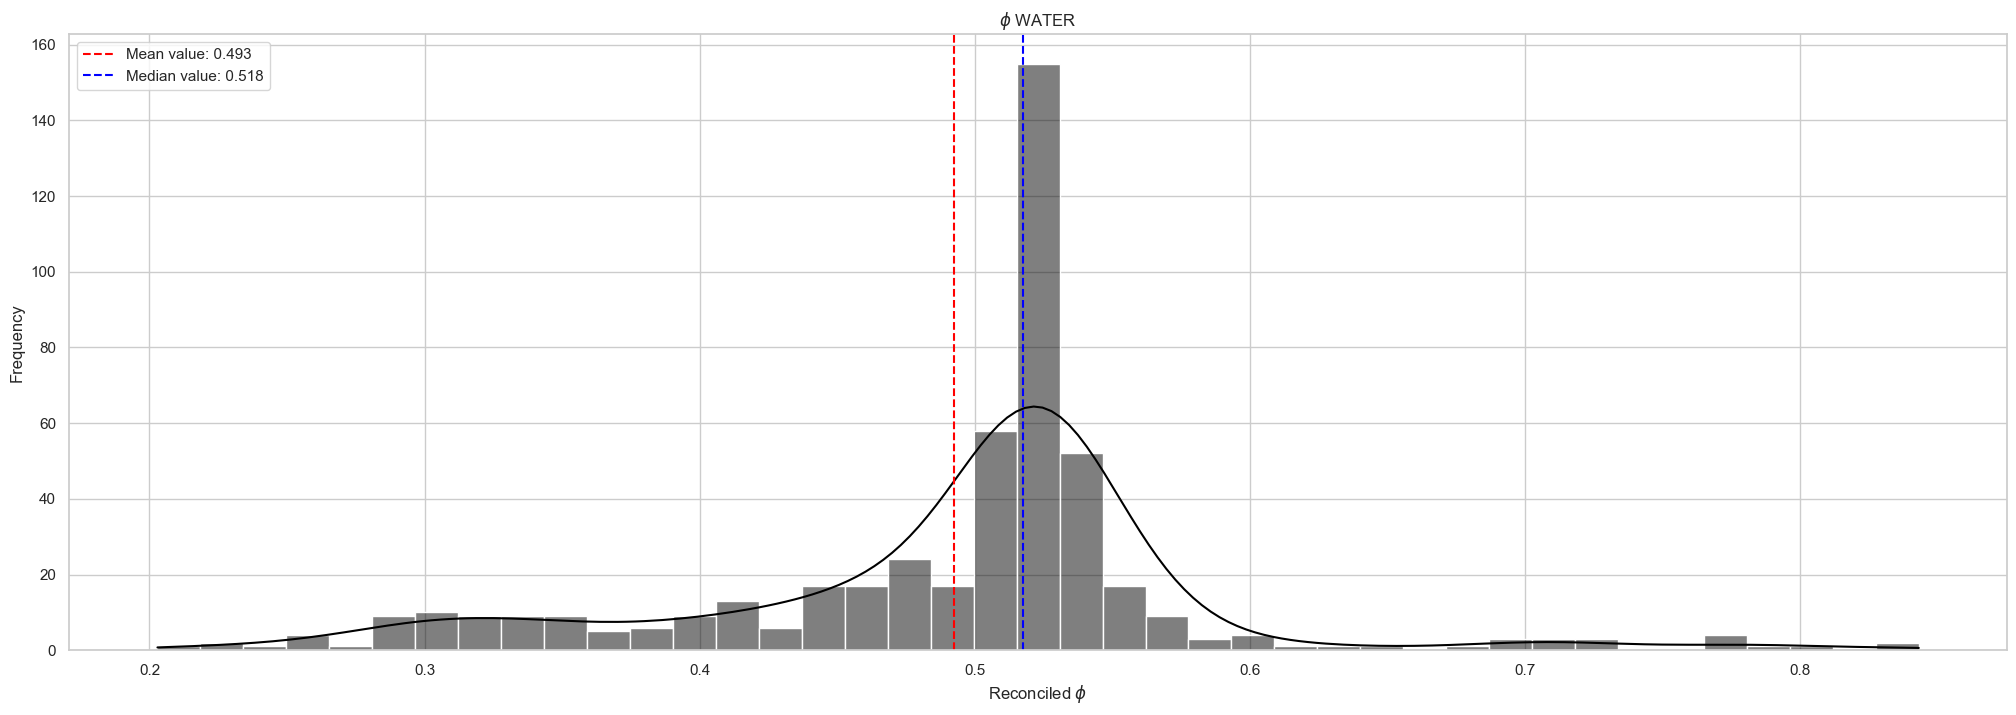

In [72]:
feed_columns = ['FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 'ACID_F', 'WATER_F']
for i in feed_columns:
    plt.figure()
    filter_data = refined_total_data.filter(pl.col(i) > 0.0)
    len_data = filter_data.shape[0]
    column_name = 'phi_' + i.rstrip('_F')
    mean_value = filter_data.select(pl.col(column_name)).mean().to_numpy()[0][0]
    median_value = filter_data.select(pl.col(column_name)).median().to_numpy()[0][0]
    sns.histplot(x = filter_data.select(pl.col(column_name)).to_numpy().reshape(len_data), color = 'black', kde=True).set(title=f"$\phi$ {i.rstrip('_F')}", ylabel = 'Frequency', xlabel = 'Reconciled $\phi$')
    plt.axvline(mean_value, color = 'red', linestyle = '--',  label = f'Mean value: {round(mean_value, 3)}')
    plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
    plt.legend(loc= 'upper left')
    plt.show()

###  4. Source Data

In [73]:
import polars as pl
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

from matplotlib import cm
from scipy.interpolate import griddata

##### Acid Profiles

In [74]:
acid_profiles = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\acid_profile.xlsx")

In [75]:
acid_profiles_pd = acid_profiles.to_pandas()

In [76]:
acid_profiles_pd

,Ref,Sub Ref,MAG/DAG Profile?,Additional FAME Profile?,Acid mix Profile?,Caproic,Caprilic,Capric,Lauric,Mirystic,Palmitic,Palmitoleic,Heptadecanoic,cis-9-heptadecenoic,Stearic,Oleic,Linoleic,Linolenic,Ricinoleic,Densipolic,Arachidic,Arachidonic,Gondoic,"cis-11,14 eicosadienoic",Behenic,Erucic,cis-13 cis-16 docosadienoic,Tetracosanoic,Pentadecanoic,Gadoleic,Elaidic,"9,10-methylene-hexadecanoic",Dihydrosterculic,Paullinic,Malvalic,Sterculic,Total
0,1,a,No,No,No,0.0,0.0000,0.0000,0.00000,0.0000,0.00740,0.00000,0.0,0.0,0.00920,0.02710,0.04310,0.0032,0.8987,0.0093,0.000000,0.0,0.000,0.0,0.0000,0.000,0.000,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.998000
1,2,a,No,No,No,0.0,0.0000,0.0000,0.00000,0.0000,0.24500,0.00000,0.0,0.0,0.00000,0.20300,0.51200,0.0230,0.0000,0.0000,0.000000,0.0,0.000,0.0,0.0000,0.000,0.000,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.983000
2,3,a,No,No,No,0.0,0.0000,0.0000,0.00000,0.0000,0.02200,0.00000,0.0,0.0,0.01100,0.20000,0.08900,0.0480,0.0000,0.0000,0.012000,0.0,0.039,0.0,0.0180,0.556,0.006,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,1.001000
3,4,a,No,No,No,0.0,0.0000,0.0000,0.00000,0.0000,0.07100,0.00000,0.0,0.0,0.03600,0.31900,0.56400,0.0040,0.0000,0.0000,0.003000,0.0,0.001,0.0,0.0010,0.000,0.002,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,1.001000
4,5,a,No,No,No,0.0,0.0000,0.0000,0.00000,0.0000,0.05600,0.00000,0.0,0.0,0.03100,0.50000,0.36700,0.0410,0.0000,0.0000,0.000000,0.0,0.000,0.0,0.0000,0.005,0.000,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
120,55,c,Yes,No,No,0.0,0.0000,0.0000,0.00040,0.0009,0.11400,0.00080,0.0,0.0,0.05520,0.23400,0.54770,0.0353,0.0000,0.0000,0.004100,0.0,0.000,0.0,0.0045,0.000,0.000,0.0,0.0,0.0014,0.0,0.0,0.0,0.0,0.0,0.0,0.998300
121,56,a,No,No,No,0.0,0.0000,0.0000,0.00100,0.0000,0.05540,0.00100,0.0,0.0,0.04250,0.27840,0.59910,0.0040,0.0000,0.0000,0.000000,0.0,0.000,0.0,0.0000,0.000,0.000,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.981400
122,56,b,No,No,No,0.0,0.0000,0.0000,0.00467,0.0000,0.07159,0.00256,0.0,0.0,0.05385,0.29676,0.54662,0.0037,0.0000,0.0000,0.000326,0.0,0.000,0.0,0.0000,0.000,0.000,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.980076
123,56,c,No,No,No,0.0,0.0000,0.0000,0.00834,0.0000,0.08778,0.00412,0.0,0.0,0.06520,0.31512,0.49414,0.0034,0.0000,0.0000,0.000652,0.0,0.000,0.0,0.0000,0.000,0.000,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.978752


In [77]:
acid_profiles_pd_masked  = acid_profiles_pd[['Caproic', 'Caprilic', 'Capric', 'Lauric',
       'Mirystic', 'Palmitic', 'Palmitoleic', 'Heptadecanoic',
       'cis-9-heptadecenoic', 'Stearic', 'Oleic', 'Linoleic', 'Linolenic',
       'Ricinoleic', 'Densipolic', 'Arachidic', 'Arachidonic', 'Gondoic',
       'cis-11,14 eicosadienoic', 'Behenic', 'Erucic',
       'cis-13 cis-16 docosadienoic', 'Tetracosanoic', 'Pentadecanoic',
       'Gadoleic', 'Elaidic', '9,10-methylene-hexadecanoic',
       'Dihydrosterculic', 'Paullinic', 'Malvalic', 'Sterculic']].replace(0, np.nan)

pd.set_option('display.max_columns', None)

acid_profiles_pd_masked[['Caproic', 'Caprilic', 'Capric', 'Lauric',
       'Mirystic', 'Palmitic', 'Palmitoleic', 'Heptadecanoic',
       'cis-9-heptadecenoic', 'Stearic', 'Oleic', 'Linoleic', 'Linolenic',
       'Ricinoleic', 'Densipolic', 'Arachidic', 'Arachidonic', 'Gondoic',
       'cis-11,14 eicosadienoic', 'Behenic', 'Erucic',
       'cis-13 cis-16 docosadienoic', 'Tetracosanoic', 'Pentadecanoic',
       'Gadoleic', 'Elaidic', '9,10-methylene-hexadecanoic',
       'Dihydrosterculic', 'Paullinic', 'Malvalic', 'Sterculic']].describe()


,Caproic,Caprilic,Capric,Lauric,Mirystic,Palmitic,Palmitoleic,Heptadecanoic,cis-9-heptadecenoic,Stearic,Oleic,Linoleic,Linolenic,Ricinoleic,Densipolic,Arachidic,Arachidonic,Gondoic,"cis-11,14 eicosadienoic",Behenic,Erucic,cis-13 cis-16 docosadienoic,Tetracosanoic,Pentadecanoic,Gadoleic,Elaidic,"9,10-methylene-hexadecanoic",Dihydrosterculic,Paullinic,Malvalic,Sterculic
count,6.000000,5.000000,7.000000,37.000000,64.000000,114.000000,59.000000,5.000000,10.000000,104.000000,115.000000,112.000000,81.000000,5.000000,1.0000,51.000000,4.000000,8.000000,1.0000,38.000000,5.000000,4.000000,5.000000,2.000000,24.000000,2.0000,1.000,1.000,1.000,1.000,1.00
mean,0.019850,0.035560,0.310114,0.141760,0.017863,0.134168,0.018446,0.048840,0.017500,0.043136,0.374584,0.377909,0.030750,0.733700,0.0093,0.005317,0.003050,0.025700,0.0292,0.023734,0.113280,0.003350,0.002340,0.010550,0.003650,0.0466,0.011,0.046,0.119,0.359,0.12
std,0.042146,0.025639,0.471766,0.297411,0.042283,0.148235,0.032390,0.105193,0.017759,0.066846,0.257499,0.255039,0.059456,0.378801,NaN,0.004554,0.000614,0.034241,NaN,0.097292,0.247493,0.001797,0.001695,0.014354,0.004831,0.0000,NaN,NaN,NaN,NaN,NaN
min,0.001000,0.004800,0.004400,0.000200,0.000097,0.007400,0.000600,0.000500,0.000500,0.006100,0.024200,0.004100,0.000500,0.056300,0.0093,0.000326,0.002200,0.001000,0.0292,0.000500,0.001300,0.002000,0.000500,0.000400,0.000600,0.0466,0.011,0.046,0.119,0.359,0.12
25%,0.001375,0.014400,0.025300,0.001800,0.001325,0.055550,0.001150,0.000500,0.002800,0.021075,0.196900,0.114450,0.003800,0.889300,0.0093,0.002100,0.002800,0.001200,0.0292,0.001350,0.001300,0.002525,0.001000,0.005475,0.001400,0.0466,0.011,0.046,0.119,0.359,0.12
50%,0.002650,0.040800,0.045300,0.004900,0.003600,0.097100,0.003200,0.003100,0.009600,0.030500,0.278400,0.431600,0.011000,0.898700,0.0093,0.004100,0.003250,0.011200,0.0292,0.003700,0.002800,0.002700,0.002000,0.010550,0.002350,0.0466,0.011,0.046,0.119,0.359,0.12
75%,0.005200,0.051200,0.535250,0.025400,0.009650,0.154050,0.028500,0.003100,0.031975,0.040700,0.492250,0.559000,0.045900,0.912100,0.0093,0.006600,0.003500,0.039350,0.0292,0.005200,0.005000,0.003525,0.004100,0.015625,0.003925,0.0466,0.011,0.046,0.119,0.359,0.12
max,0.105800,0.066600,1.000000,1.000000,0.198400,1.000000,0.192800,0.237000,0.050100,0.487500,1.000000,1.000000,0.495441,0.912100,0.0093,0.025600,0.003500,0.100400,0.0292,0.593500,0.556000,0.006000,0.004100,0.020700,0.024800,0.0466,0.011,0.046,0.119,0.359,0.12


In [78]:
repeated_FA = (acid_profiles_pd[['Caproic', 'Caprilic', 'Capric', 'Lauric',
       'Mirystic', 'Palmitic', 'Palmitoleic', 'Heptadecanoic',
       'cis-9-heptadecenoic', 'Stearic', 'Oleic', 'Linoleic', 'Linolenic',
       'Ricinoleic', 'Densipolic', 'Arachidic', 'Arachidonic', 'Gondoic',
       'cis-11,14 eicosadienoic', 'Behenic', 'Erucic',
       'cis-13 cis-16 docosadienoic', 'Tetracosanoic', 'Pentadecanoic',
       'Gadoleic', 'Elaidic', '9,10-methylene-hexadecanoic',
       'Dihydrosterculic', 'Paullinic', 'Malvalic', 'Sterculic']] > 0).sum().sort_values(ascending=False)

repeated_FA

Oleic                          115
Palmitic                       114
Linoleic                       112
Stearic                        104
Linolenic                       81
Mirystic                        64
Palmitoleic                     59
Arachidic                       51
Behenic                         38
Lauric                          37
Gadoleic                        24
cis-9-heptadecenoic             10
Gondoic                          8
Capric                           7
Caproic                          6
Caprilic                         5
Ricinoleic                       5
Erucic                           5
Tetracosanoic                    5
Heptadecanoic                    5
Arachidonic                      4
cis-13 cis-16 docosadienoic      4
Pentadecanoic                    2
Elaidic                          2
Densipolic                       1
cis-11,14 eicosadienoic          1
9,10-methylene-hexadecanoic      1
Dihydrosterculic                 1
Paullinic           

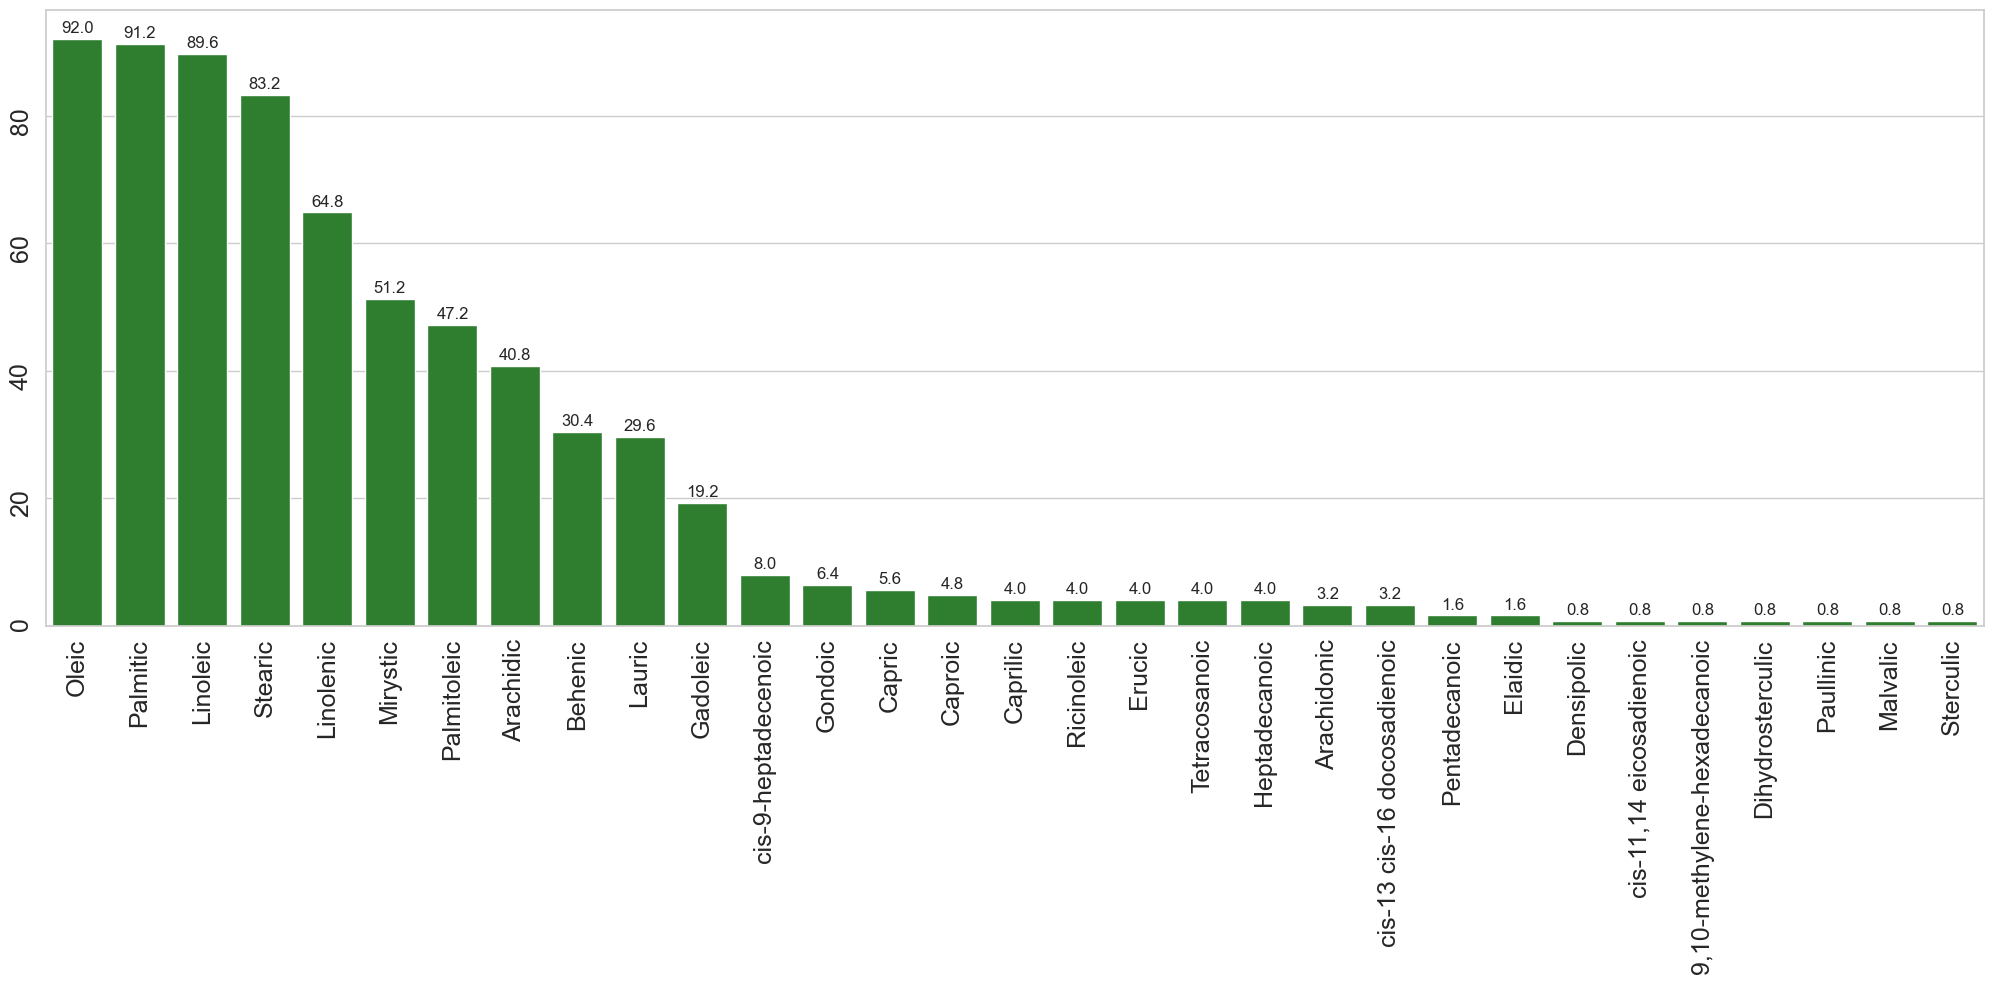

In [79]:
sns.set_theme(rc={'figure.figsize':(25,8)})
sns.set_style("whitegrid")
# Create barplot
ax = sns.barplot(repeated_FA/125*100, color="forestgreen")

# Add value labels
for bar in ax.patches:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f'{height:.1f}',
        ha='center',
        va='bottom'
    )
    
plt.xticks(rotation=90, fontsize=18)
plt.yticks(rotation=90, fontsize=18)

plt.show()

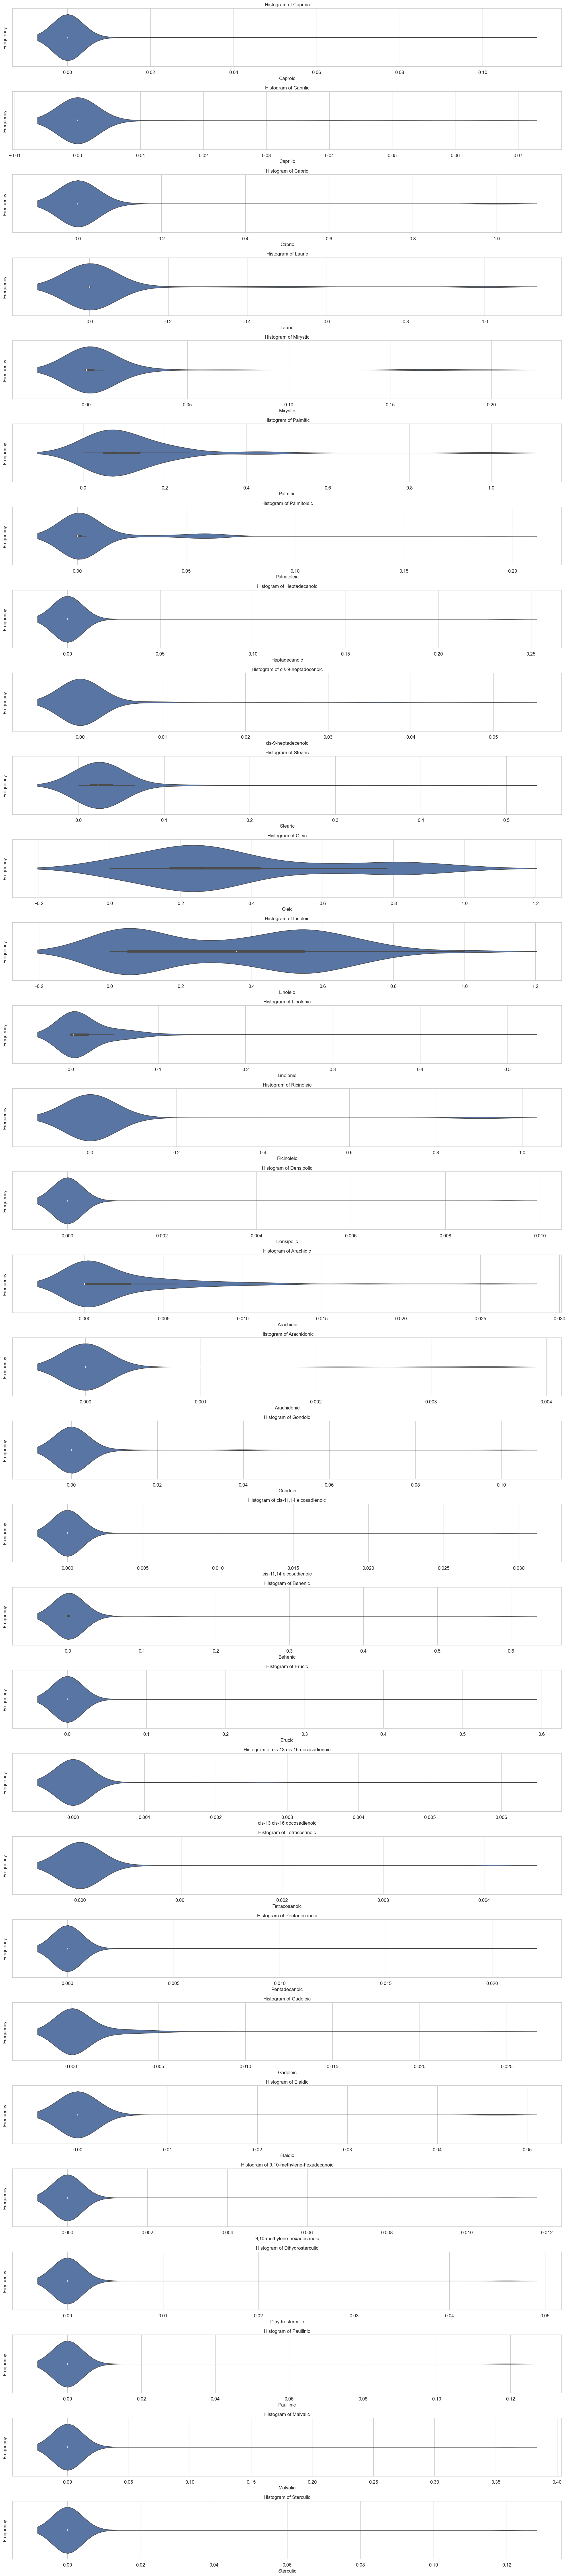

In [80]:
columns_to_plot = ['Caproic', 'Caprilic', 'Capric', 'Lauric',
       'Mirystic', 'Palmitic', 'Palmitoleic', 'Heptadecanoic',
       'cis-9-heptadecenoic', 'Stearic', 'Oleic', 'Linoleic', 'Linolenic',
       'Ricinoleic', 'Densipolic', 'Arachidic', 'Arachidonic', 'Gondoic',
       'cis-11,14 eicosadienoic', 'Behenic', 'Erucic',
       'cis-13 cis-16 docosadienoic', 'Tetracosanoic', 'Pentadecanoic',
       'Gadoleic', 'Elaidic', '9,10-methylene-hexadecanoic',
       'Dihydrosterculic', 'Paullinic', 'Malvalic', 'Sterculic']

# Create subplots
fig, axes = plt.subplots(len(columns_to_plot), 1, figsize=(20, 90))

# If only one column, wrap axis in a list for consistency
if len(columns_to_plot) == 1:
    axes = [axes]

# Plot each histogram
for i, col in enumerate(columns_to_plot):
    sns.violinplot(data=acid_profiles_pd, x=col,  ax=axes[i])
    axes[i].set_title(f'Histogram of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
    axes[i].tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.show()

##### Equilibrium data

In [81]:

df = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\SensitivityAnalysis\data\profile_coeffs_ref.xlsx")

In [82]:
filtered_df = df.filter(
    ~(
        pl.col("Source").str.contains("Acid") | 
        pl.col("Source").str.contains("FAME") | 
        pl.col("Source").str.contains("MAG/DAG")
    )
)

In [83]:
filtered_df
with pl.Config(tbl_rows=len(filtered_df), tbl_cols=-1):
    print(filtered_df)

shape: (83, 11)
┌─────┬─────┬──────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────┬─────────┐
│ Ref ┆ Sub ┆ MAG/DAG  ┆ Additio ┆ Acid    ┆ Type    ┆ m       ┆ n       ┆ p       ┆ b   ┆ Source  │
│ --- ┆ Ref ┆ Profile? ┆ nal     ┆ mix Pro ┆ Alcohol ┆ ---     ┆ ---     ┆ ---     ┆ --- ┆ ---     │
│ i64 ┆ --- ┆ ---      ┆ FAME    ┆ file?   ┆ ---     ┆ f64     ┆ f64     ┆ f64     ┆ i64 ┆ str     │
│     ┆ str ┆ str      ┆ Profile ┆ ---     ┆ i64     ┆         ┆         ┆         ┆     ┆         │
│     ┆     ┆          ┆ ?       ┆ str     ┆         ┆         ┆         ┆         ┆     ┆         │
│     ┆     ┆          ┆ ---     ┆         ┆         ┆         ┆         ┆         ┆     ┆         │
│     ┆     ┆          ┆ str     ┆         ┆         ┆         ┆         ┆         ┆     ┆         │
╞═════╪═════╪══════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════╪═════════╡
│ 1   ┆ a   ┆ No       ┆ No      ┆ No      ┆ 1       ┆ 12.9912 ┆ 1.04369 ┆ 

In [84]:
filtered_df.filter(pl.col("Source")=="Palm")

Ref,Sub Ref,MAG/DAG Profile?,Additional FAME Profile?,Acid mix Profile?,Type Alcohol,m,n,p,b,Source
i64,str,str,str,str,i64,f64,f64,f64,i64,str
20,"""a""","""No""","""No""","""No""",2,13.851386,0.587797,0.0,1,"""Palm"""
34,"""a""","""No ""","""No""","""No""",2,13.882211,0.573585,0.0,1,"""Palm"""
34,"""b""","""No""","""No""","""No""",2,13.882211,0.573585,0.0,1,"""Palm"""


In [85]:
stats_df = filtered_df.group_by('Source').agg([
    # For column 'm'
    pl.col('m').min().alias('m_min'),
    pl.col('m').quantile(0.25).alias('m_q25'),
    pl.col('m').median().alias('m_median'),
    pl.col('m').quantile(0.75).alias('m_q75'),
    pl.col('m').max().alias('m_max'),
    pl.col('m').mean().alias('m_mean'),
    
    # For column 'n'
    pl.col('n').min().alias('n_min'),
    pl.col('n').quantile(0.25).alias('n_q25'),
    pl.col('n').median().alias('n_median'),
    pl.col('n').quantile(0.75).alias('n_q75'),
    pl.col('n').max().alias('n_max'),
    pl.col('n').mean().alias('n_mean'),
    
    # For column 'p'
    pl.col('p').min().alias('p_min'),
    pl.col('p').quantile(0.25).alias('p_q25'),
    pl.col('p').median().alias('p_median'),
    pl.col('p').quantile(0.75).alias('p_q75'),
    pl.col('p').max().alias('p_max'),
    pl.col('p').mean().alias('p_mean'),
    
])

with pl.Config(tbl_rows=len(stats_df), tbl_cols=-1):
    print(stats_df)

shape: (39, 19)
┌─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┐
│ Sou ┆ m_m ┆ m_q ┆ m_m ┆ m_q ┆ m_m ┆ m_m ┆ n_m ┆ n_q ┆ n_m ┆ n_q ┆ n_m ┆ n_m ┆ p_m ┆ p_q ┆ p_m ┆ p_q ┆ p_m ┆ p_m │
│ rce ┆ in  ┆ 25  ┆ edi ┆ 75  ┆ ax  ┆ ean ┆ in  ┆ 25  ┆ edi ┆ 75  ┆ ax  ┆ ean ┆ in  ┆ 25  ┆ edi ┆ 75  ┆ ax  ┆ ean │
│ --- ┆ --- ┆ --- ┆ an  ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ an  ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ an  ┆ --- ┆ --- ┆ --- │
│ str ┆ f64 ┆ f64 ┆ --- ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ --- ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ --- ┆ f64 ┆ f64 ┆ f64 │
│     ┆     ┆     ┆ f64 ┆     ┆     ┆     ┆     ┆     ┆ f64 ┆     ┆     ┆     ┆     ┆     ┆ f64 ┆     ┆     ┆     │
╞═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╡
│ Lin ┆ 11. ┆ 11. ┆ 11. ┆ 11. ┆ 11. ┆ 11. ┆ 2.0 ┆ 2.0 ┆ 2.0 ┆ 2.0 ┆ 2.0 ┆ 2.0 ┆ 0.0 ┆ 0.0 ┆ 0.0 ┆ 0.0 ┆ 0.0 ┆ 0.0 │
│ see ┆ 782 ┆ 782 ┆ 782 ┆ 782 ┆ 782 ┆ 782 ┆ 332 ┆ 332 ┆ 

In [86]:
count_values = filtered_df.group_by('Source').agg(
    pl.col('m').count().alias('m_count')
)

count_values = count_values.sort(by="m_count", descending=True)

with pl.Config(tbl_rows=len(count_values)):
    print(count_values)

shape: (39, 2)
┌─────────────────────────────┬─────────┐
│ Source                      ┆ m_count │
│ ---                         ┆ ---     │
│ str                         ┆ u32     │
╞═════════════════════════════╪═════════╡
│ Soybean                     ┆ 13      │
│ Sunflower                   ┆ 7       │
│ Cottonseed                  ┆ 5       │
│ Corn                        ┆ 4       │
│ Castor                      ┆ 4       │
│ Palm                        ┆ 3       │
│ Rice Bran                   ┆ 3       │
│ Canola                      ┆ 3       │
│ Canola                      ┆ 3       │
│ Oleic                       ┆ 2       │
│ Babassu                     ┆ 2       │
│ Macauba                     ┆ 2       │
│ Coconut                     ┆ 2       │
│ Crambe                      ┆ 2       │
│ Brazil Nut                  ┆ 2       │
│ Peanut                      ┆ 2       │
│ Jatropha                    ┆ 2       │
│ Mixed                       ┆ 1       │
│ Olive            

In [87]:
df_pandas = filtered_df.to_pandas()

In [88]:
def calculate_stats(df, parameters):
    mean_value = df[parameters].mean()
    std_value = df[parameters].std()
    max_value = df[parameters].max()
    min_value = df[parameters].min()

    return {"mean":mean_value, "std":std_value, "max":max_value, "min":min_value}

    
stats_m = calculate_stats(df_pandas, "m")
stats_n = calculate_stats(df_pandas, "n")
stats_p = calculate_stats(df_pandas, "p")


In [89]:
print(f"m: {stats_m} \n", f"n: {stats_n} \n", f"p: {stats_p} \n")

m: {'mean': 13.040792518062323, 'std': 0.9779327887372177, 'max': 17.05411199780443, 'min': 10.0} 
 n: {'mean': 1.1693300246015552, 'std': 0.4197608338972609, 'max': 2.033213061043078, 'min': 0.0} 
 p: {'mean': 0.044221110393172974, 'std': 0.19476429553145658, 'max': 0.9149194700052542, 'min': 0.0} 



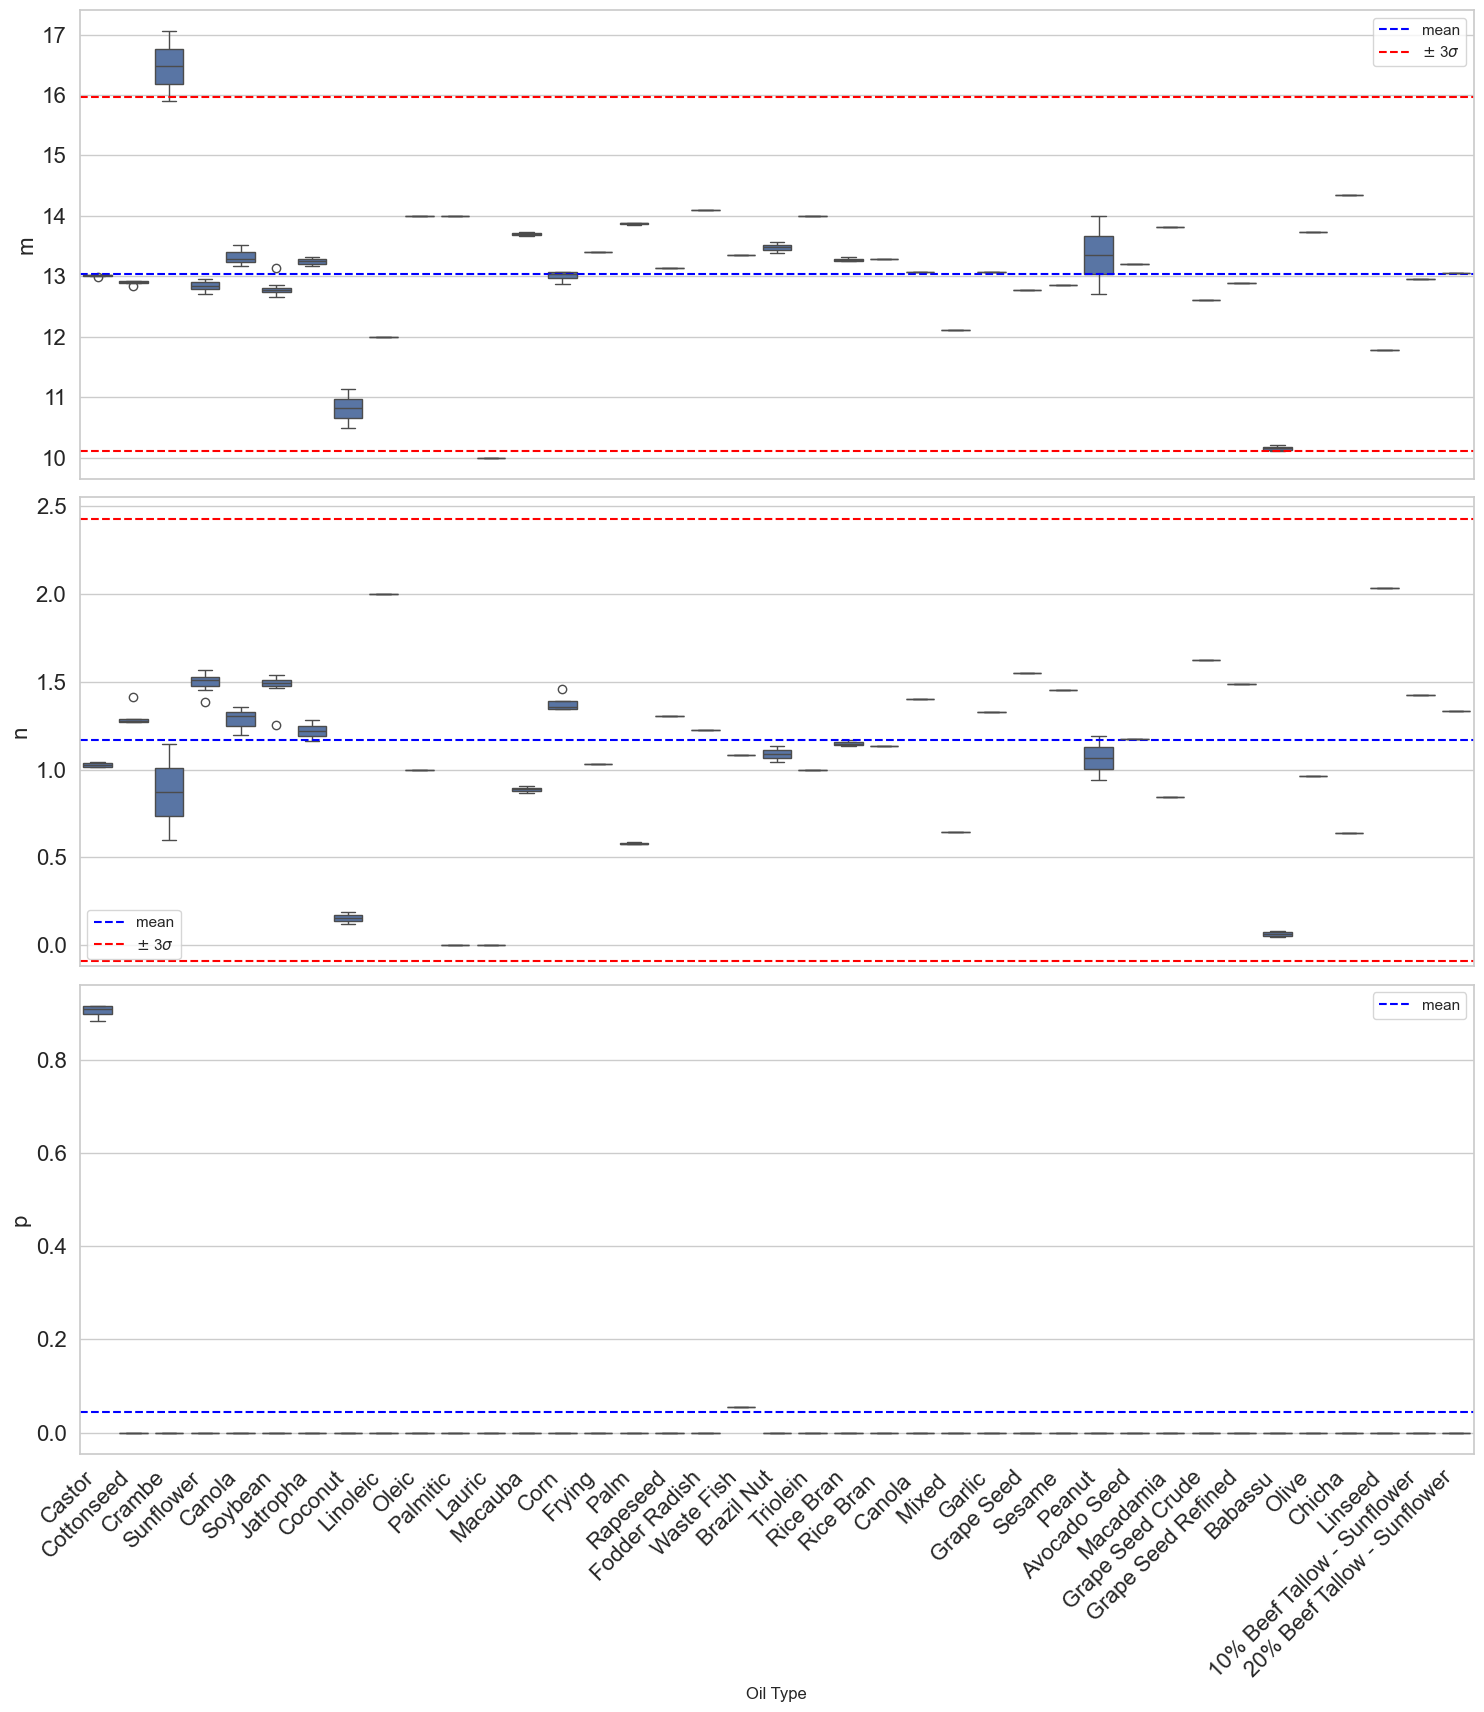

In [90]:

columns = ['m', 'n', 'p']
# for comparing distributions between groups
fig, axes = plt.subplots(3, 1, figsize=(15, 18), sharex=True)
axes = axes.flatten()

sns.boxplot(x='Source', y="m", data=df_pandas, ax=axes[0])
axes[0].set_xlabel('Oil Type')
axes[0].set_ylabel("m", fontsize=16)
axes[0].axhline(y=stats_m["mean"], color="blue", linestyle="--", label="mean")
axes[0].axhline(y=stats_m["mean"] + stats_m["std"]*3, color="red", linestyle="--", label="$\pm$ 3$\sigma$")
axes[0].axhline(y=stats_m["mean"] - stats_m["std"]*3, color="red", linestyle="--")
axes[0].tick_params(axis='both', labelsize=16)
plt.setp(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].legend()

sns.boxplot(x='Source', y="n", data=df_pandas, ax=axes[1])
axes[1].set_xlabel('Oil Type')
axes[1].set_ylabel("n", fontsize=16)
axes[1].axhline(y=stats_n["mean"], color="blue", linestyle="--", label="mean")
axes[1].axhline(y=stats_n["mean"] + stats_n["std"]*3, color="red", linestyle="--", label="$\pm$ 3$\sigma$")
axes[1].axhline(y=stats_n["mean"] - stats_n["std"]*3, color="red", linestyle="--")
axes[1].tick_params(axis='both', labelsize=16)
plt.setp(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].legend()

sns.boxplot(x='Source', y="p", data=df_pandas, ax=axes[2])
axes[2].set_xlabel('Oil Type')
axes[2].set_ylabel("p", fontsize=16)
axes[2].axhline(y=stats_p["mean"], color="blue", linestyle="--", label="mean")
plt.setp(axes[2].get_xticklabels(), rotation=45, ha='right')
axes[2].legend()
axes[2].tick_params(axis='both', labelsize=16)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [91]:
def surface_plot(X, Y, Z, title, x_label, y_label, z_label, bar_label):
    # Create a grid for interpolation
    X_grid = np.linspace(min(X), max(X), 50)
    Y_grid = np.linspace(min(Y), max(Y), 50)
    X_mesh, Y_mesh = np.meshgrid(X_grid, Y_grid)

    # Interpolate Z values onto the grid
    points = np.column_stack((X, Y))
    FAME_comp_grid = griddata(points, Z, (X_mesh, Y_mesh), method='linear')

    # Create a new figure
    fig = plt.figure(figsize=(12, 10))
    ax = fig.add_subplot(111, projection='3d')

    # Create surface plot
    surf = ax.plot_surface(X_mesh, Y_mesh, FAME_comp_grid, 
                        cmap='magma', 
                        edgecolor='none', 
                        alpha=0.8)


    # Add a color bar
    fig.colorbar(surf, ax=ax, shrink=0.5, aspect=5, label=bar_label)

    # Add labels with your requested arrangement
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_zlabel(z_label)
    ax.set_title(title)

    # Adjust the viewing angle for better visualization
    ax.view_init(elev=30, azim=45)
    ax.set_box_aspect(None, zoom=0.85)

    plt.tight_layout()
    plt.show()

In [92]:
refined_data = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\No 47exp\refined_lle_data_v5.xlsx")

In [93]:
comps_MW = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\comps_MW.xlsx")

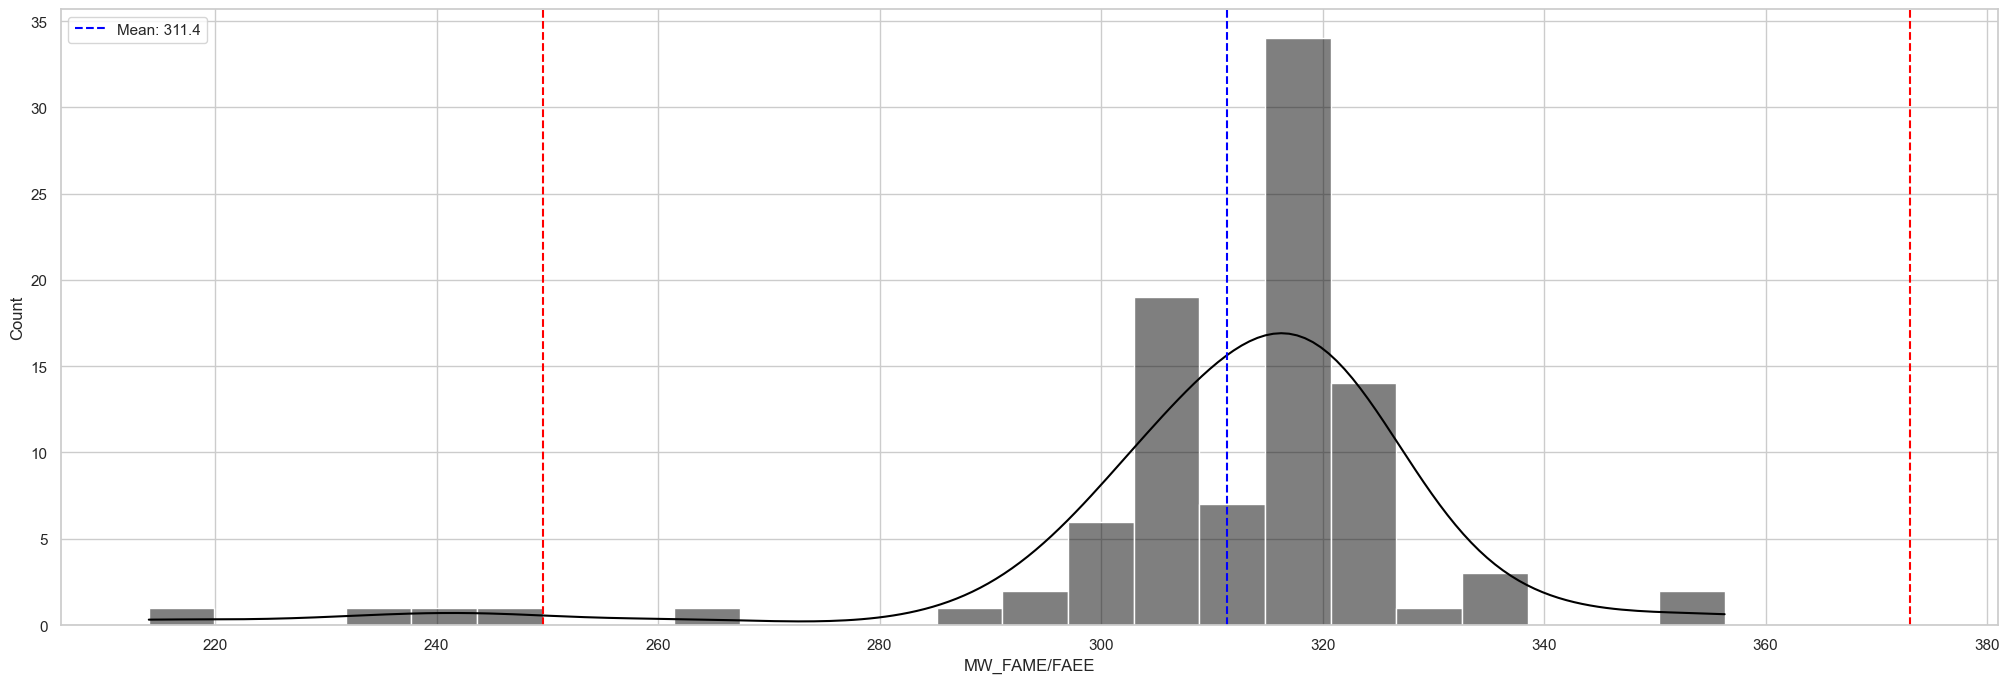

In [94]:
mean_FAME = comps_MW["MW_FAME/FAEE"].mean()
std_FAME = comps_MW["MW_FAME/FAEE"].std()

sns.histplot(x = comps_MW["MW_FAME/FAEE"], color="black", kde=True)
plt.axvline(x=mean_FAME, color="blue", linestyle="--", label = f"Mean: {mean_FAME:.1f}")
plt.axvline(x=mean_FAME + std_FAME*3, color="red", linestyle="--")
plt.axvline(x=mean_FAME - std_FAME*3, color="red", linestyle="--")
plt.legend()
plt.show()

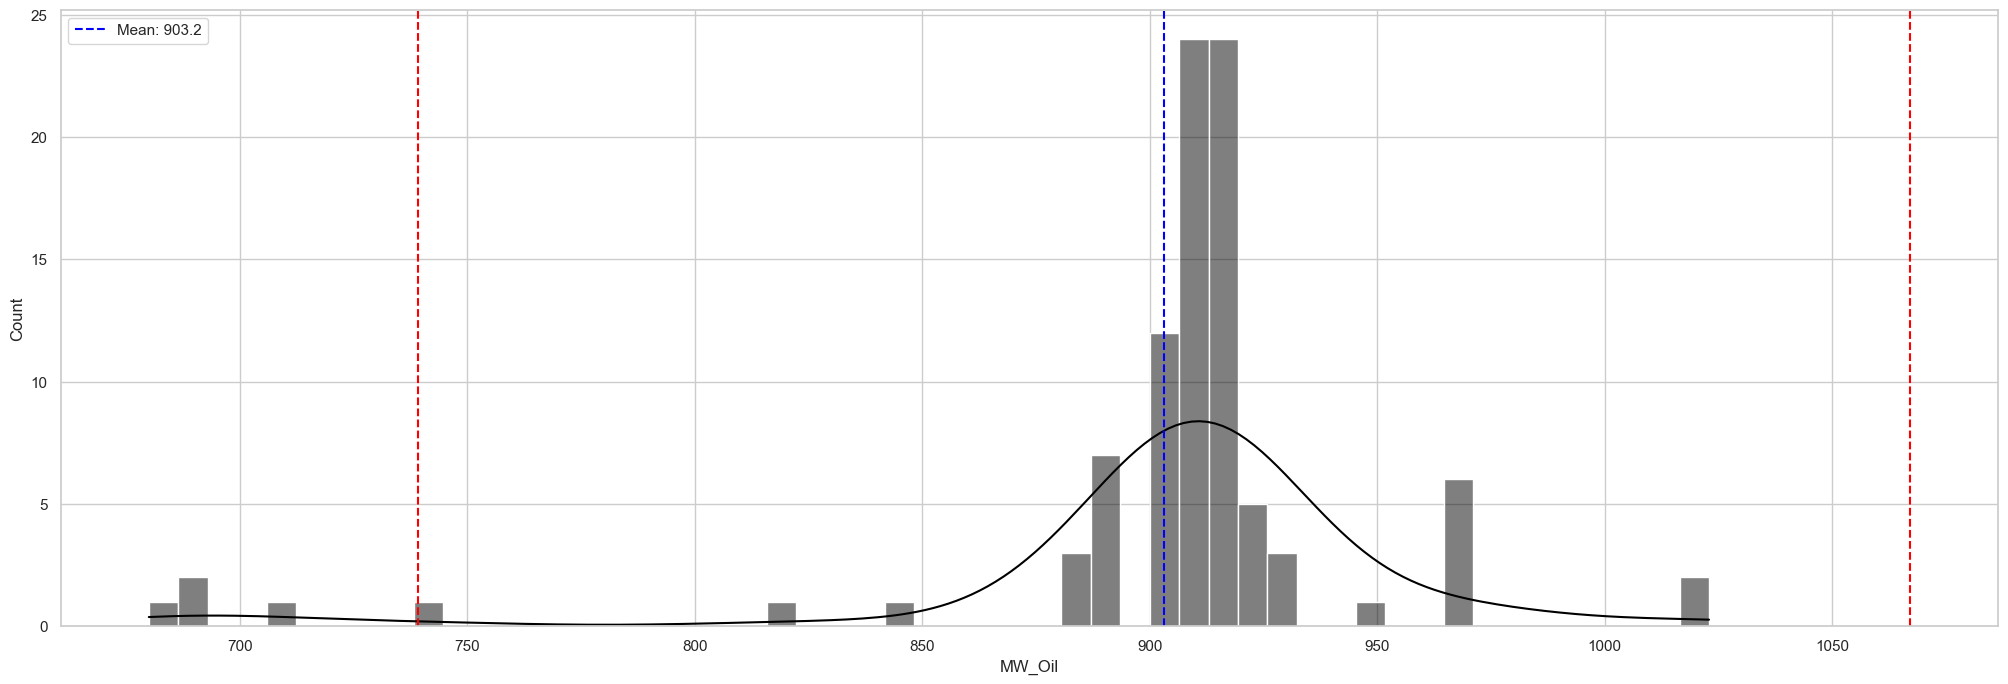

In [95]:
mean_Oil = comps_MW["MW_Oil"].mean()
std_Oil = comps_MW["MW_Oil"].std()
sns.histplot(x = comps_MW["MW_Oil"], color="black", kde=True)
plt.axvline(x=mean_Oil, color="blue", linestyle="--", label = f"Mean: {mean_Oil:.1f}")
plt.axvline(x=mean_Oil + std_Oil*3, color="red", linestyle="--")
plt.axvline(x=mean_Oil - std_Oil*3, color="red", linestyle="--")
plt.legend()
plt.show()

In [96]:
refined_data = refined_data.with_columns(pl.col("Sub Ref").str.slice(0, 1).alias("Sub Ref"))

In [97]:
result = refined_data.join(
    comps_MW,
    on=["Ref", "Sub Ref"],
    how="left"
)

result = result.with_columns(
    pl.col('Sub Ref').str.slice(0, 1).alias('Sub Ref')
)

In [98]:
base_columns = [
    'FAME/FAEE',
    'GLYCEROL',
    'ALCOHOL',
    'OIL',
    'DAG',
    'MAG',
    'ACID',
    'WATER'
]

# Create the K_ columns with the condition: if _H is 0, then K_ is 0
for col in base_columns:
    col_l = f"{col}_L"
    col_h = f"{col}_H"
    k_col = f"K_{col}"
    
    # Using when/then/otherwise for conditional logic
    result = result.with_columns(
        pl.when(pl.col(col_h) == 0)
        .then(pl.lit(0))
        .otherwise(np.log(pl.col(col_l) / pl.col(col_h)))
        .alias(k_col)
    )
    
    


In [99]:
result = result.drop("Type Alcohol_right")

In [100]:
joined_types = result.join(filtered_df, on=["Ref", "Sub Ref"], how="inner")

In [101]:
(joined_types
 .group_by("Source")
 .agg(pl.col("K_OIL").mean().alias("K_OIL_mean"))
 .filter((pl.col("Source")=="Palm") | (pl.col("Source")=="Corn") | (pl.col("Source")=="Cottonseed")| (pl.col("Source")=="Soybean")))

Source,K_OIL_mean
str,f64
"""Corn""",1.023494
"""Soybean""",1.423041
"""Palm""",1.518825
"""Cottonseed""",1.241296


In [102]:
(joined_types
 .group_by("Source")
 .agg(pl.col("K_OIL").std().alias("K_OIL_std"))
 .filter((pl.col("Source")=="Palm") | (pl.col("Source")=="Corn") | (pl.col("Source")=="Cottonseed")| (pl.col("Source")=="Soybean")))

Source,K_OIL_std
str,f64
"""Soybean""",2.42767
"""Corn""",2.97011
"""Cottonseed""",3.674452
"""Palm""",2.211135


In [103]:
(joined_types
 .group_by("Source")
 .agg(pl.col("K_OIL").min().alias("K_OIL_min"))
 .filter((pl.col("Source")=="Palm") | (pl.col("Source")=="Corn") | (pl.col("Source")=="Cottonseed")| (pl.col("Source")=="Soybean")))

Source,K_OIL_min
str,f64
"""Corn""",-4.825952
"""Palm""",-1.863041
"""Soybean""",-2.862028
"""Cottonseed""",-2.51779


In [104]:
(joined_types
 .group_by("Source")
 .agg(pl.col("K_OIL").max().alias("K_OIL_max"))
 .filter((pl.col("Source")=="Palm") | (pl.col("Source")=="Corn") | (pl.col("Source")=="Cottonseed")| (pl.col("Source")=="Soybean")))

Source,K_OIL_max
str,f64
"""Palm""",5.267483
"""Corn""",5.353065
"""Cottonseed""",11.421291
"""Soybean""",11.459571


In [105]:
result

Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,Reconcile phi,MW_FAME/FAEE,MW_Glycerol,MW_Alcohol,MW_Oil,MW_DAG,MW_MAG,MW_FA,MW_H2O,K_FAME/FAEE,K_GLYCEROL,K_ALCOHOL,K_OIL,K_DAG,K_MAG,K_ACID,K_WATER
i64,str,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64
1,"""a""",298.15,1,0.4,0.4,0.2,0.0,0.0,0.0,0.0,0.0,0.881461,0.010995,0.106827,0.0,0.0,0.0,0.0,0.0,0.00001,0.723179,0.277407,0.0,0.0,0.0,0.0,0.0,0.453786,324.139909,92.09,32.04,968.419726,659.279817,350.139909,296.139909,18,11.386751,-4.186226,-0.954277,0.0,0.0,0.0,0.0,0.0
1,"""a""",298.15,1,0.385,0.385,0.23,0.0,0.0,0.0,0.0,0.0,0.856402,0.028158,0.115568,0.0,0.0,0.0,0.0,0.0,0.002266,0.674722,0.322908,0.0,0.0,0.0,0.0,0.0,0.448095,324.139909,92.09,32.04,968.419726,659.279817,350.139909,296.139909,18,5.934788,-3.176454,-1.027512,0.0,0.0,0.0,0.0,0.0
1,"""a""",298.15,1,0.41,0.41,0.18,0.0,0.0,0.0,0.0,0.0,0.90767,0.005553,0.086762,0.0,0.0,0.0,0.0,0.0,0.000146,0.74308,0.256786,0.0,0.0,0.0,0.0,0.0,0.451618,324.139909,92.09,32.04,968.419726,659.279817,350.139909,296.139909,18,8.734328,-4.896381,-1.085076,0.0,0.0,0.0,0.0,0.0
2,"""a""",293.15,2,0.4431,0.438,0.1189,0.0,0.0,0.0,0.0,0.0,0.895378,0.024504,0.080139,0.0,0.0,0.0,0.0,0.0,0.026639,0.818751,0.154592,0.0,0.0,0.0,0.0,0.0,0.479386,315.953619,92.09,46.07,901.860858,614.907238,327.953619,273.953619,18,3.514882,-3.508964,-0.657031,0.0,0.0,0.0,0.0,0.0
2,"""a""",293.15,2,0.4176,0.4162,0.1662,0.0,0.0,0.0,0.0,0.0,0.873731,0.023739,0.102309,0.0,0.0,0.0,0.0,0.0,0.025474,0.75359,0.221126,0.0,0.0,0.0,0.0,0.0,0.462273,315.953619,92.09,46.07,901.860858,614.907238,327.953619,273.953619,18,3.535127,-3.457716,-0.770732,0.0,0.0,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
57,"""a""",318.2,2,0.0,0.0,0.447,0.513,0.0,0.0,0.0,0.041,0.0,0.0,0.109755,0.888876,0.0,0.0,0.0,0.002904,0.0,0.0,0.866894,0.045007,0.0,0.0,0.0,0.088432,0.55458,245.611894,92.09,46.07,690.835683,474.223789,257.611894,203.611894,18,0.0,0.0,-2.06667,2.983134,0.0,0.0,0.0,-3.41606
57,"""a""",318.2,2,0.0,0.0,0.494,0.496,0.0,0.0,0.0,0.01,0.0,0.0,0.342187,0.651845,0.0,0.0,0.0,0.005811,0.0,0.0,0.718954,0.265071,0.0,0.0,0.0,0.016207,0.597065,245.611894,92.09,46.07,690.835683,474.223789,257.611894,203.611894,18,0.0,0.0,-0.742441,0.899808,0.0,0.0,0.0,-1.025643
57,"""a""",318.2,2,0.0,0.0,0.501,0.479,0.0,0.0,0.0,0.02,0.0,0.0,0.239539,0.754497,0.0,0.0,0.0,0.006396,0.0,0.0,0.818388,0.144574,0.0,0.0,0.0,0.036514,0.548309,245.611894,92.09,46.07,690.835683,474.223789,257.611894,203.611894,18,0.0,0.0,-1.22862,1.652259,0.0,0.0,0.0,-1.741977


In [106]:
k_columns = [
    'K_FAME/FAEE',
    'K_GLYCEROL',
    'K_ALCOHOL',
    'K_OIL',
    'K_DAG',
    'K_MAG', 
    'K_ACID',
    'K_WATER'
]

if isinstance(result, pl.DataFrame):
    pdf = result.to_pandas()
else:
    pdf = result  # Assume it's already pandas

In [139]:
new_columns = ["FAME/FAEE", "Glycerol", "Alcohol", "Oil", "DAG", "MAG", "FA", "Water"]

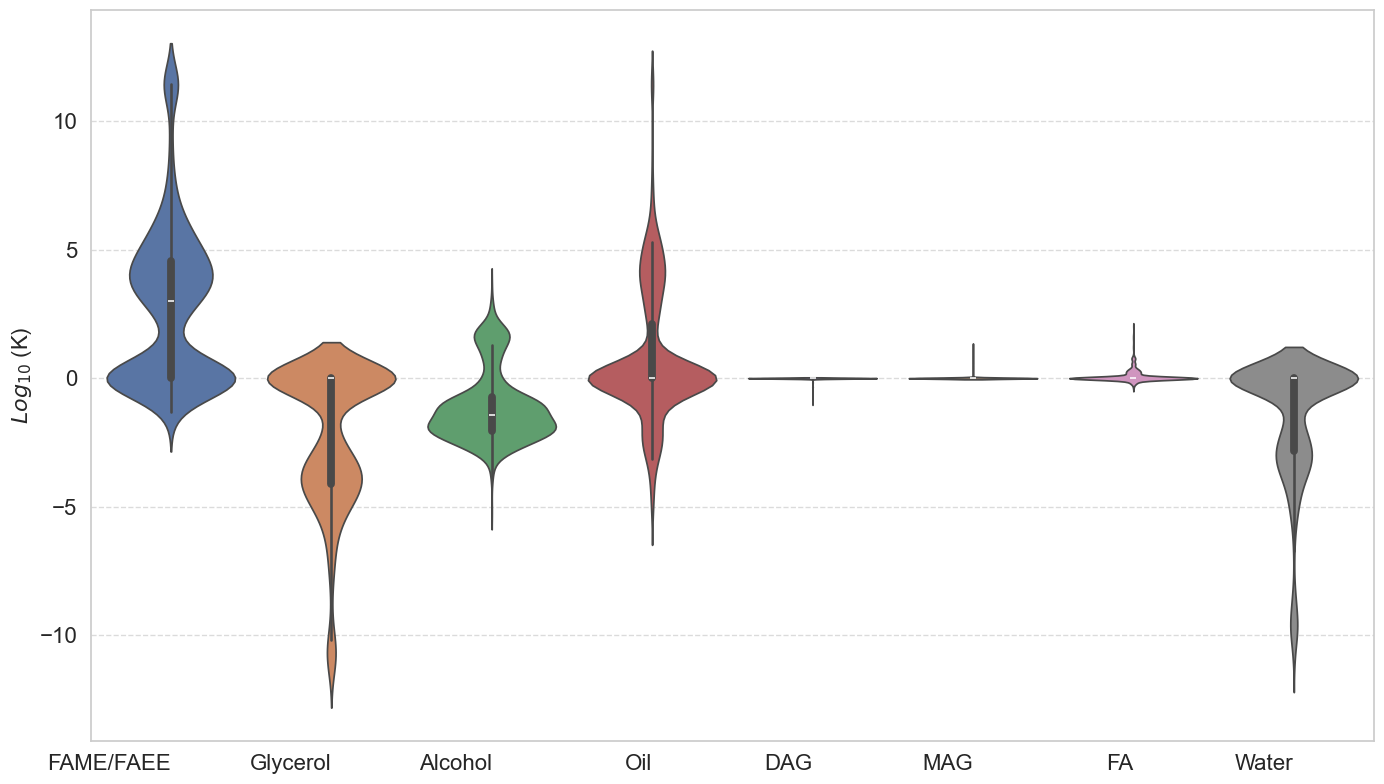

In [144]:
sns.set_style("whitegrid")
k_values_melted = pd.melt(pdf[k_columns], var_name='K Parameter', value_name='Value')

plt.figure(figsize=(14, 8))
sns.violinplot(hue='K Parameter', x = "K Parameter", y='Value', data=k_values_melted, legend=False)
plt.xticks(ticks=range(len(k_columns)), labels=new_columns, ha='right', fontsize=16)
plt.yticks(fontsize=16)
plt.ylabel("$Log_{10}$ (K)", fontsize=16)
plt.xlabel("")
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Handle outliers for the combined plot
q1, q3 = np.percentile(k_values_melted['Value'].dropna(), [25, 75])
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr
#plt.ylim(0, min(k_values_melted['Value'].max(), upper_limit*1.5))

#plt.ylim(0, 30)

#plt.savefig('k_values_combined_violin.png', dpi=300, bbox_inches='tight')
plt.show()



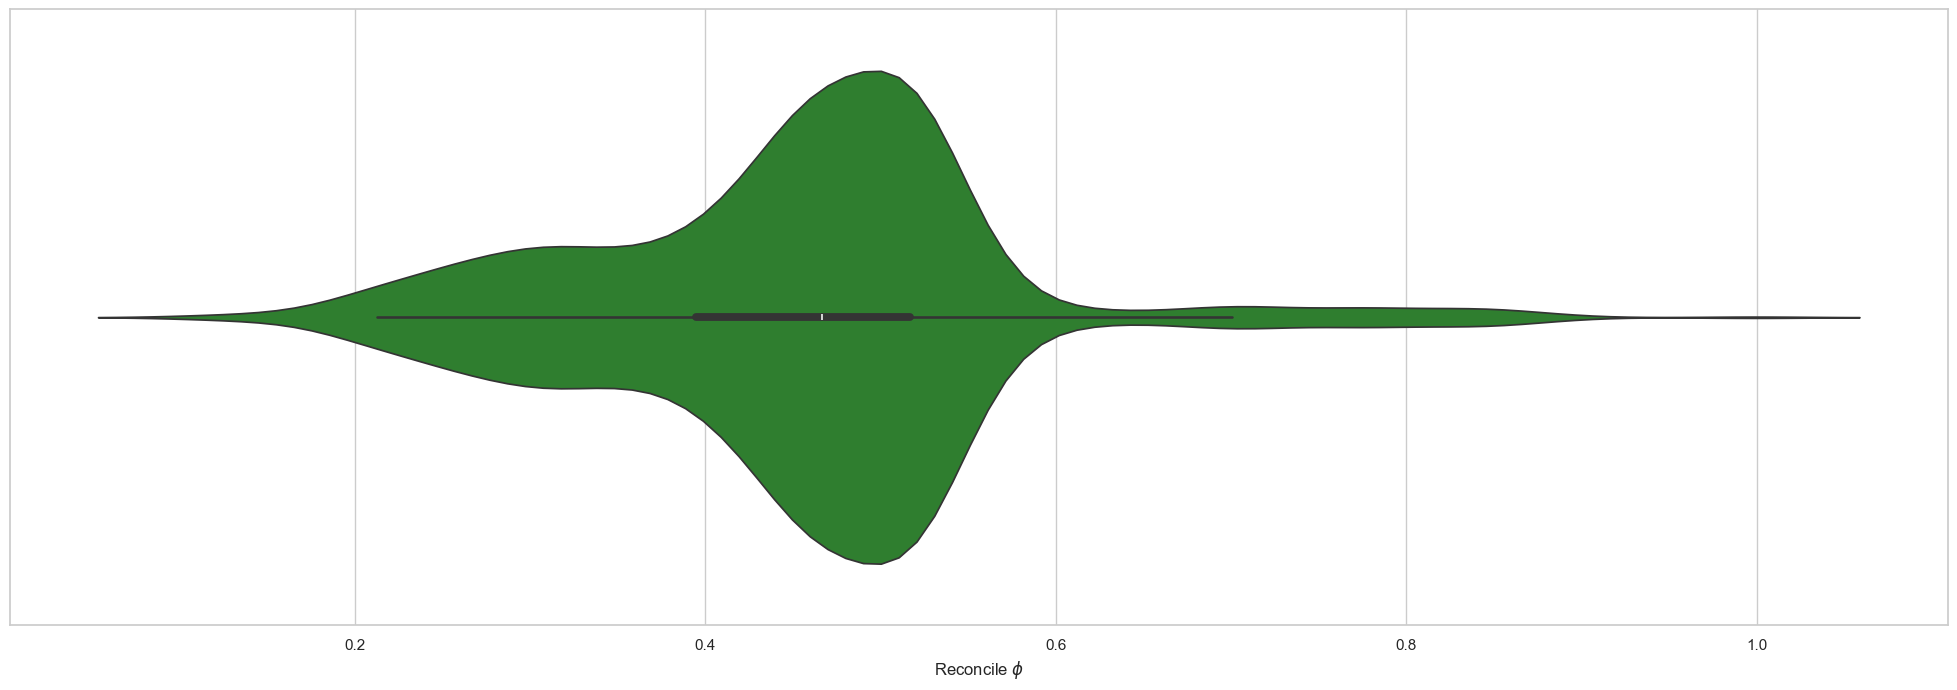

In [108]:
sns.violinplot(data=result,  x="Reconcile phi", color="forestgreen").set(xlabel="Reconcile $\phi$")
plt.show()

In [109]:
k_values_melted.groupby("K Parameter").agg(["mean","median", "std", "min", "max"])

Value                                          
                 mean    median       std        min        max
K Parameter                                                    
K_ACID       0.078609  0.000000  0.233628  -0.391171   2.023775
K_ALCOHOL   -1.103898 -1.430295  1.367583  -5.194970   3.593038
K_DAG       -0.007563  0.000000  0.067665  -1.003187   0.000000
K_FAME/FAEE  2.811167  2.995562  3.075707  -1.311559  11.498690
K_GLYCEROL  -2.296906  0.000000  2.805634 -11.414637   0.000000
K_MAG        0.009658  0.000000  0.087241   0.000000   1.311117
K_OIL        0.778108  0.000000  2.515393  -5.226906  11.486754
K_WATER     -1.532178  0.000000  2.435862 -10.997593   0.000000

In [110]:
K_FAME_df  = result.drop(["Ref", "Sub Ref"]).to_pandas()
K_FAME_corr = K_FAME_df.corr()[["K_FAME/FAEE"]]


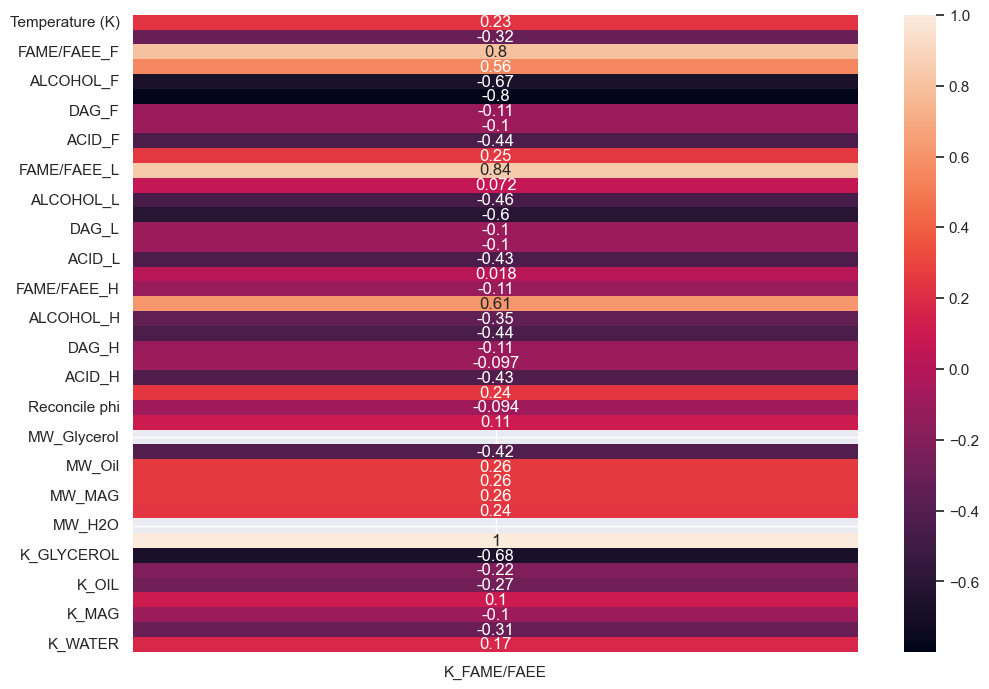

In [111]:
sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.heatmap(K_FAME_corr, annot=True)
plt.show()

In [112]:
K_OIL_df  = result.drop(["Ref", "Sub Ref"]).to_pandas()
K_OIL_corr = K_OIL_df.corr()[["K_OIL"]]



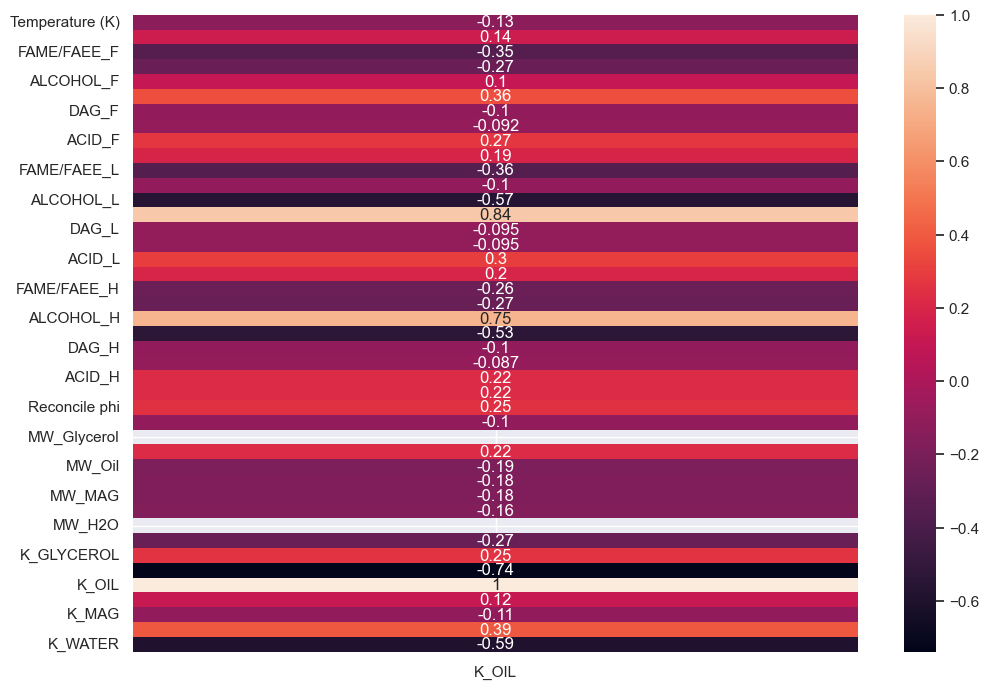

In [113]:
sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.heatmap(K_OIL_corr, annot=True)
plt.show()

In [114]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, root_mean_squared_error

In [115]:
X = K_FAME_df[["Temperature (K)", "FAME/FAEE_F", "GLYCEROL_F", "ALCOHOL_F"]].to_numpy()
y = K_FAME_df[["K_FAME/FAEE"]].to_numpy()

In [116]:
degree = 2
model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
model.fit(X, y)


Pipeline(steps=[('polynomialfeatures', PolynomialFeatures()),
                ('linearregression', LinearRegression())])

In [117]:
y_pred_train = model.predict(X)
r2 = r2_score(y, y_pred_train)
rmse = root_mean_squared_error(y, y_pred_train)
RE = np.mean(abs((y_pred_train - y)/y*100))
print(f"R²: {r2:.4f}", f"RMSE: {rmse:.4f}")

R²: 0.7309 RMSE: 1.5947


C:\Users\USER\AppData\Local\Temp\ipykernel_42184\3098038206.py:4: RuntimeWarning: divide by zero encountered in divide
  RE = np.mean(abs((y_pred_train - y)/y*100))


In [118]:
np.mean(np.abs((y - y_pred_train)/y * 100))

C:\Users\USER\AppData\Local\Temp\ipykernel_42184\804060054.py:1: RuntimeWarning: divide by zero encountered in divide
  np.mean(np.abs((y - y_pred_train)/y * 100))


inf

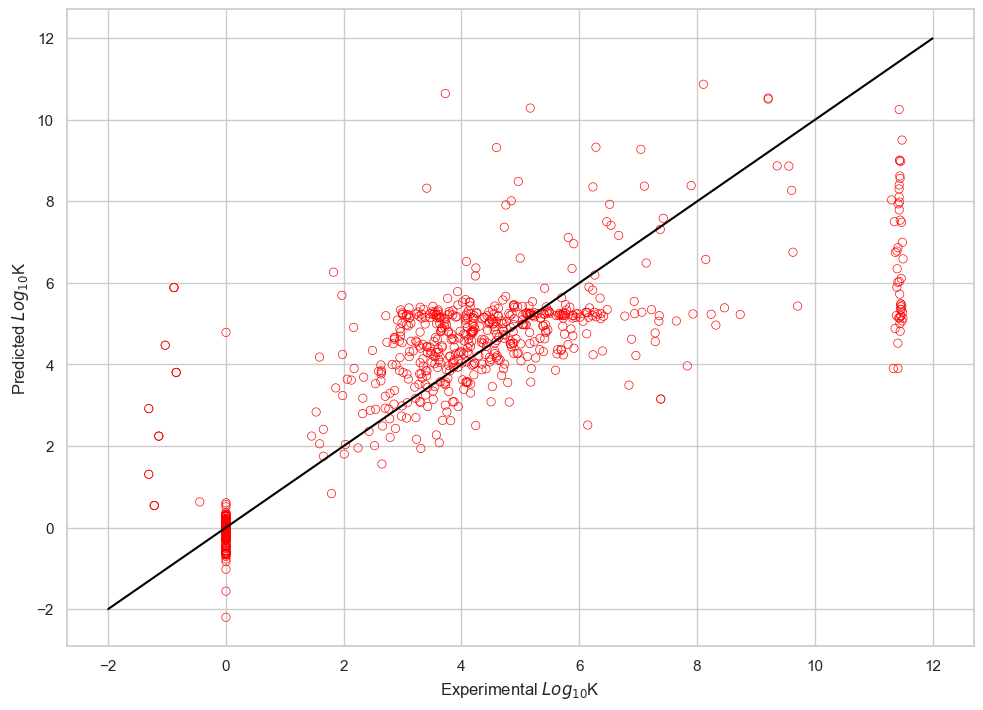

In [119]:
sns.set_style("whitegrid")
sns.scatterplot(x = y.reshape(y.shape[0]), y = y_pred_train.reshape(y_pred_train.shape[0]), facecolor="none", edgecolor="red")
sns.lineplot(x = [-2, 12], y = [-2, 12], color = "black")

plt.ylabel("Predicted $Log_{10}$K")
plt.xlabel("Experimental $Log_{10}$K")
plt.show()

In [120]:
X = K_OIL_df[["Temperature (K)","FAME/FAEE_F", "OIL_F", "ACID_F", "WATER_F", "ALCOHOL_F"]].to_numpy()
y = K_OIL_df[["K_OIL"]].to_numpy()

In [121]:
degree = 4
model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
model.fit(X, y)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=4)),
                ('linearregression', LinearRegression())])

In [122]:
y_pred_train = model.predict(X)
r2 = r2_score(y, y_pred_train)
rmse = root_mean_squared_error(y, y_pred_train)
print(f"R²: {r2:.4f}", f"RMSE: {rmse:.4f}")

R²: 0.9272 RMSE: 0.6783


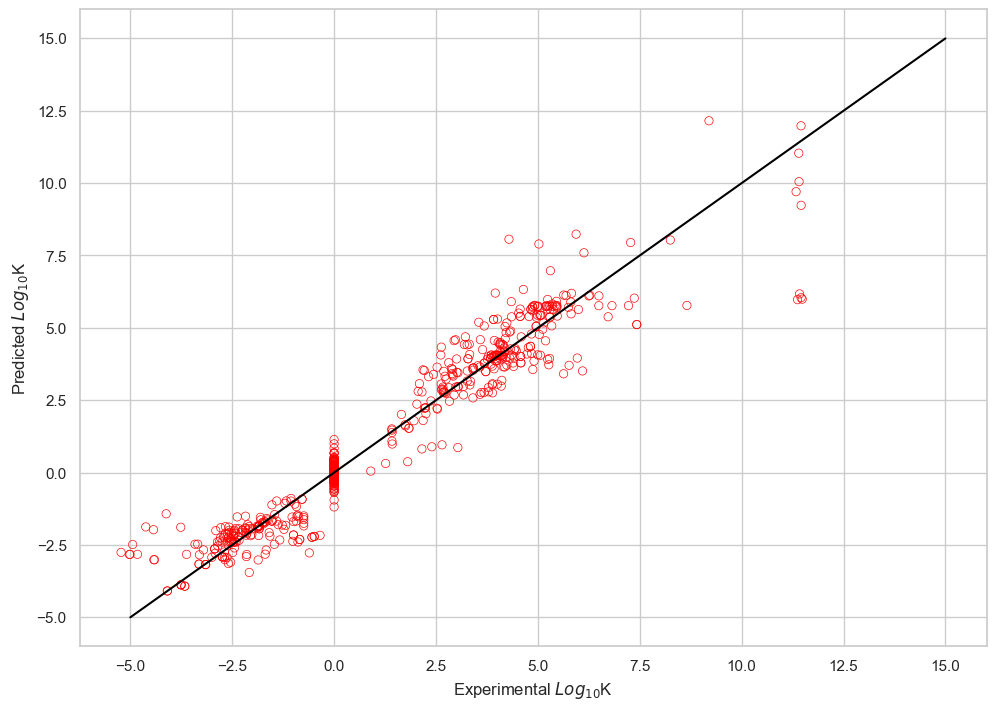

In [123]:
sns.scatterplot(x = y.reshape(y.shape[0]), y = y_pred_train.reshape(y_pred_train.shape[0]), facecolor="none", edgecolor="red")
sns.lineplot(x = [-5, 15], y = [-5, 15], color = "black")
plt.ylabel("Predicted $Log_{10}$K")
plt.xlabel("Experimental $Log_{10}$K")
plt.show()

In [124]:
joined_types_pd = joined_types.to_pandas()

In [125]:
joined_types_pd_oils = joined_types_pd[(joined_types_pd["Source"]=="Palm") | (joined_types_pd["Source"]=="Cottonseed") | (joined_types_pd["Source"]=="Corn") | (joined_types_pd["Source"]=="Soybean")]

In [126]:
joined_types_pd_oils = joined_types_pd_oils.drop(["Ref", "Sub Ref", "MAG/DAG Profile?", "Additional FAME Profile?", "Acid mix Profile?", "Source"], axis=1)


In [127]:
joined_types_pd_oils_corr = joined_types_pd_oils.corr()

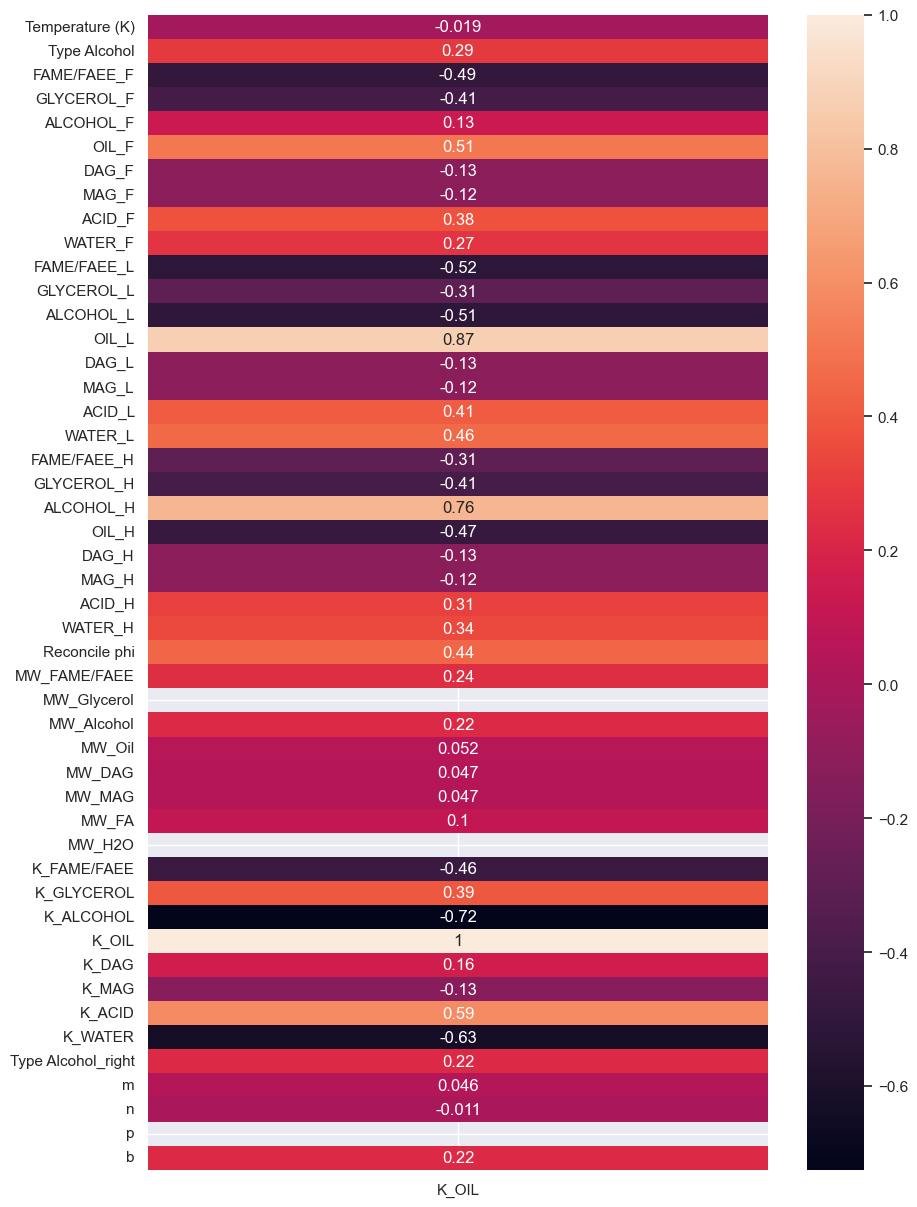

In [128]:
sns.set_theme(rc={'figure.figsize':(10, 15)})
sns.heatmap(joined_types_pd_oils_corr[["K_OIL"]], annot=True)
plt.show()

In [129]:
X = joined_types_pd_oils[["Temperature (K)","FAME/FAEE_F", "OIL_F", "ACID_F", "WATER_F"]].to_numpy()
y = joined_types_pd_oils[["K_OIL"]].to_numpy()

In [130]:
degree = 4
model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
model.fit(X, y)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=4)),
                ('linearregression', LinearRegression())])

In [131]:
y_pred_train = model.predict(X)
r2 = r2_score(y, y_pred_train)
rmse = root_mean_squared_error(y, y_pred_train)
print(f"R²: {r2:.4f}", f"RMSE: {rmse:.4f}")

R²: 0.9578 RMSE: 0.5516


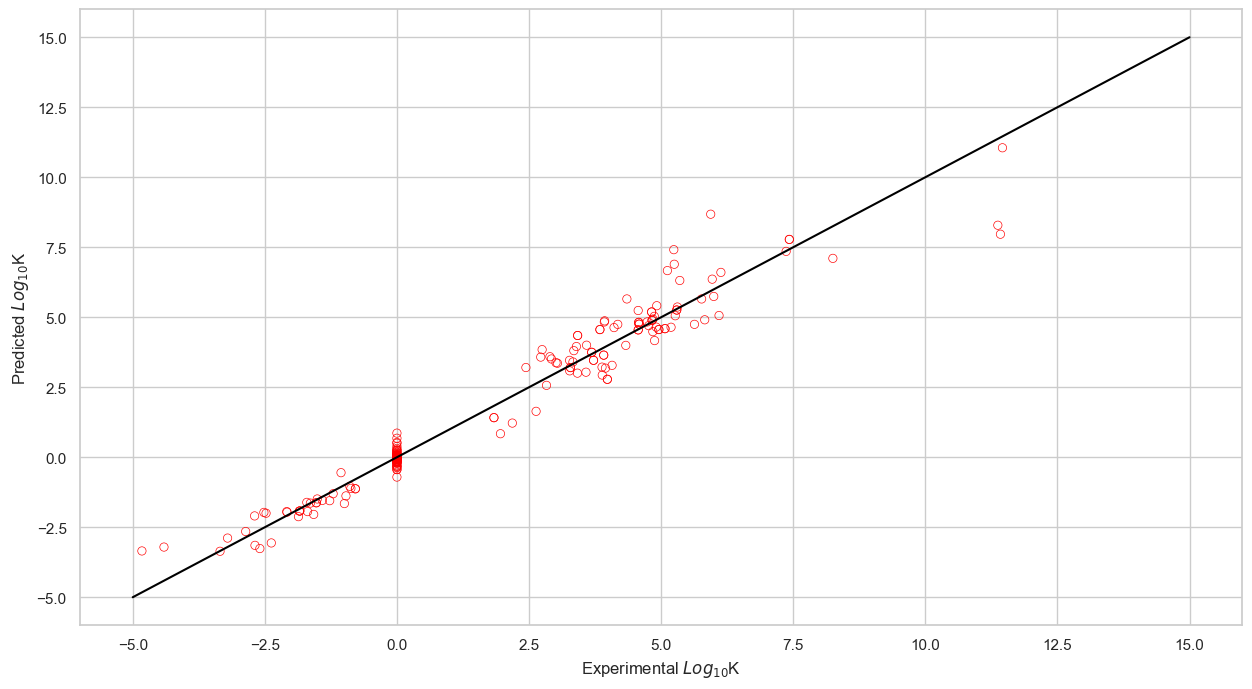

In [149]:
sns.set_theme(rc={'figure.figsize':(15,8)})
sns.set_style("whitegrid")
sns.scatterplot(x = y.reshape(y.shape[0]), y = y_pred_train.reshape(y_pred_train.shape[0]), facecolor="none", edgecolor="red")
sns.lineplot(x = [-5, 15], y = [-5, 15], color = "black")
plt.ylabel("Predicted $Log_{10}$K")
plt.xlabel("Experimental $Log_{10}$K")
plt.show()

### 5. Surface plots

In [133]:
result_np = result.drop(["Sub Ref"]).to_numpy()


In [134]:
surface_plot(result_np[0:499, 1], result_np[0:499, 29], result_np[0:499, 11], "Experimental Distribution FAME", "Temperature (K)", "MW FAME/FAEE", "FAME/FAEE $w^I$", "FAME/FAEE $w^I$")

QhullError: QH6154 Qhull precision error: Initial simplex is flat (facet 1 is coplanar with the interior point)

While executing:  | qhull d Qz Qt Qbb Q12 Qc
Options selected for Qhull 2019.1.r 2019/06/21:
  run-id 2118180077  delaunay  Qz-infinity-point  Qtriangulate  Qbbound-last
  Q12-allow-wide  Qcoplanar-keep  _pre-merge  _zero-centrum  Qinterior-keep
  Pgood  _max-width 60  Error-roundoff 4.9e-13  _one-merge 3.4e-12
  Visible-distance 9.8e-13  U-max-coplanar 9.8e-13  Width-outside 2e-12
  _wide-facet 5.9e-12  _maxoutside 3.9e-12

The input to qhull appears to be less than 3 dimensional, or a
computation has overflowed.

Qhull could not construct a clearly convex simplex from points:
- p7(v4): 3.1e+02    92    82
- p499(v3): 3.1e+02    92 3.5e+02
- p144(v2): 3.5e+02    92 2.6e+02
- p3(v1): 2.9e+02    92     0

The center point is coplanar with a facet, or a vertex is coplanar
with a neighboring facet.  The maximum round off error for
computing distances is 4.9e-13.  The center poi

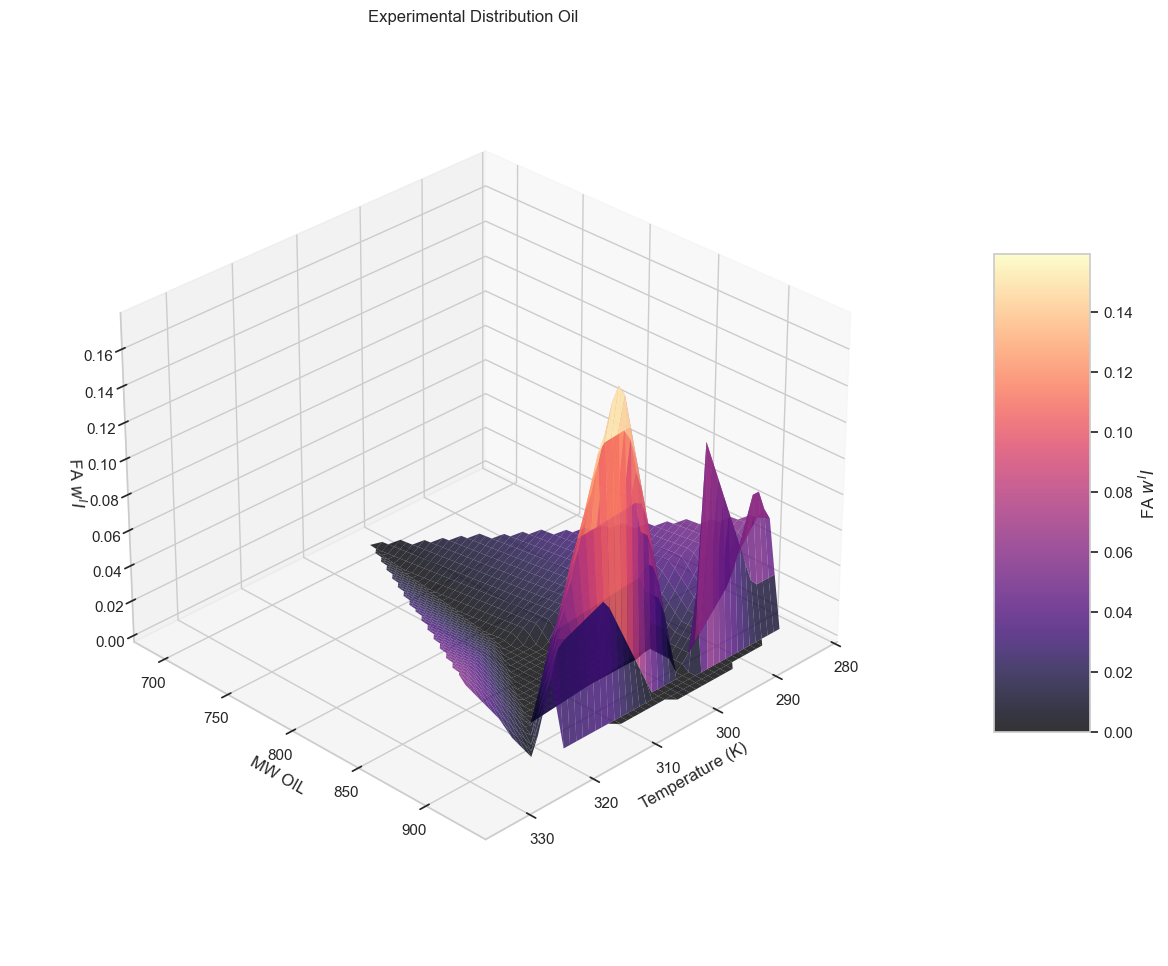

In [ ]:
surface_plot(result_np[499:898, 1], result_np[499:898, 32], result_np[499:898, 26], "Experimental Distribution Oil", "Temperature (K)", "MW OIL", " FA $w^II$", "FA $w^II$")